In [14]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
})


02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11000_0.70_0.70_0.70
11015.822


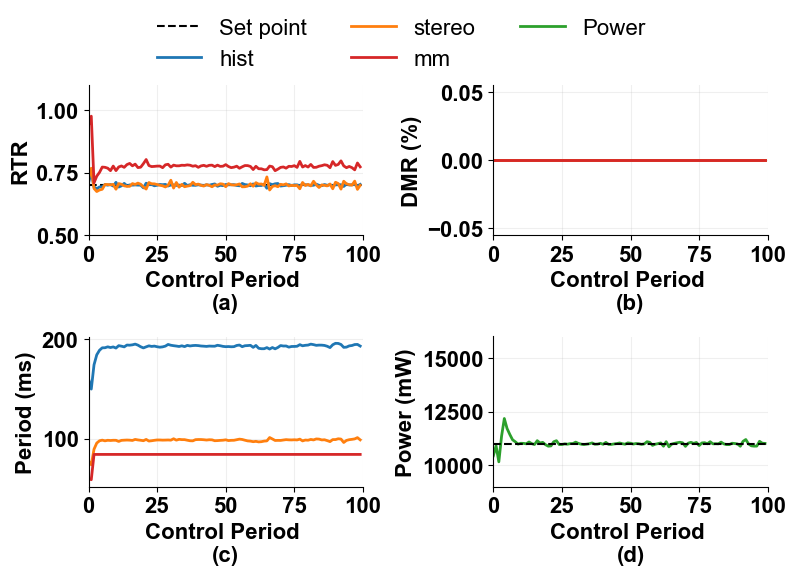

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11500_0.70_0.70_0.70
11517.398000000001


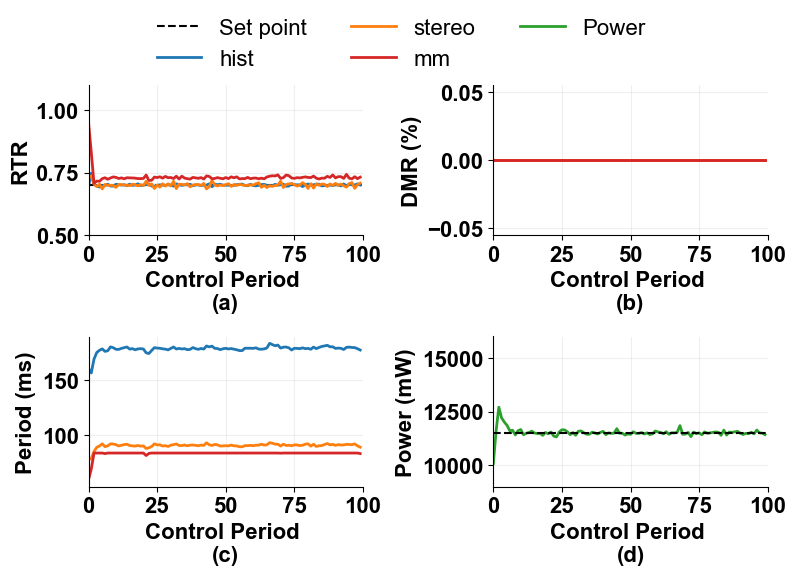

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12000_0.70_0.70_0.70
11954.7957


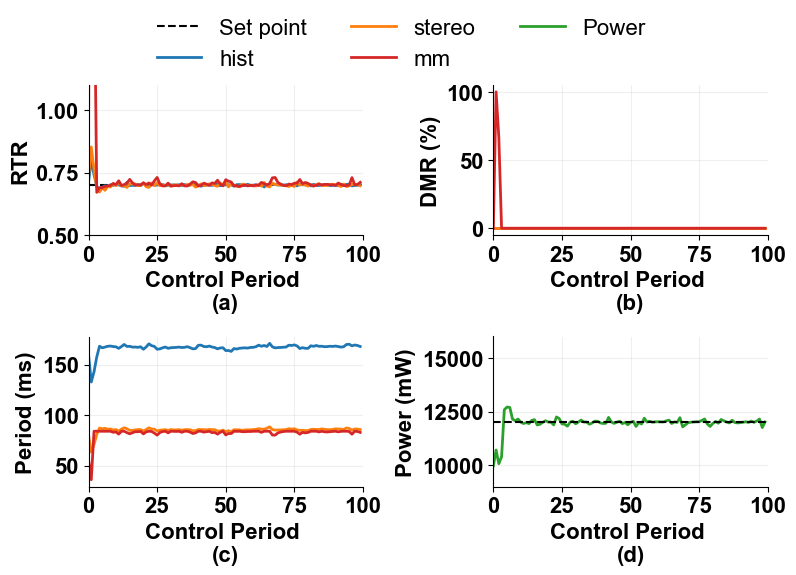

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12500_0.70_0.70_0.70
12445.552999999998


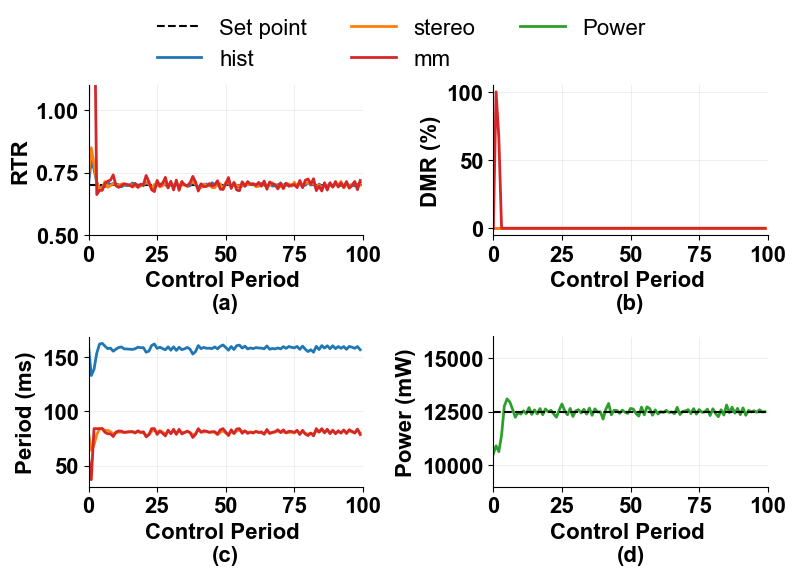

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_13000_0.70_0.70_0.70
12847.970500000001


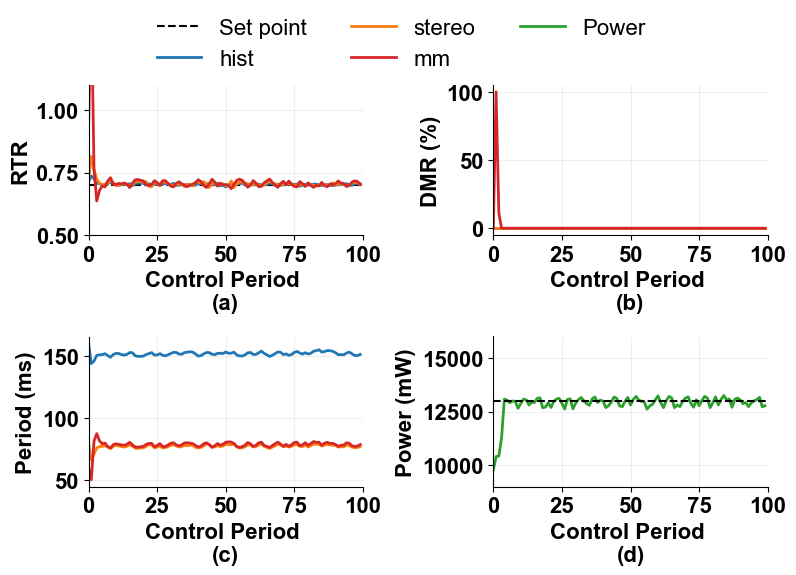

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11000_0.75_0.75_0.75
11019.633


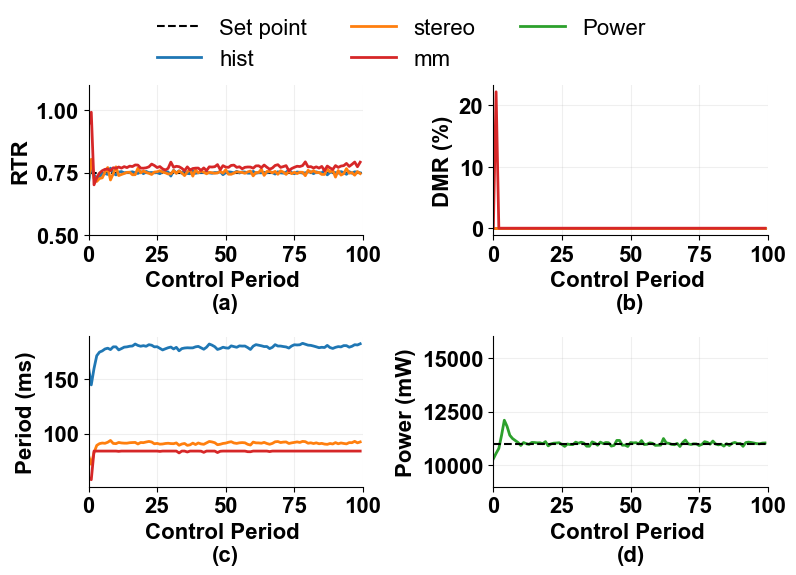

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11500_0.75_0.75_0.75
11482.466999999999


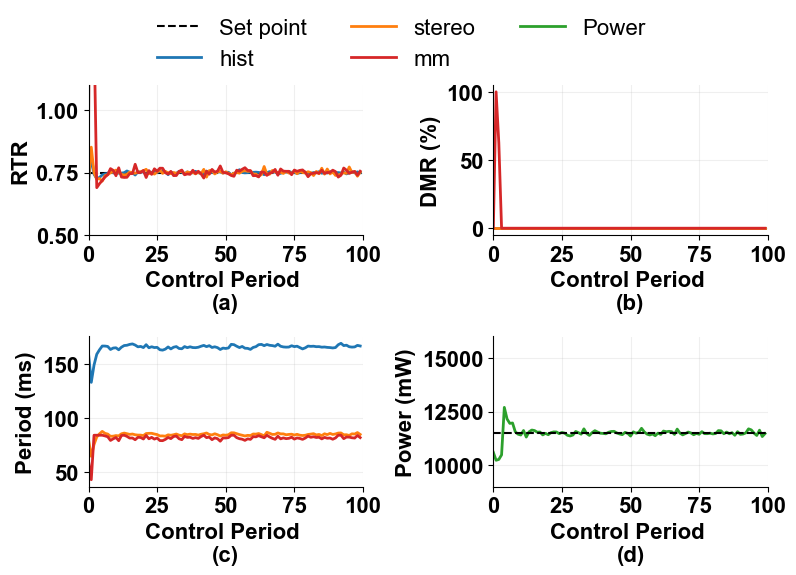

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12000_0.75_0.75_0.75
11962.1325


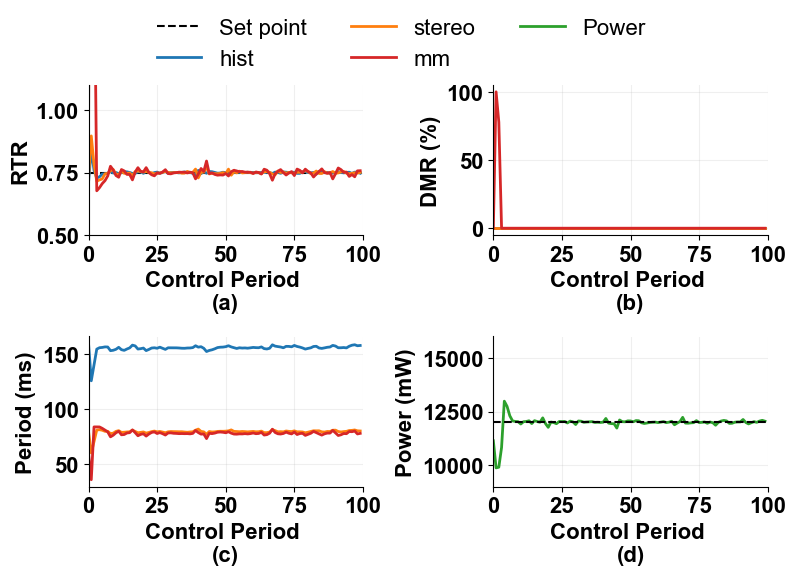

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12500_0.75_0.75_0.75
12435.2748


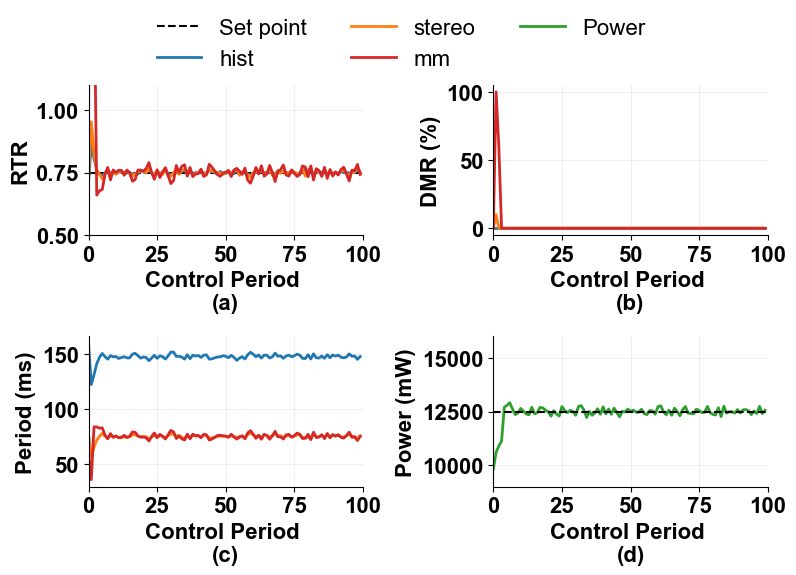

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75
12880.326000000001


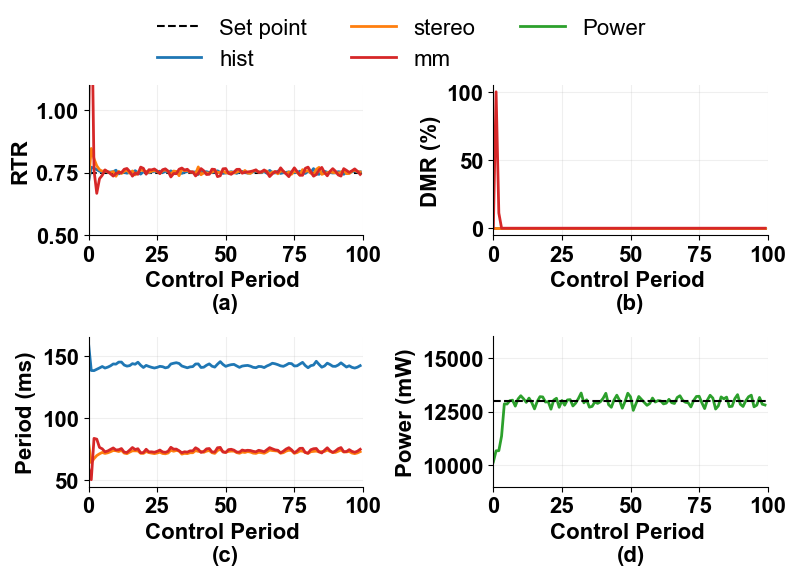

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11000_0.80_0.80_0.80
11011.848999999998


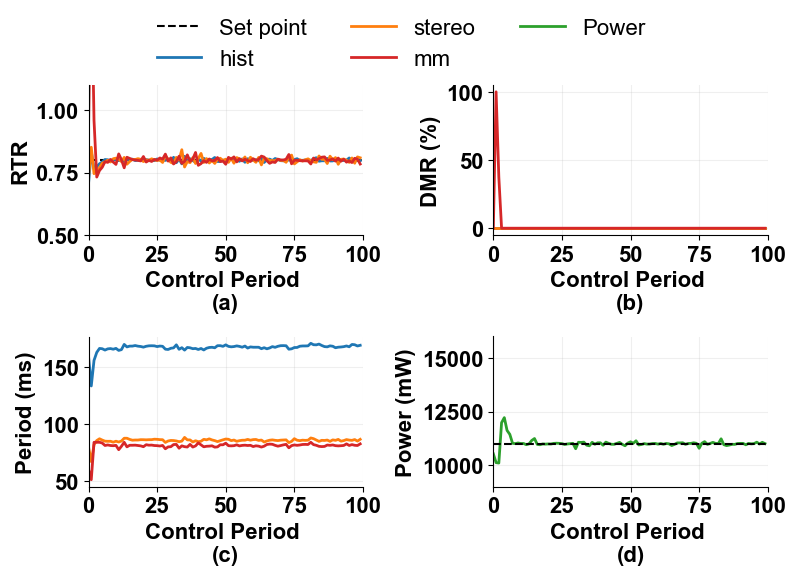

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11500_0.80_0.80_0.80
11503.5432


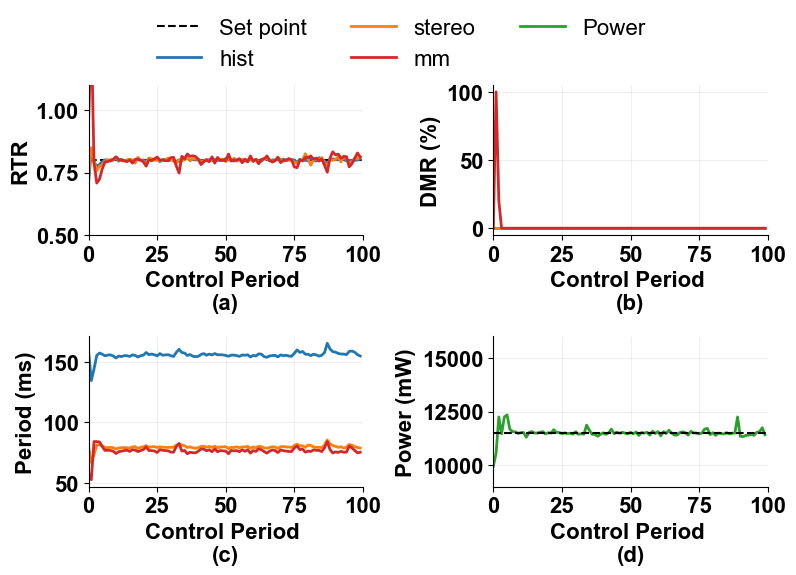

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12000_0.80_0.80_0.80
11962.244


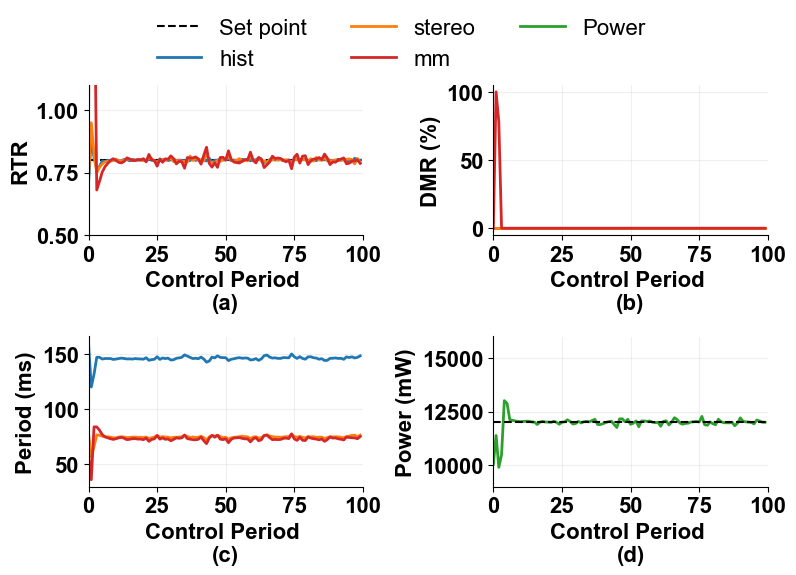

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12500_0.80_0.80_0.80
12423.460500000001


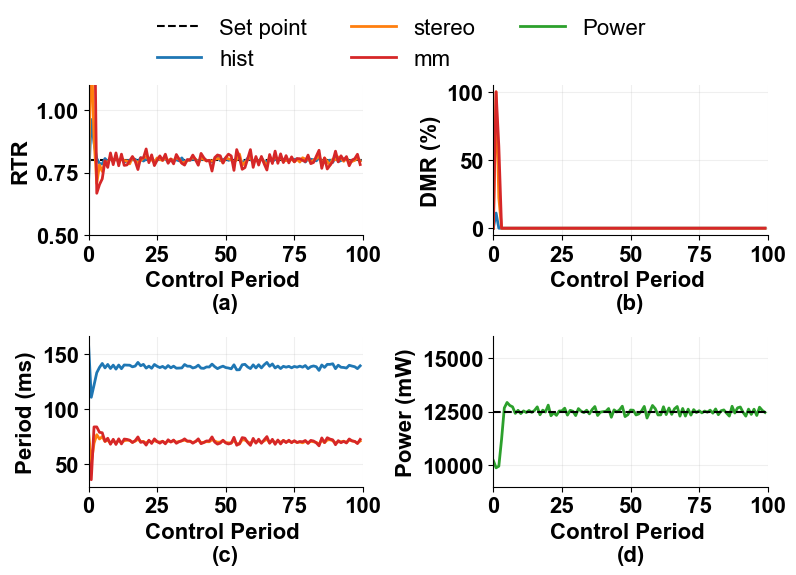

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_13000_0.80_0.80_0.80
12890.3375


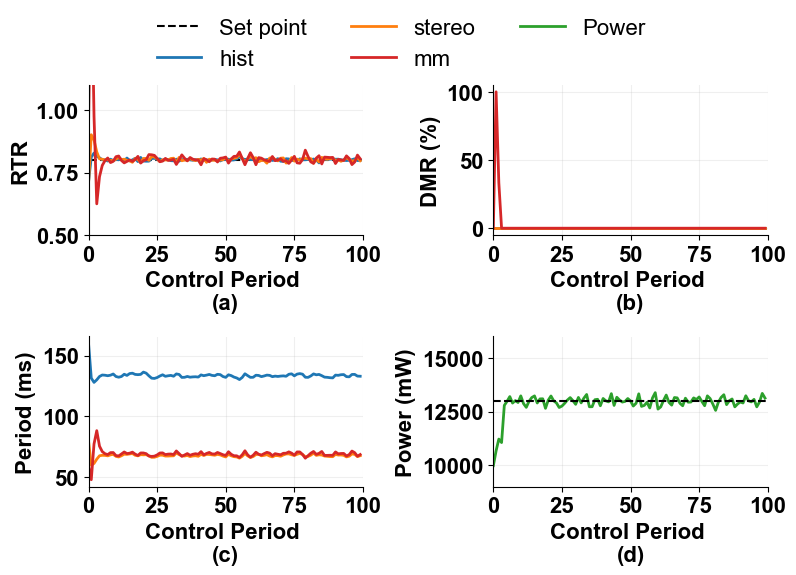

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11000_0.85_0.85_0.85
11018.045999999998


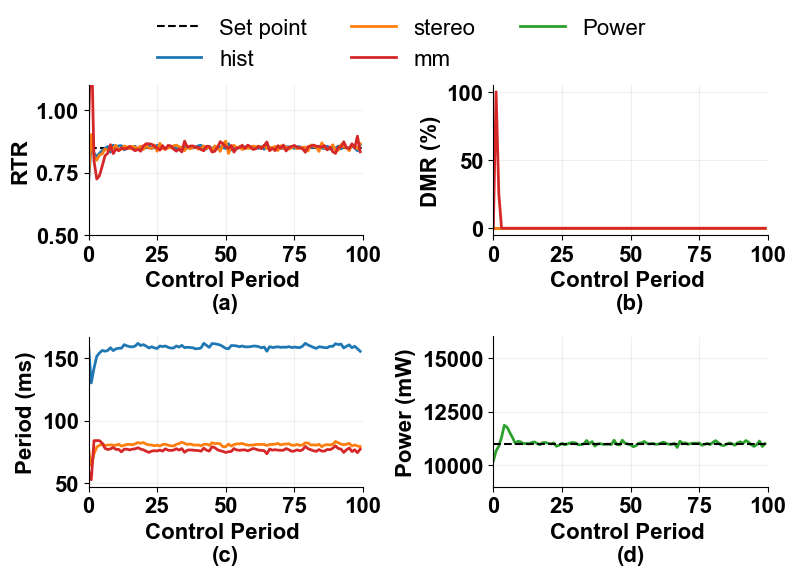

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11500_0.85_0.85_0.85
11486.8769


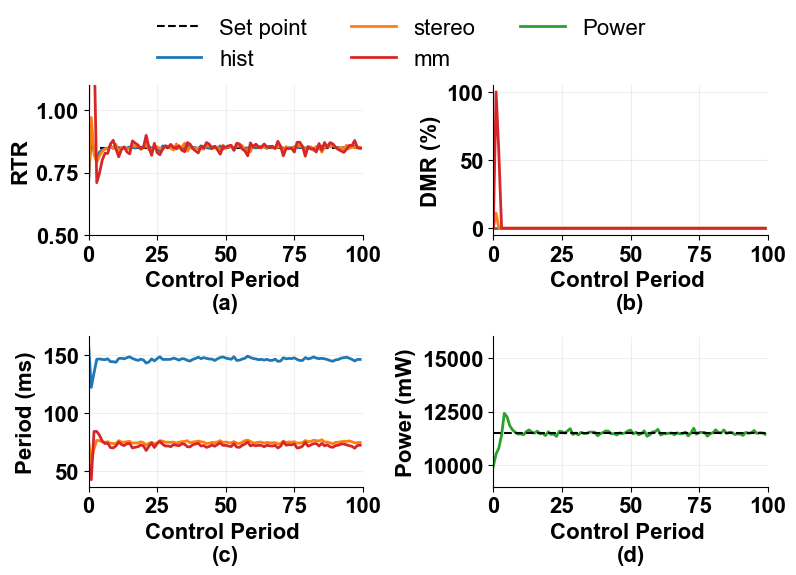

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12000_0.85_0.85_0.85
11980.1239


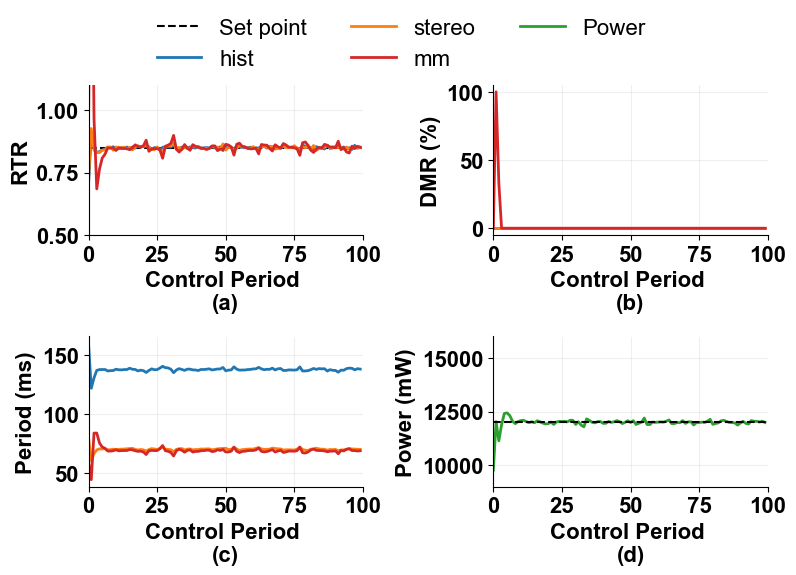

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12500_0.85_0.85_0.85
12440.3583


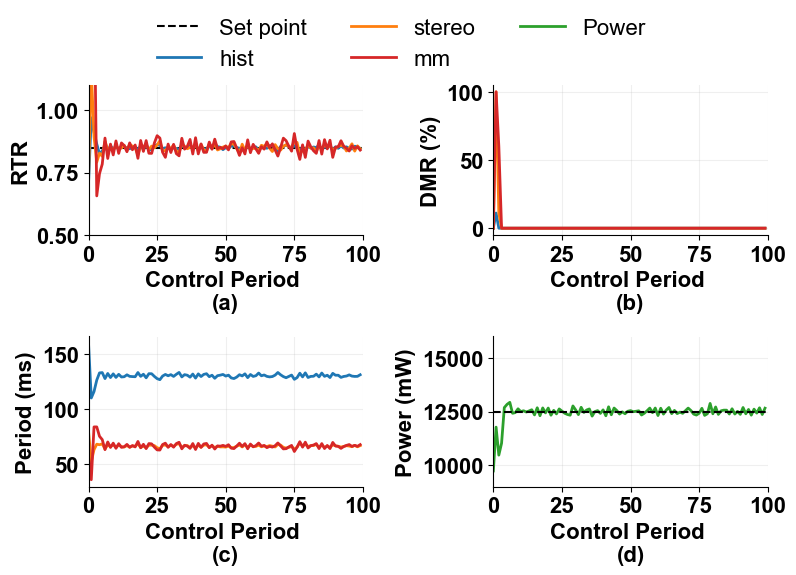

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_13000_0.85_0.85_0.85
12872.719


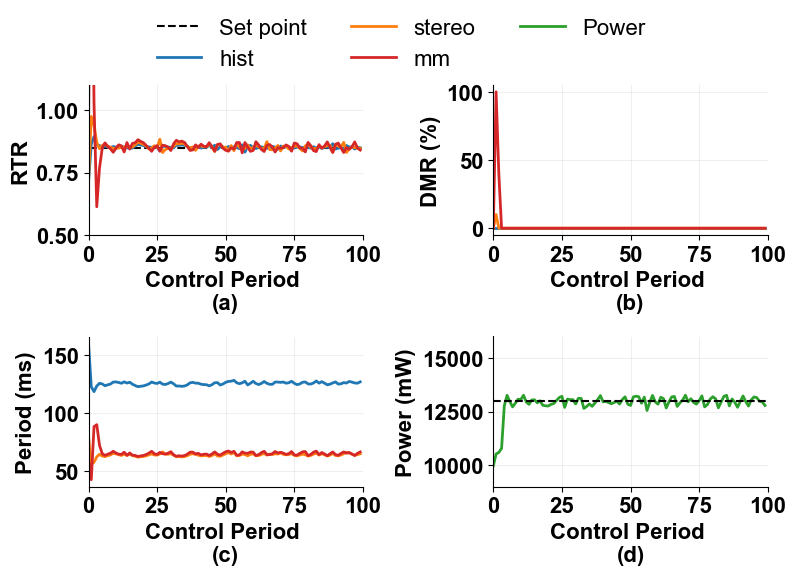

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
11013.384000000002


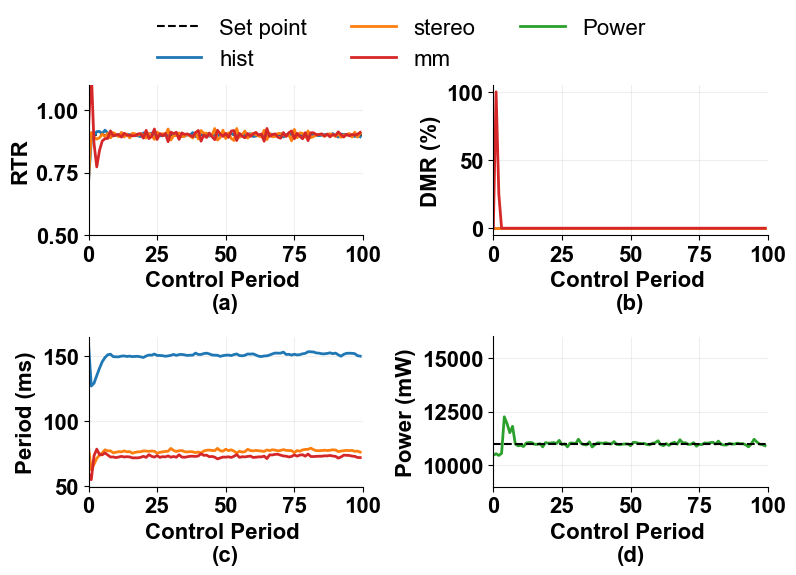

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_11500_0.90_0.90_0.90
11484.78


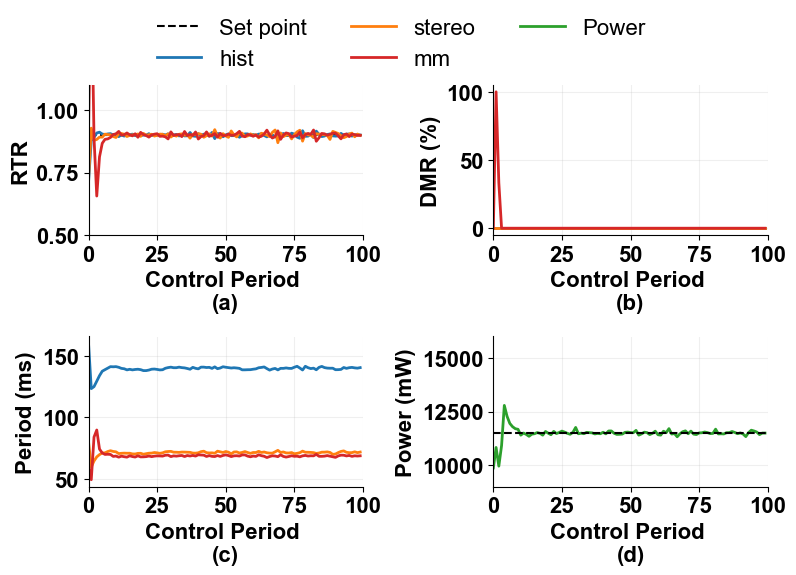

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12000_0.90_0.90_0.90
11956.3335


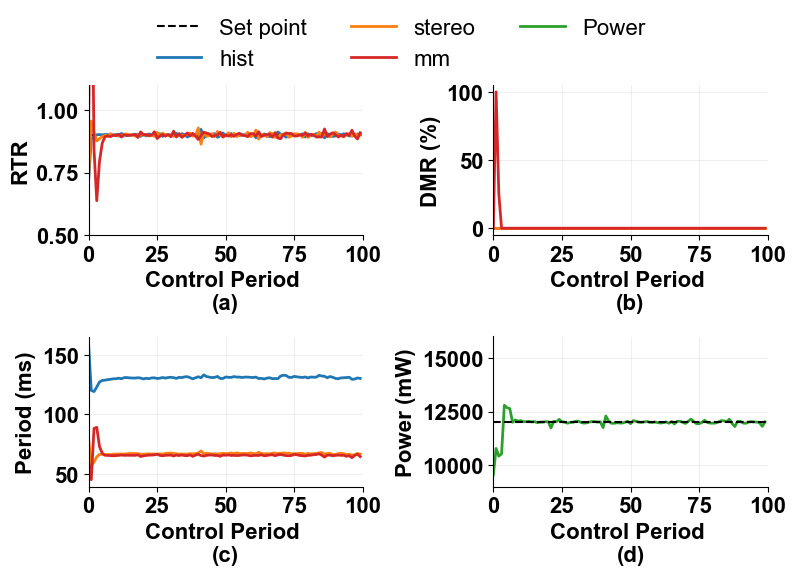

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_12500_0.90_0.90_0.90
12418.124


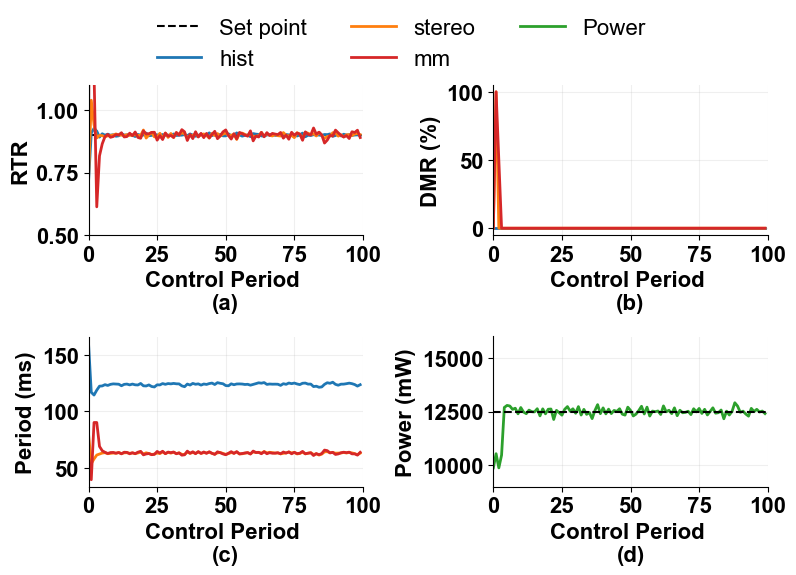

02_regular_tests\logs\Full_LQR\hist_stereo_mm\setpoint_13000_0.90_0.90_0.90
12849.735000000002


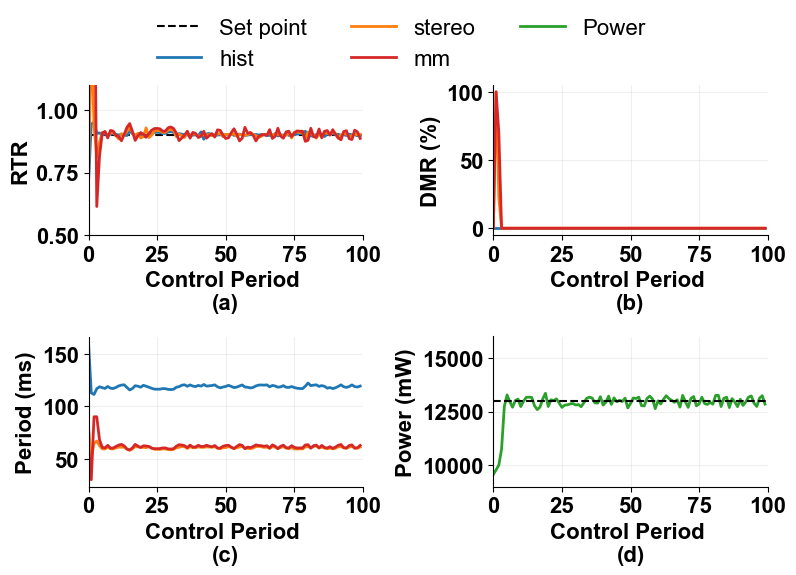

In [16]:
################FULL LQR
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
p_setpoint = [11000, 11500, 12000, 12500, 13000]
warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/Full_LQR")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"LQR_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"LQR_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "LQR_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")
        ax.set_ylim([9000,16000])

        # Global Styling
        for ax in axs:
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3,
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        
        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"LQR_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11000_0.70_0.70_0.70
10489.4095


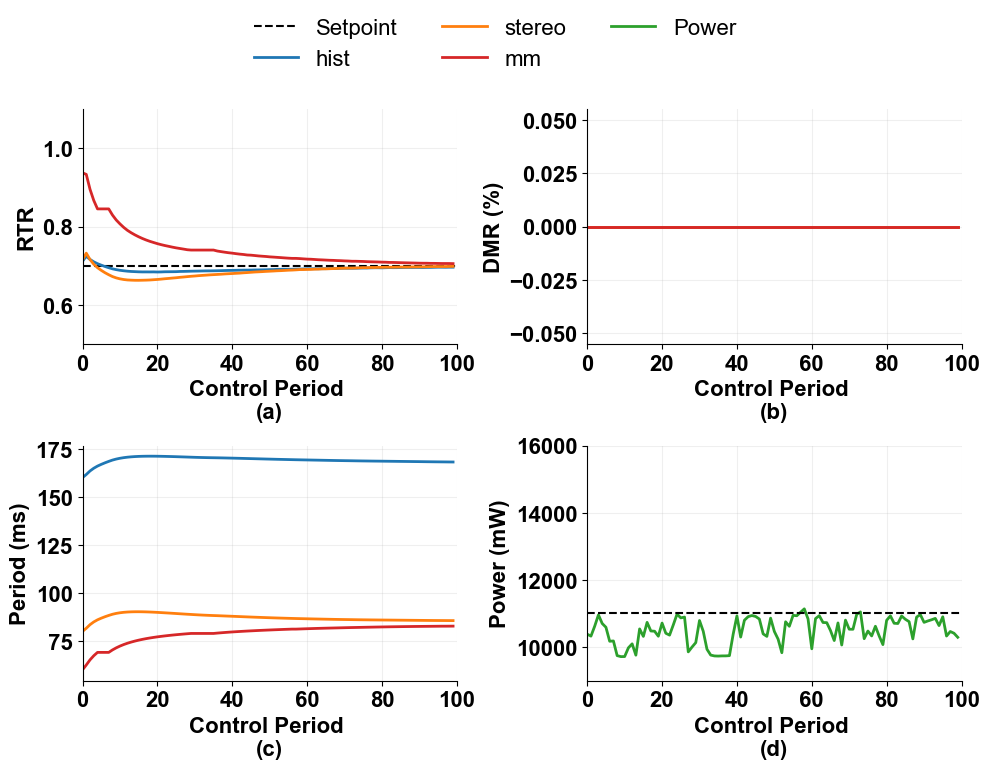

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11500_0.70_0.70_0.70
10405.9325


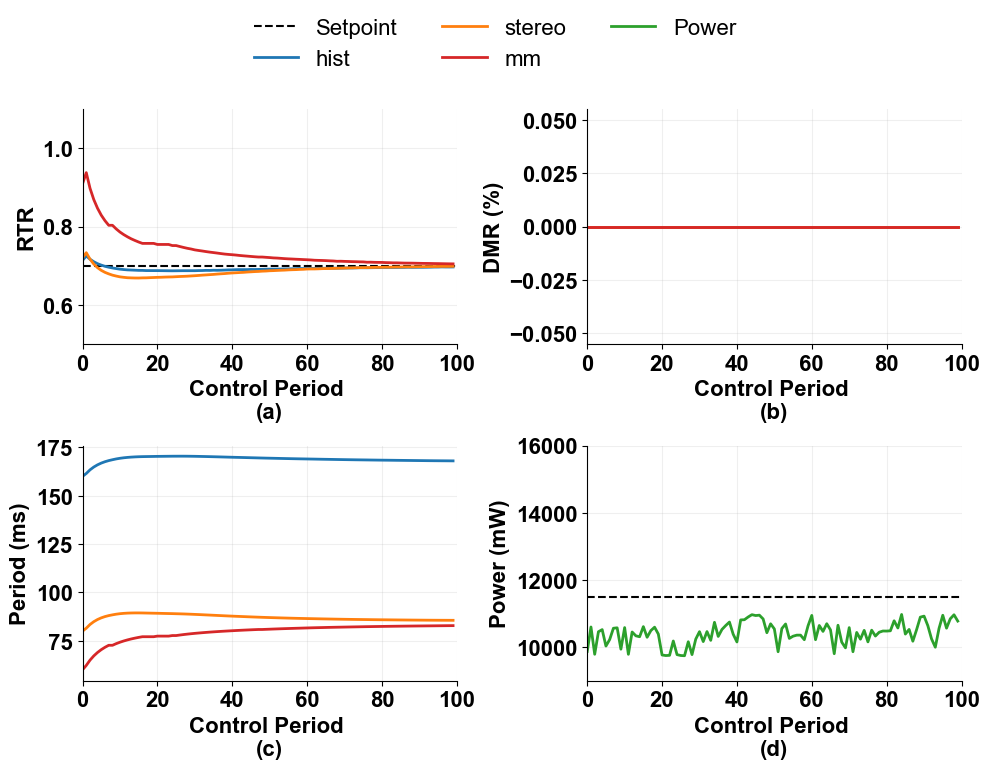

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12000_0.70_0.70_0.70
10450.303


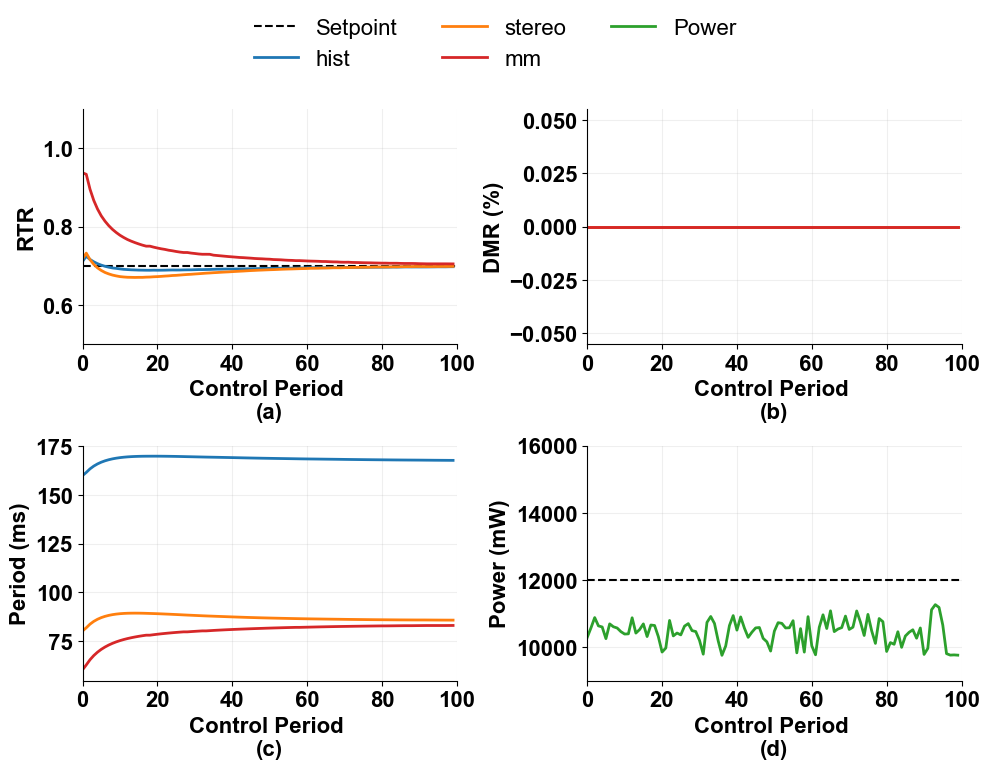

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12500_0.70_0.70_0.70
10384.9585


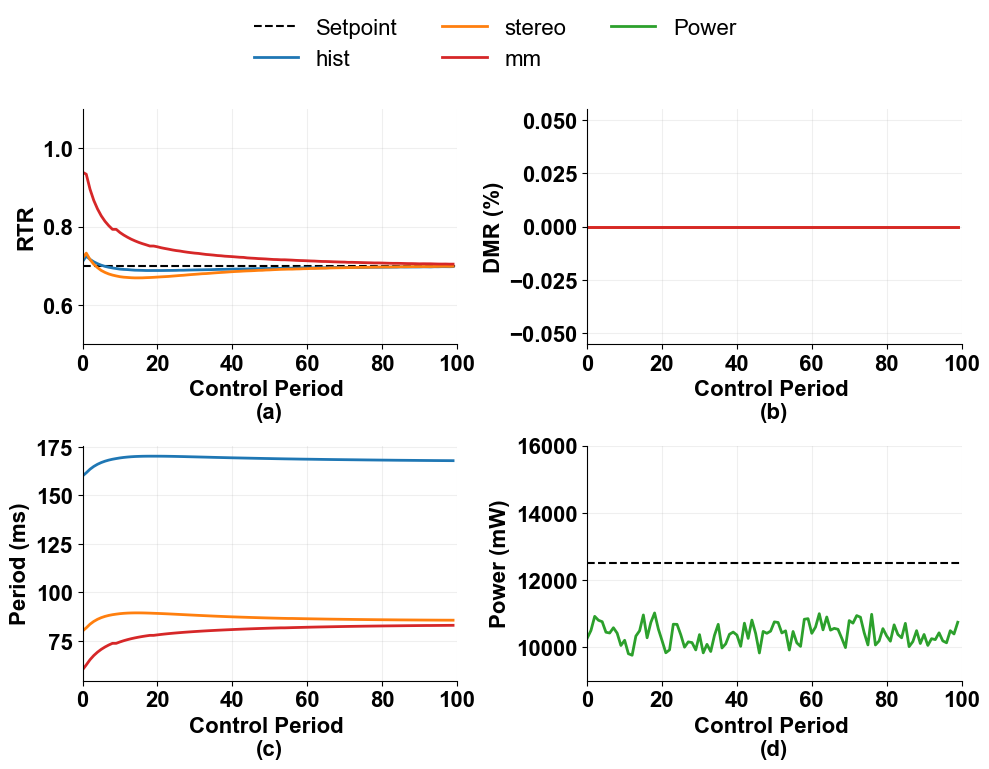

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.70_0.70_0.70
10368.488


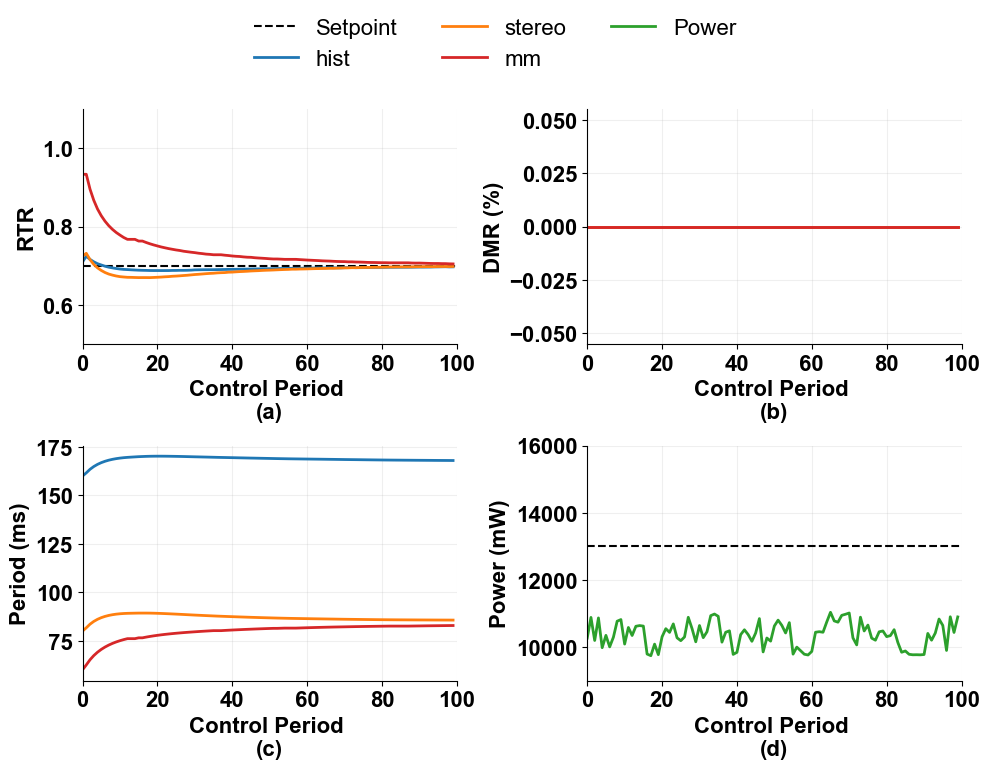

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11000_0.75_0.75_0.75
10414.3625


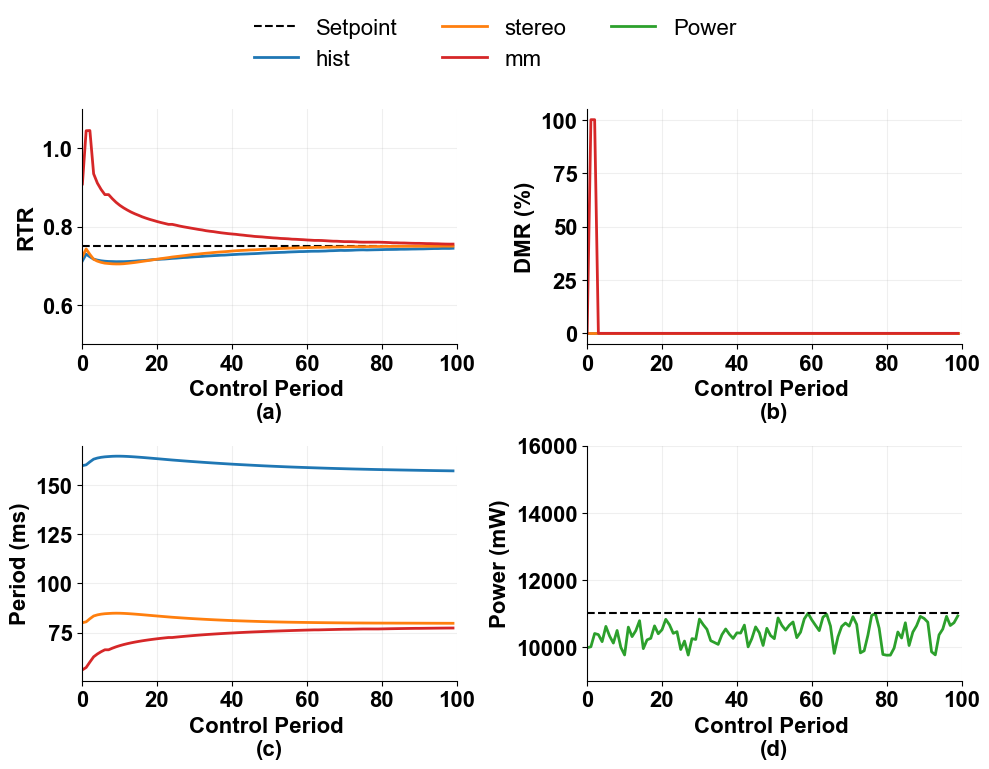

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11500_0.75_0.75_0.75
10356.8325


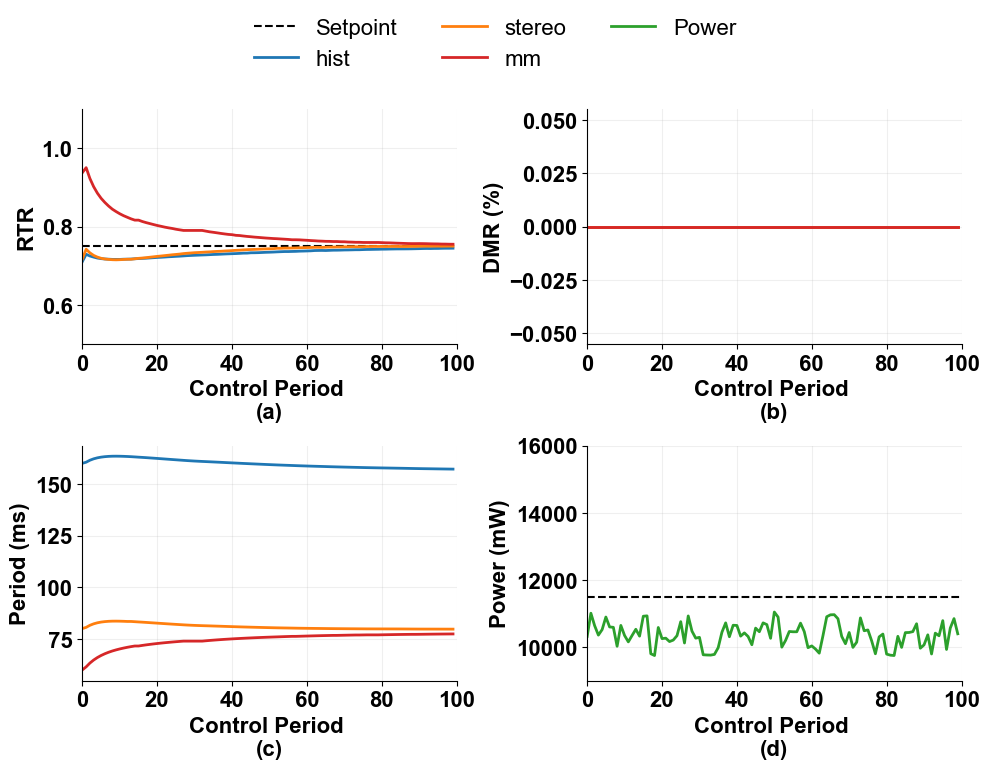

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12000_0.75_0.75_0.75
10352.339999999998


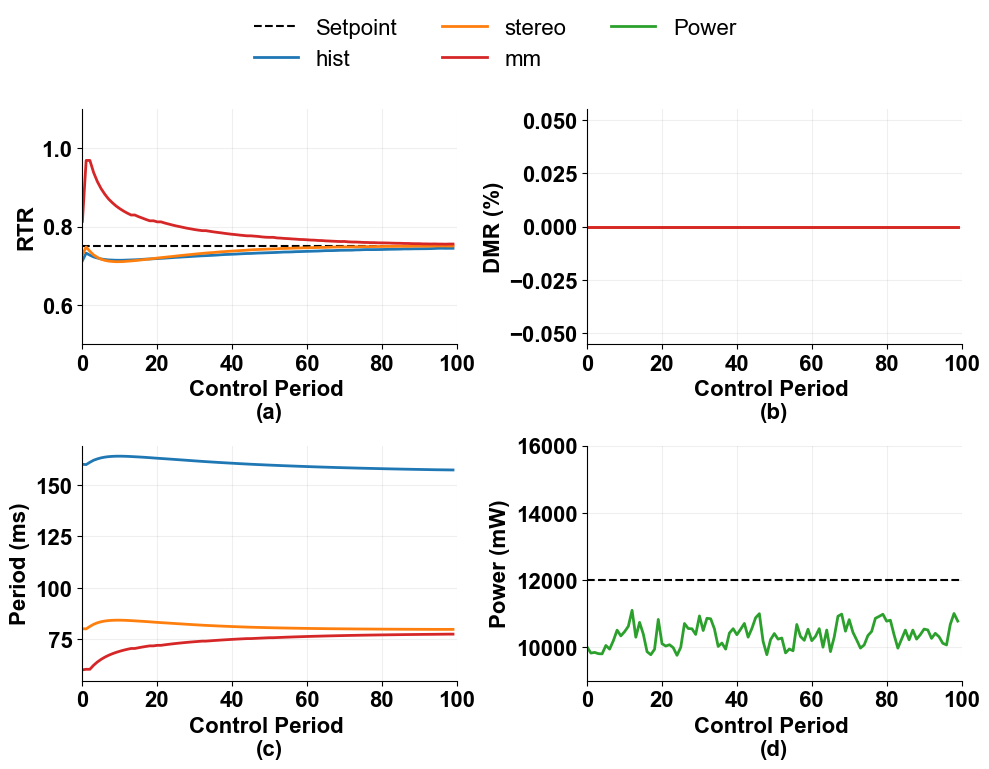

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12500_0.75_0.75_0.75
10354.4955


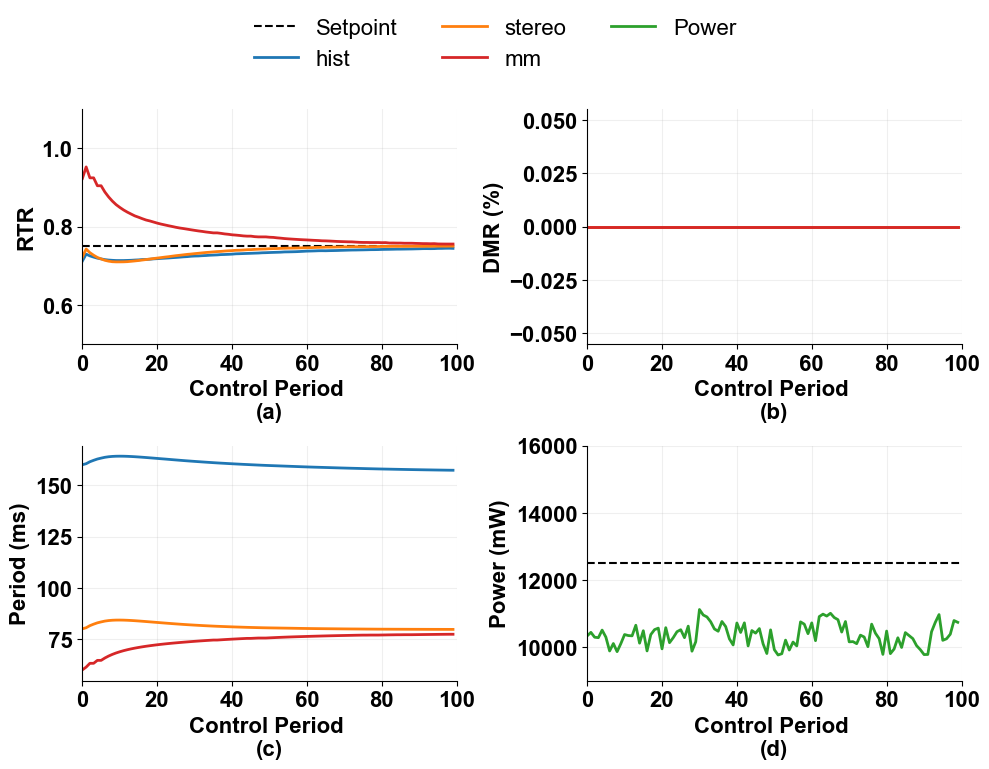

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75
10428.4505


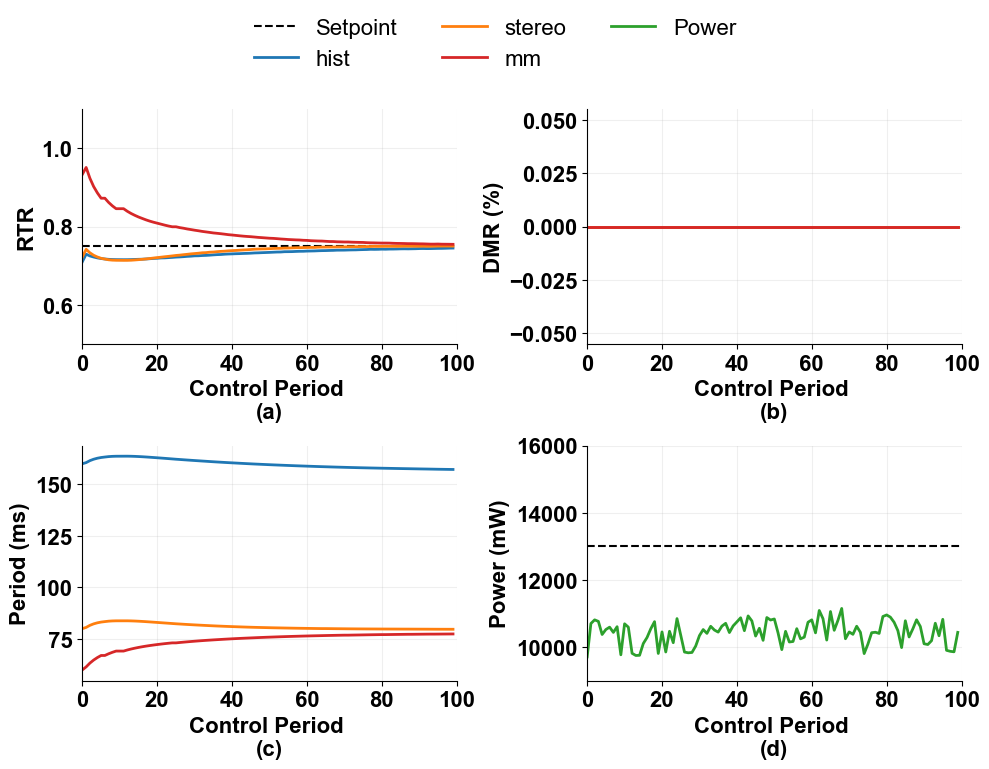

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11000_0.80_0.80_0.80
10458.3075


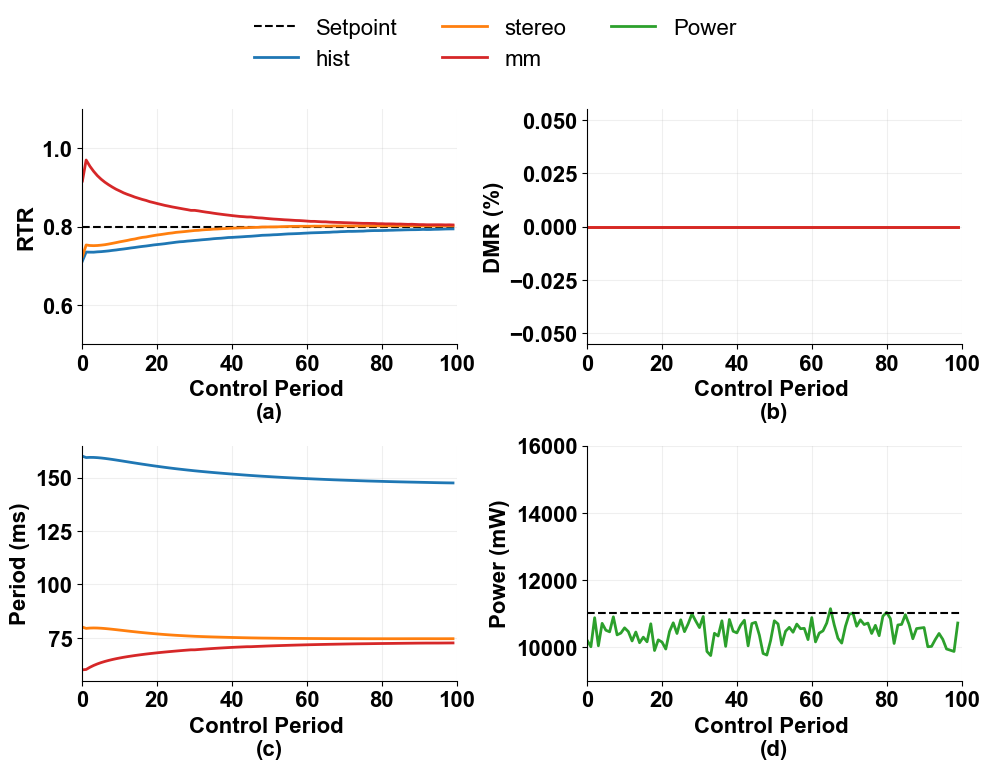

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11500_0.80_0.80_0.80
10405.630000000001


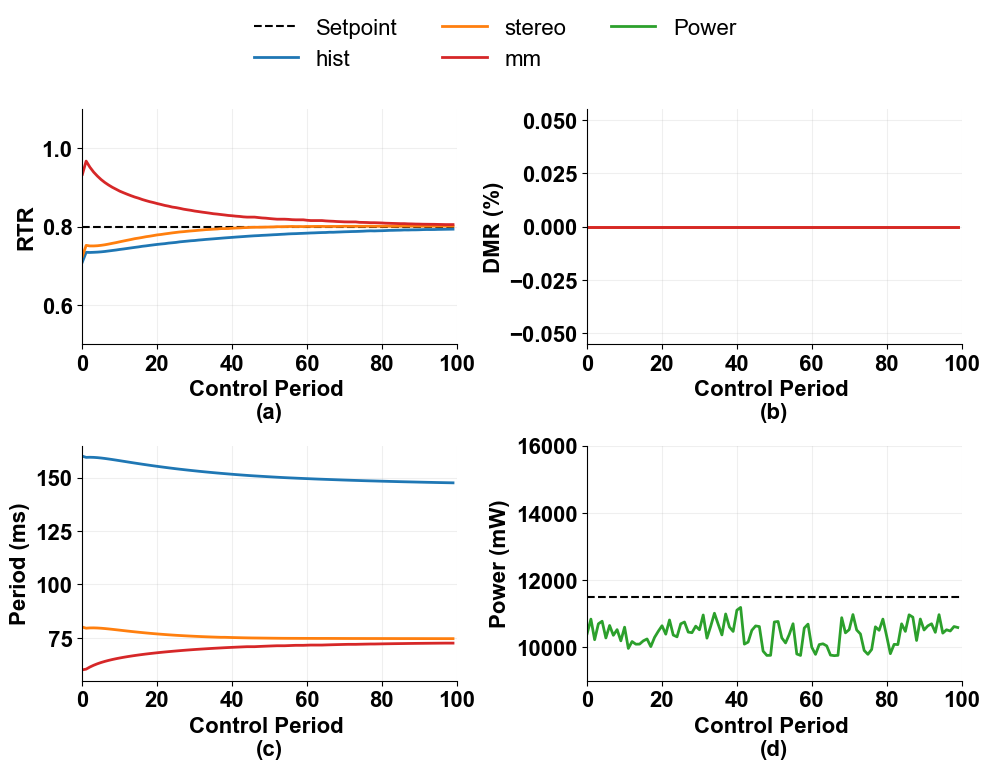

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12000_0.80_0.80_0.80
10461.761999999999


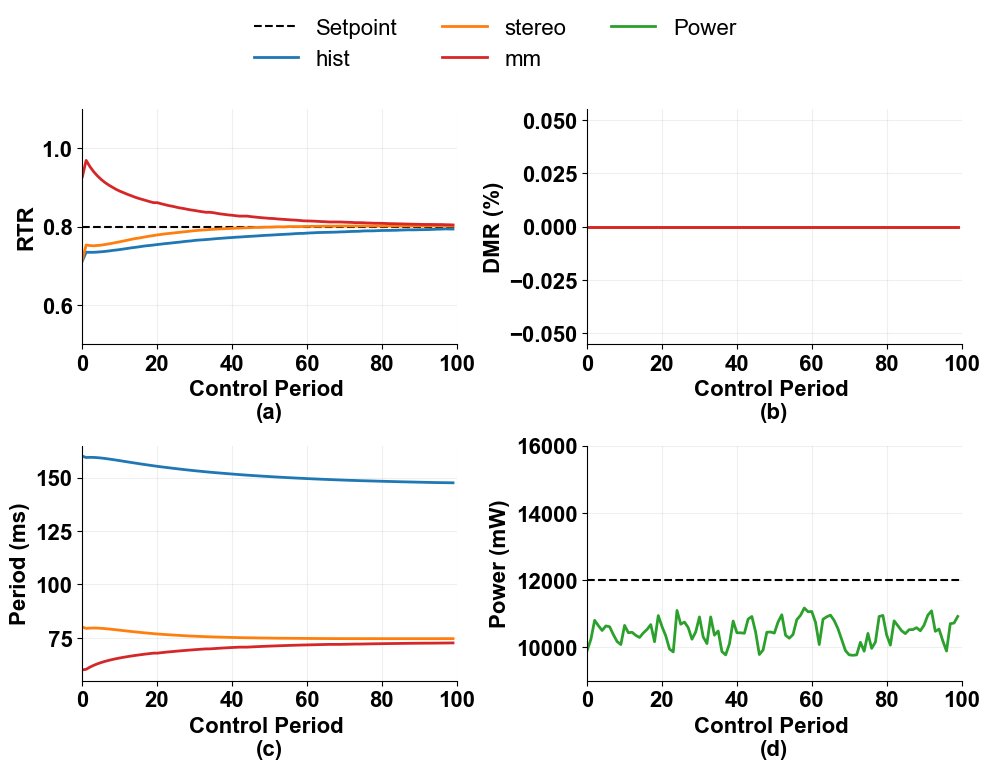

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12500_0.80_0.80_0.80
10332.811000000002


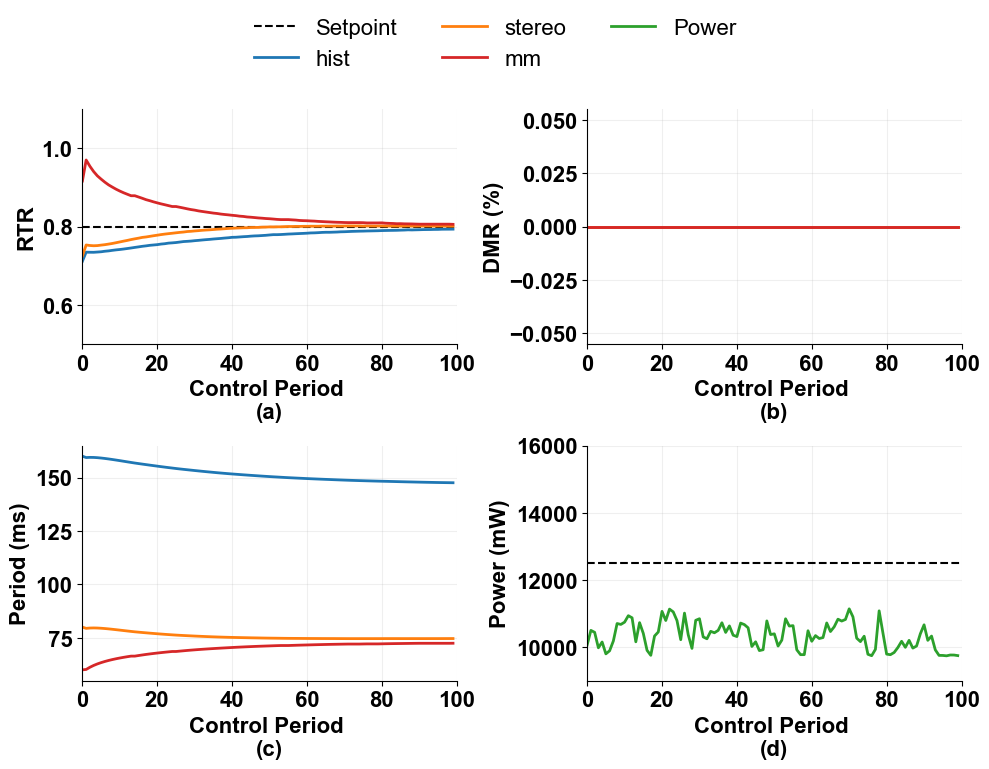

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.80_0.80_0.80
10537.163


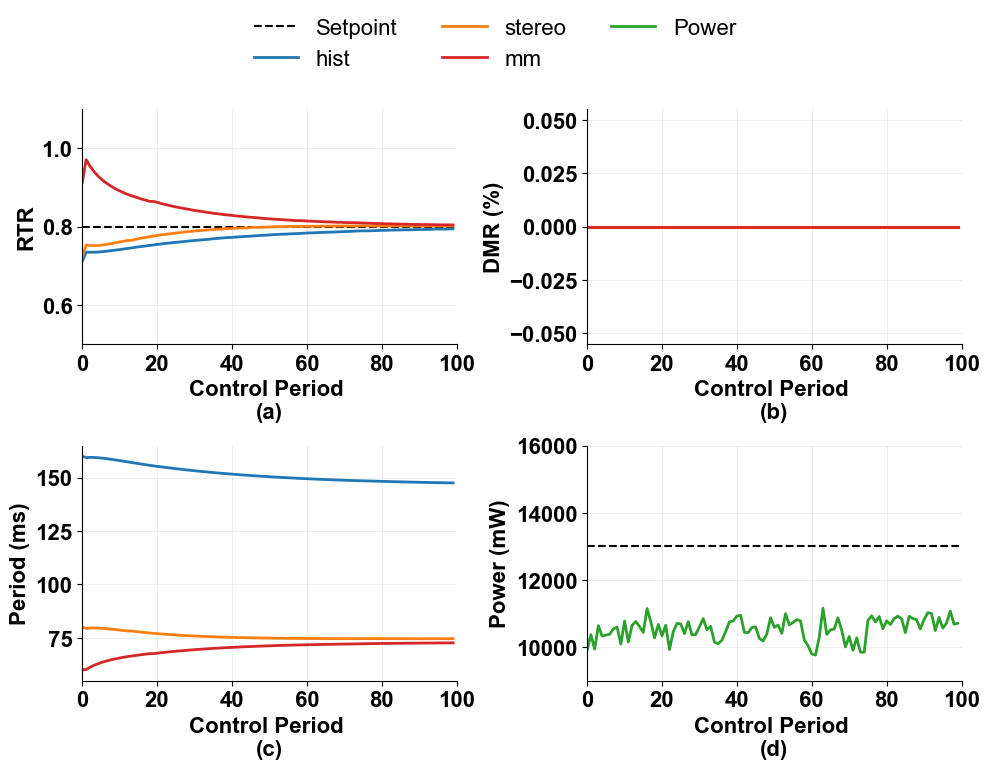

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11000_0.85_0.85_0.85
10402.959


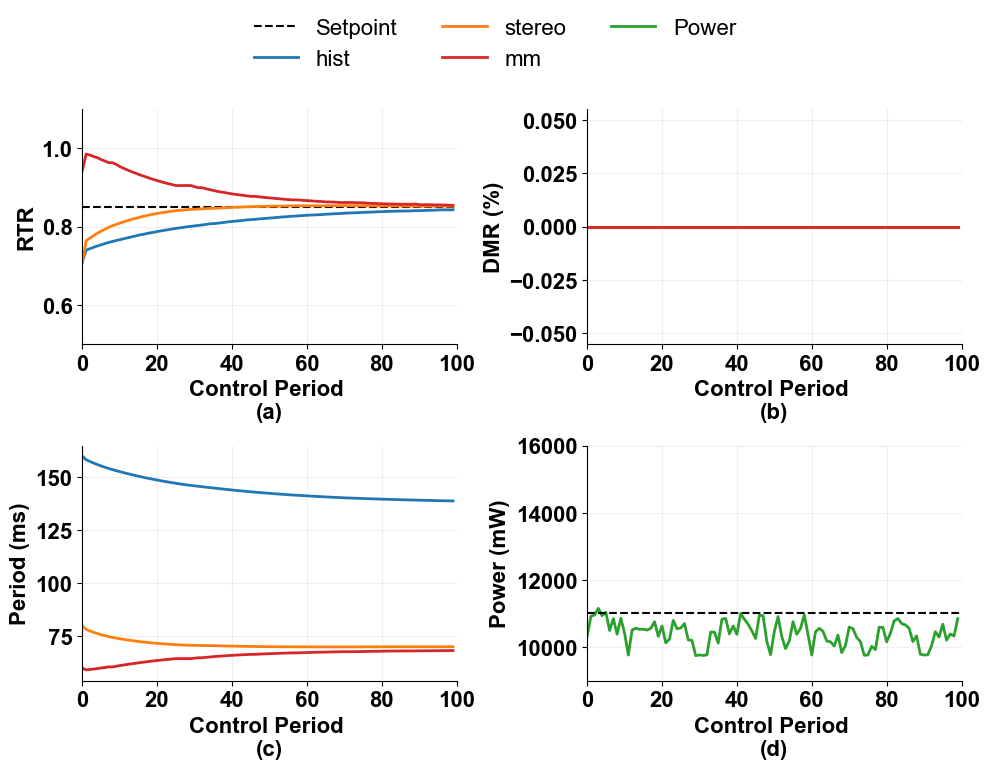

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11500_0.85_0.85_0.85
10400.207


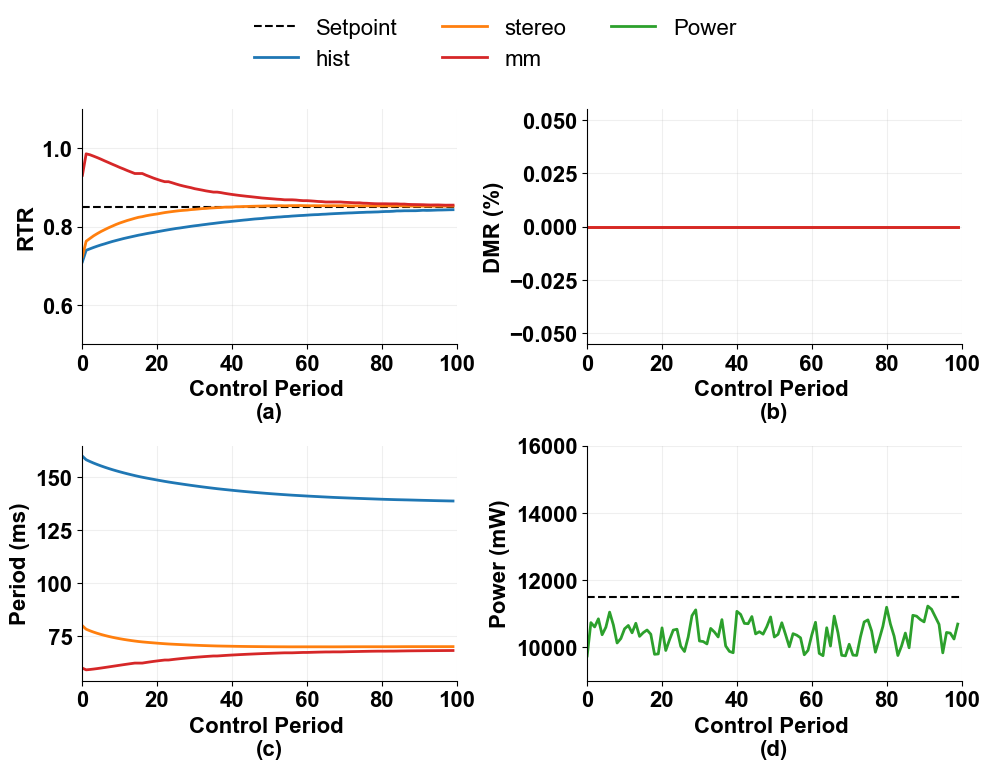

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12000_0.85_0.85_0.85
10453.920499999998


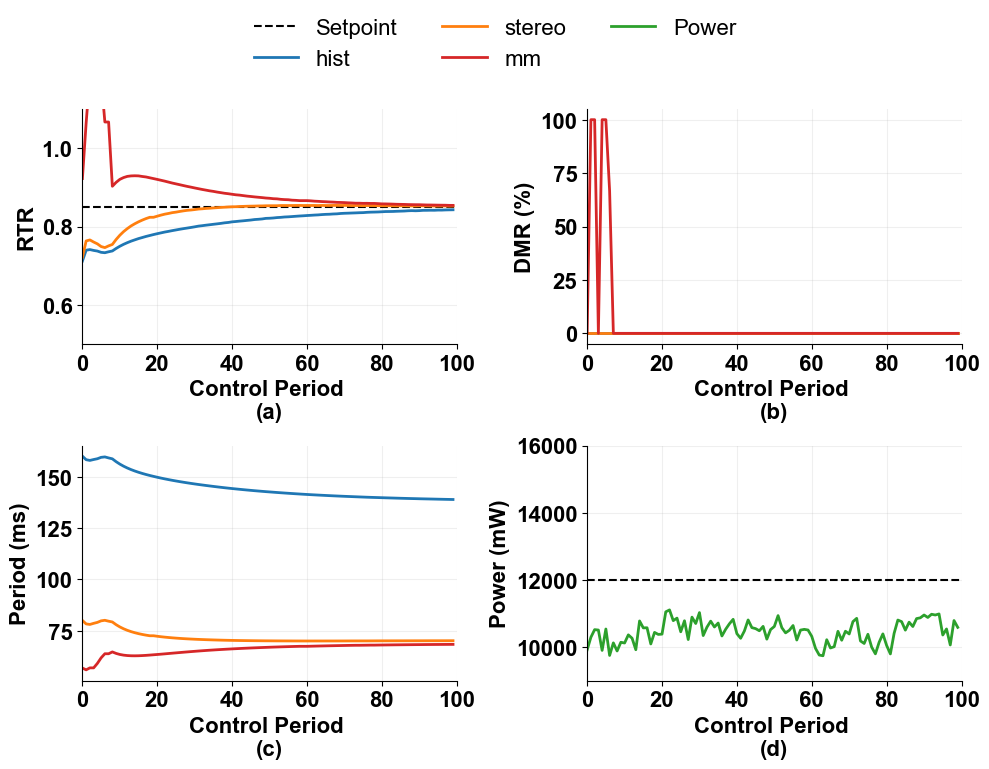

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12500_0.85_0.85_0.85
10384.0925


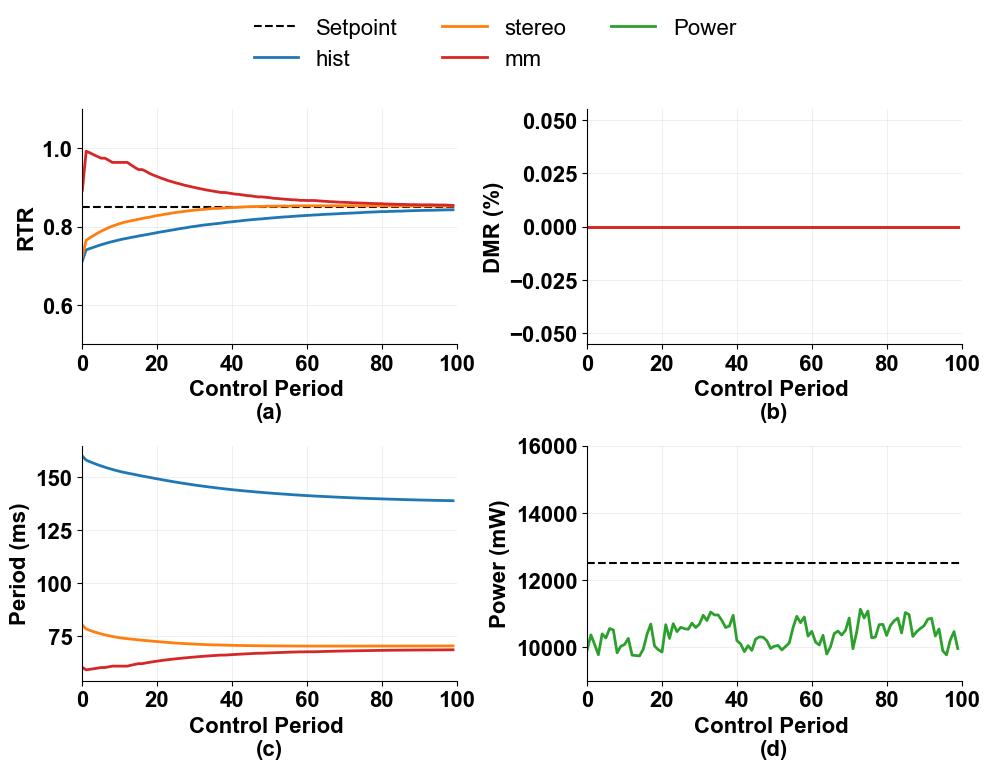

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.85_0.85_0.85
10494.381500000001


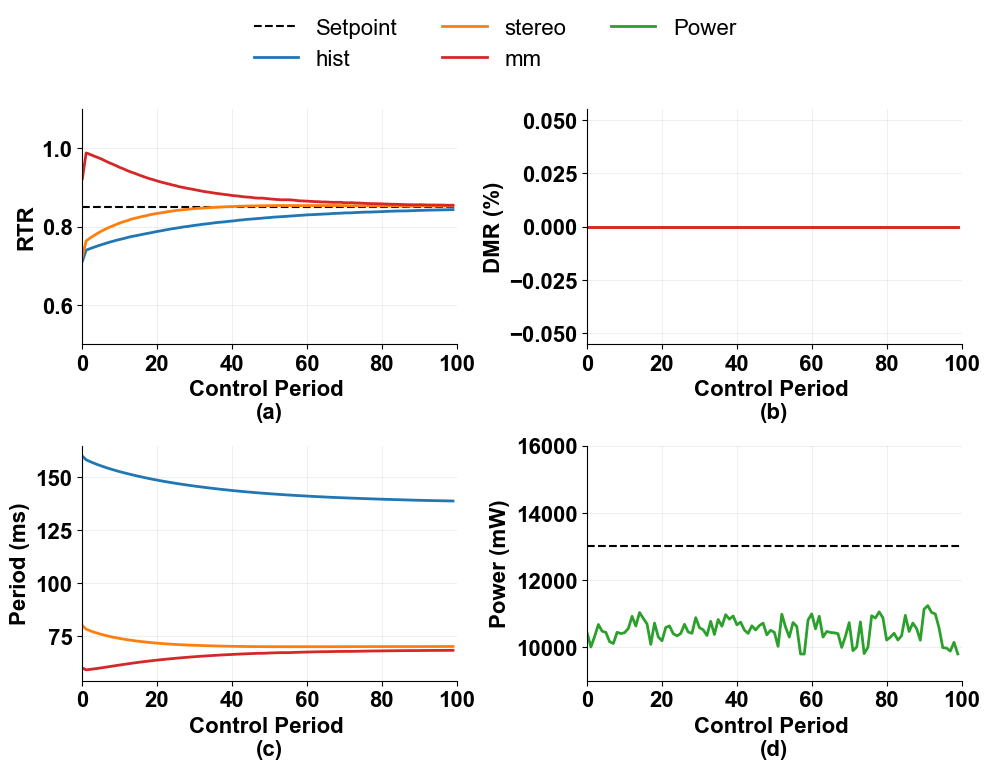

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
10354.869


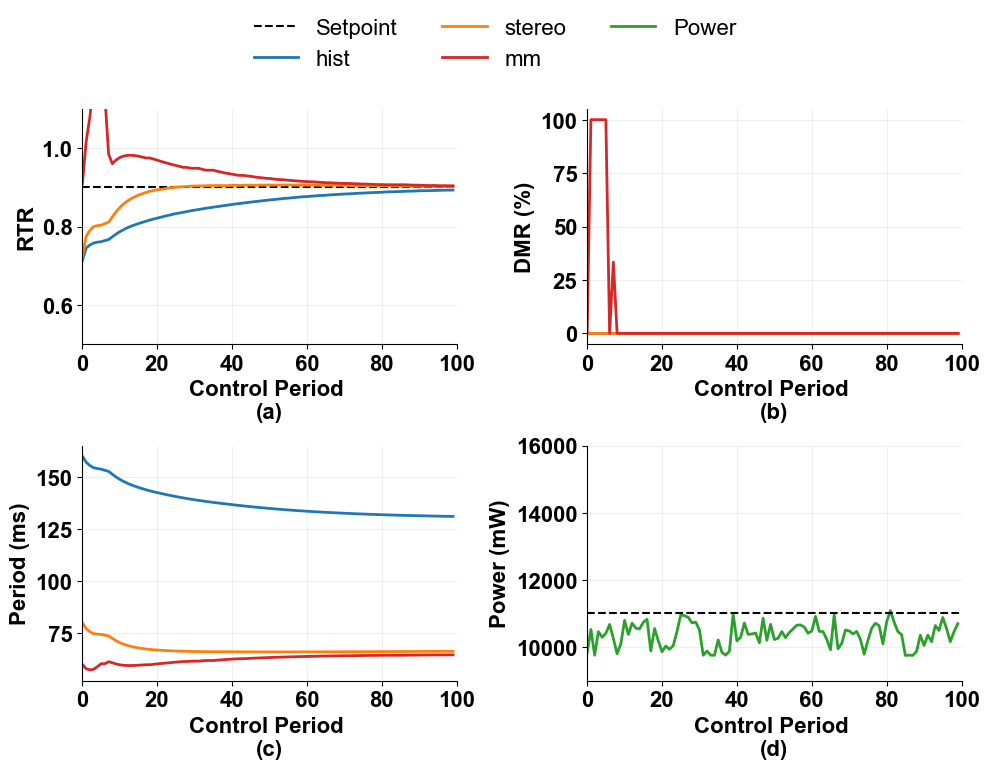

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_11500_0.90_0.90_0.90
10355.133500000002


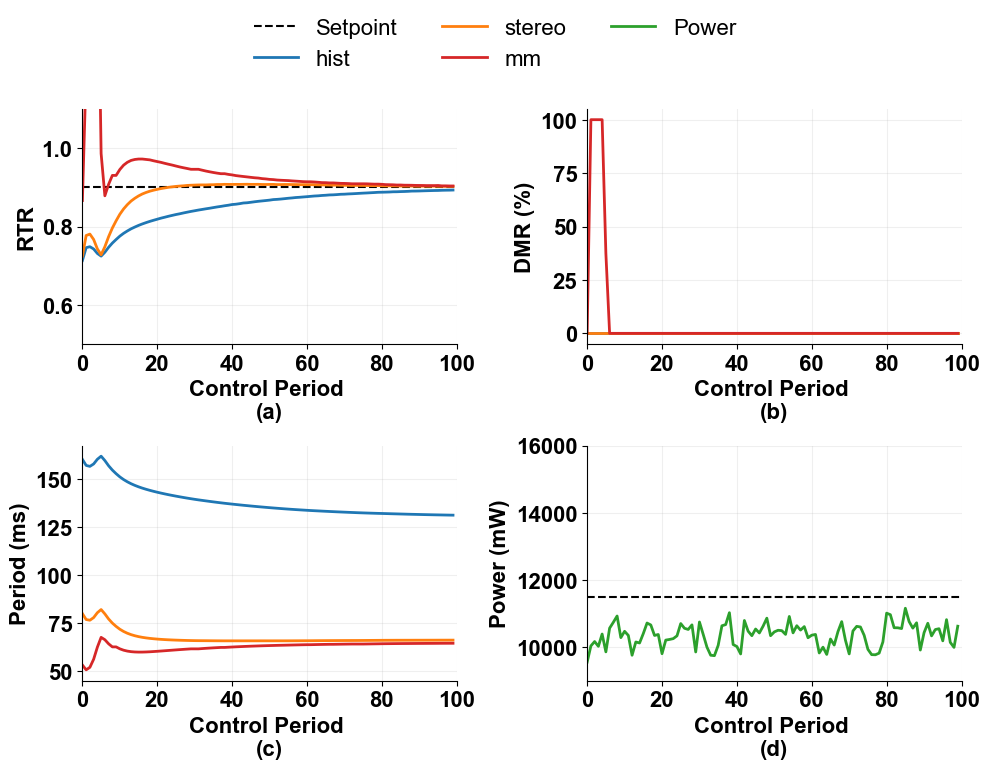

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12000_0.90_0.90_0.90
10388.7105


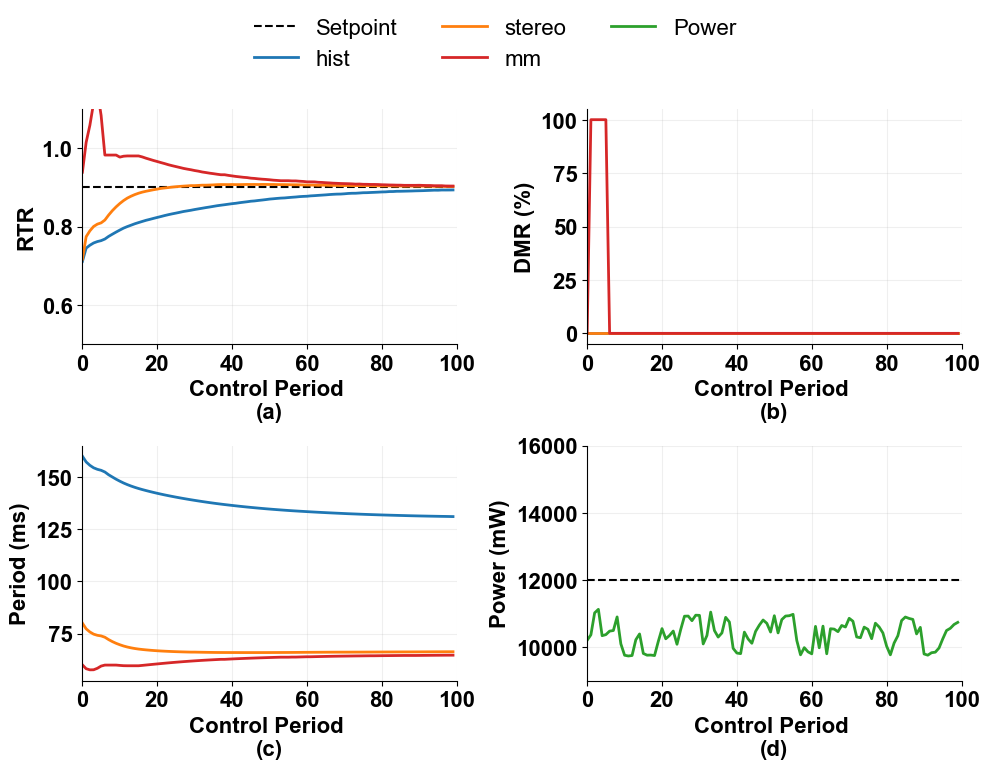

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_12500_0.90_0.90_0.90
10422.236


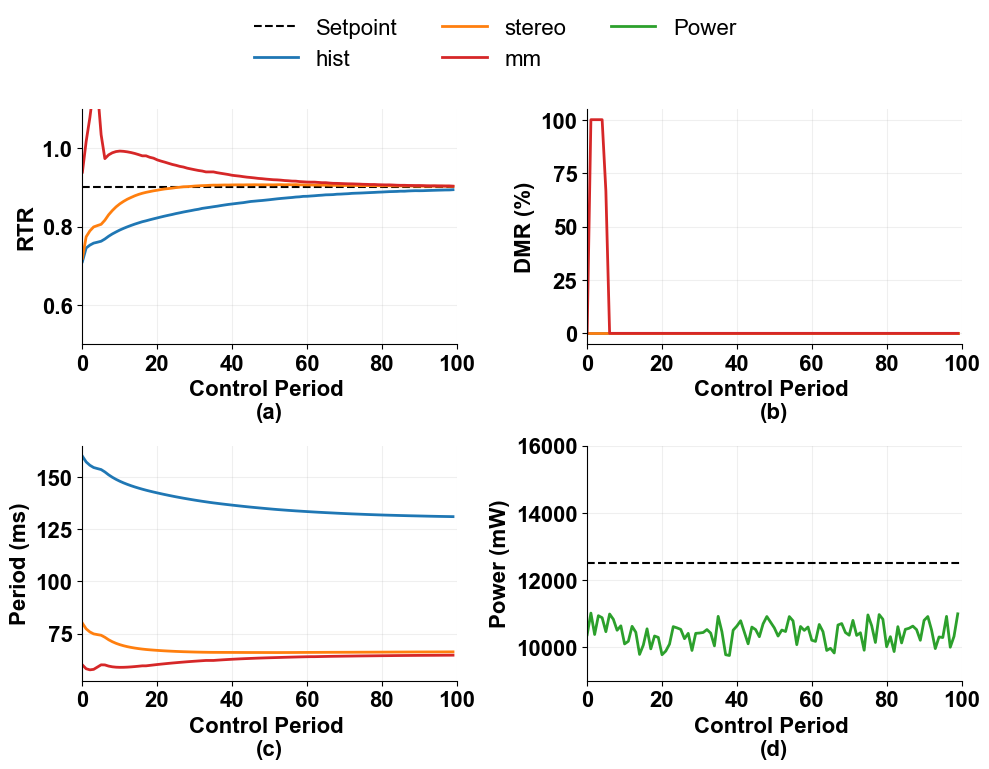

02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.90_0.90_0.90
10416.1725


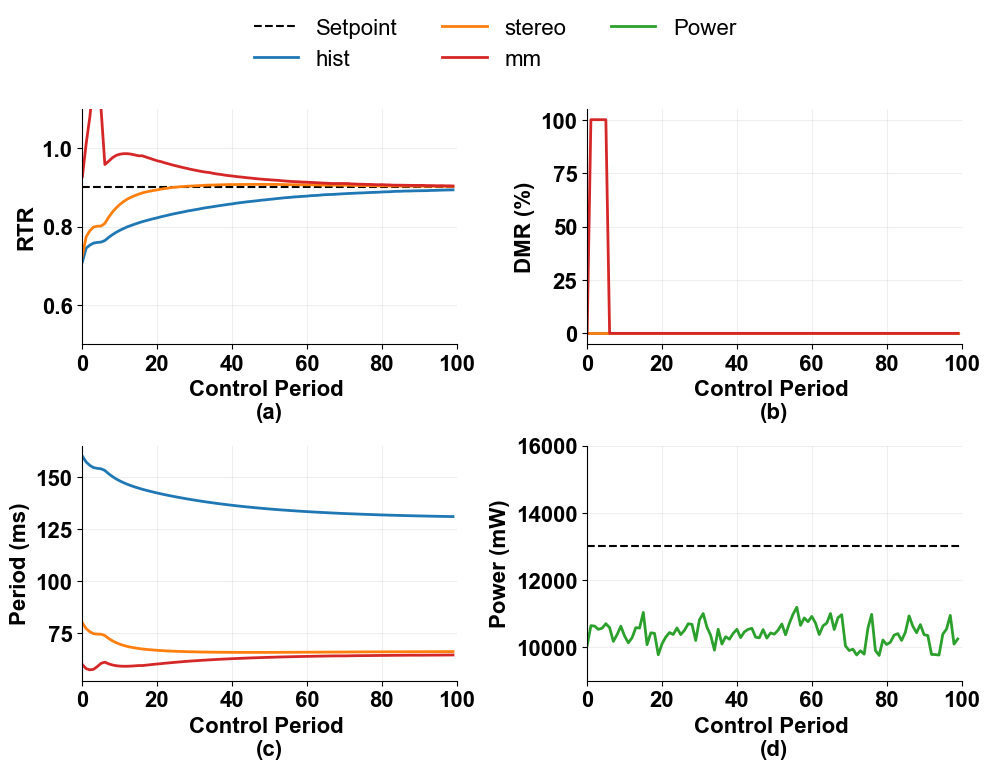

In [9]:
################FULL FC
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"

# --------- CONFIG ----------
root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
p_setpoint = [11000, 11500, 12000, 12500, 13000]
warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/Full_FC")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16

LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "FC_GPU_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Setpoint")
        ax.set_ylim([9000,16000])

        # Global Styling
        for ax in axs:
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3,
            frameon=False, 
            prop={'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"FC_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11000_0.70_0.70_0.70
11009.640999999998


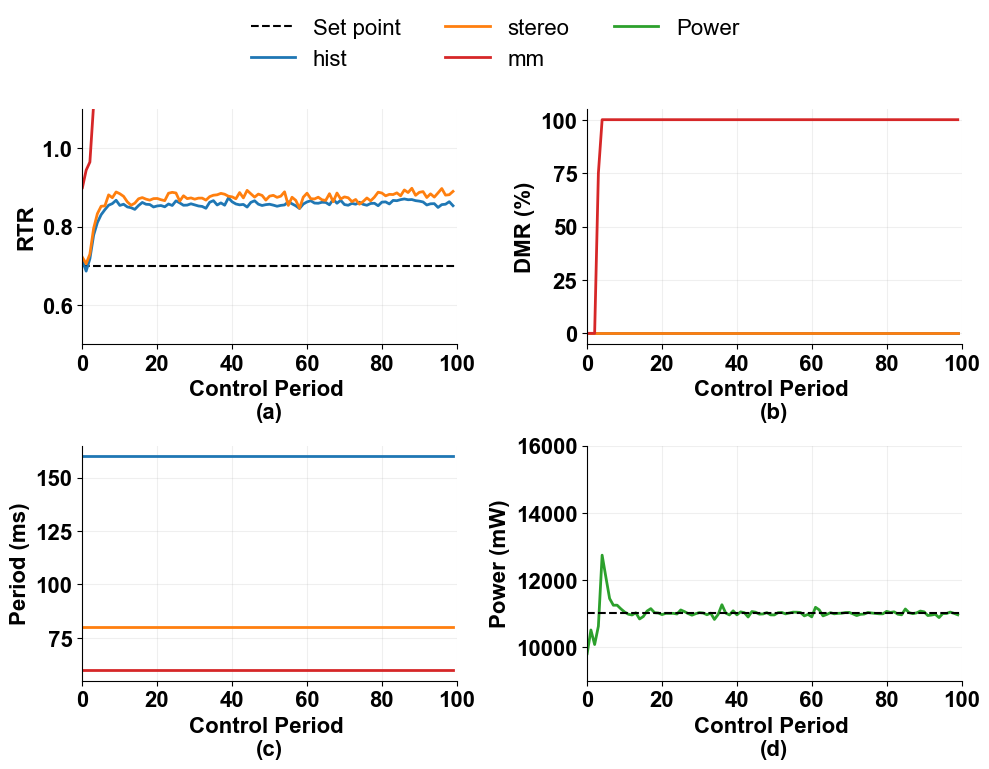

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11500_0.70_0.70_0.70
11491.373


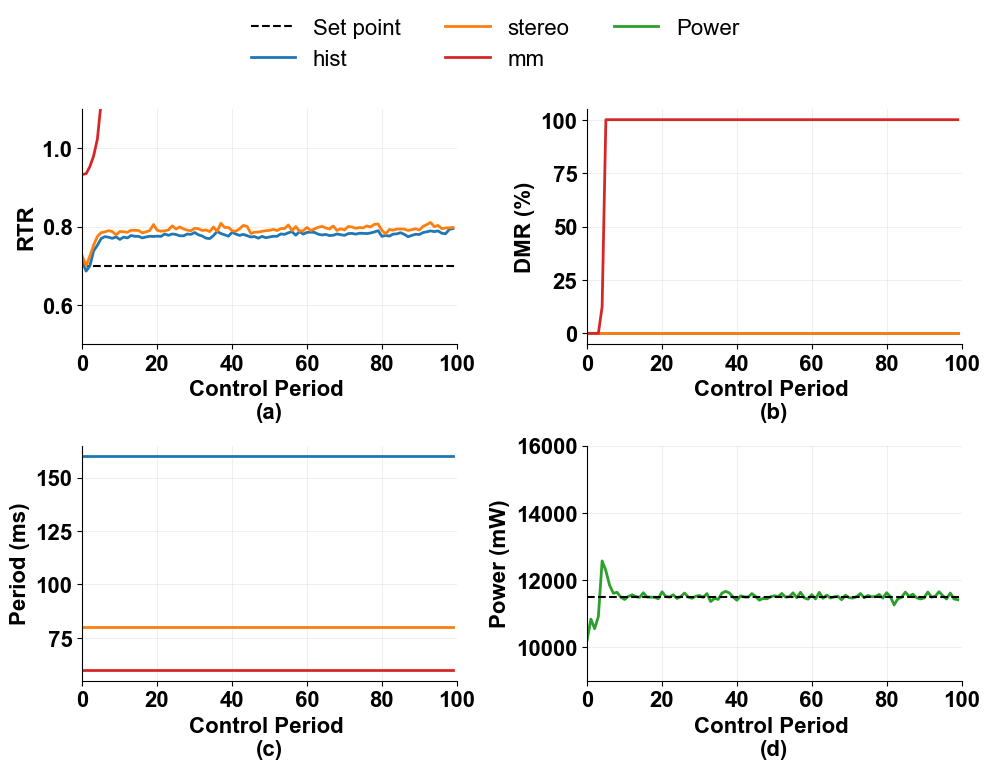

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12000_0.70_0.70_0.70
11953.95


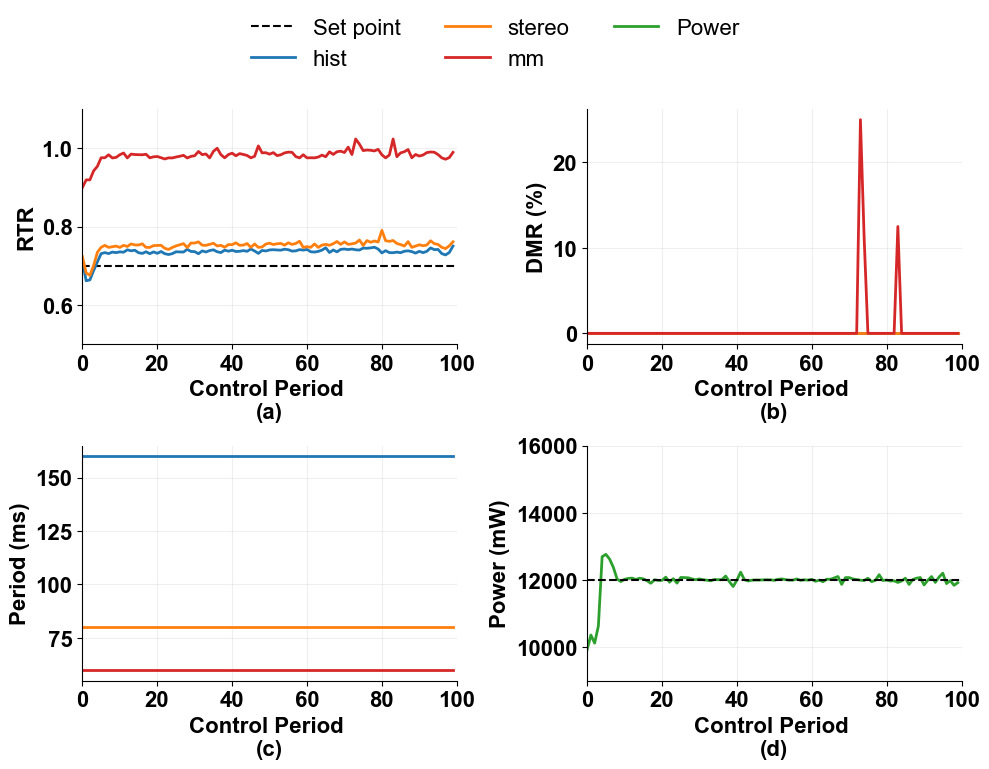

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12500_0.70_0.70_0.70
12444.9585


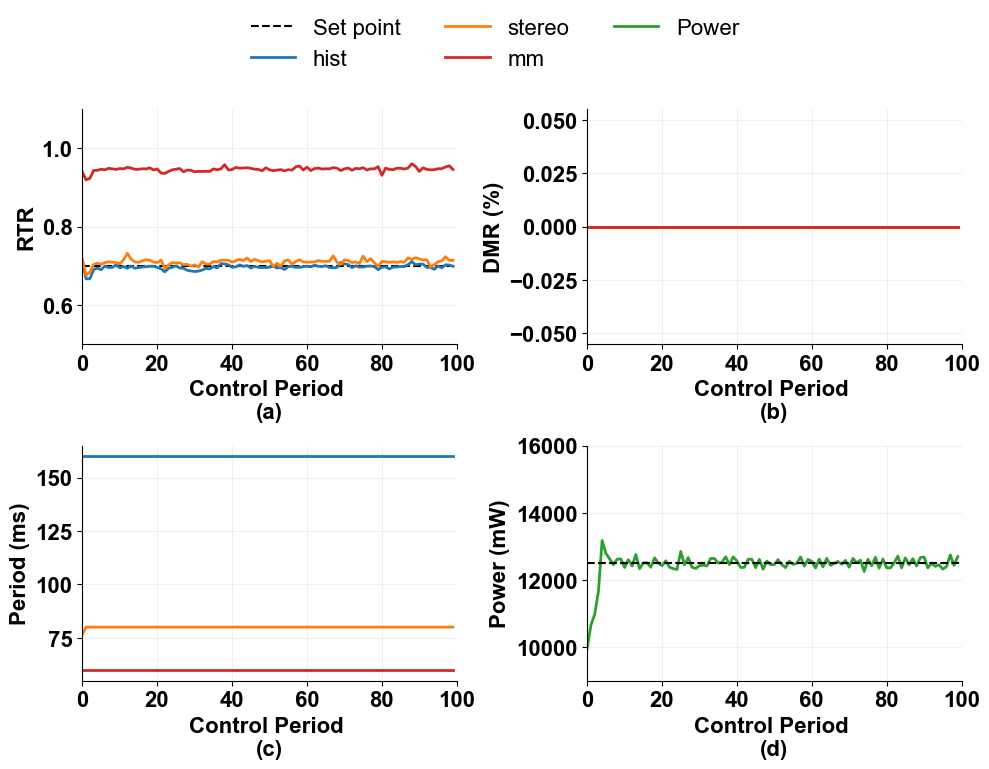

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_13000_0.70_0.70_0.70
12883.302999999998


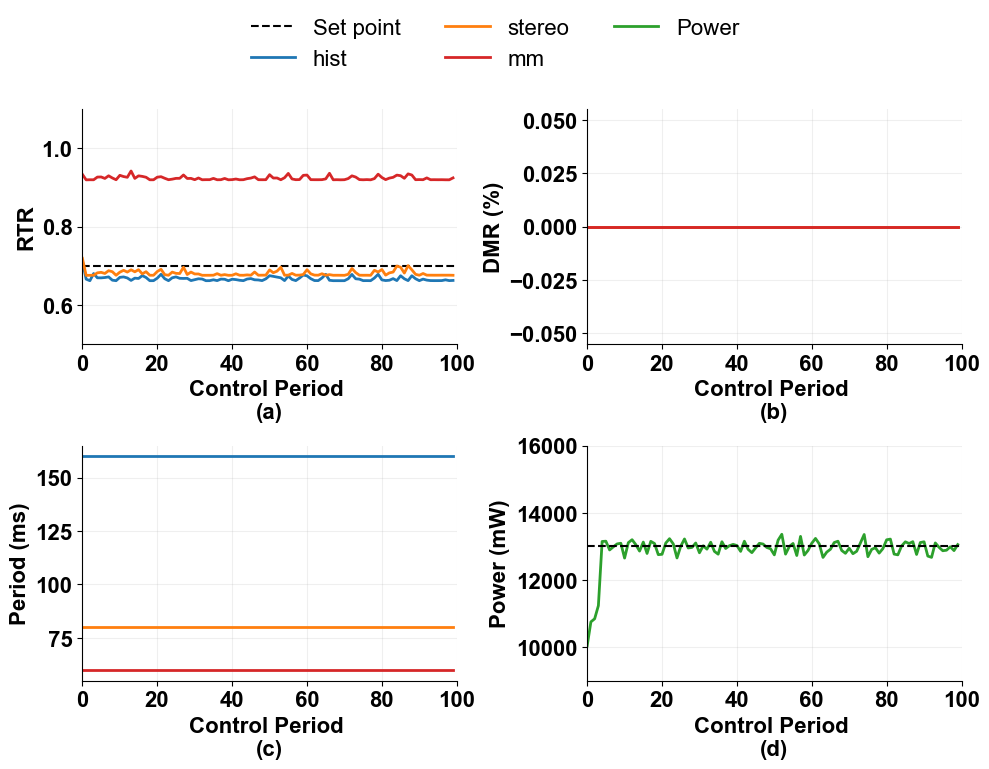

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11000_0.75_0.75_0.75
11017.622000000001


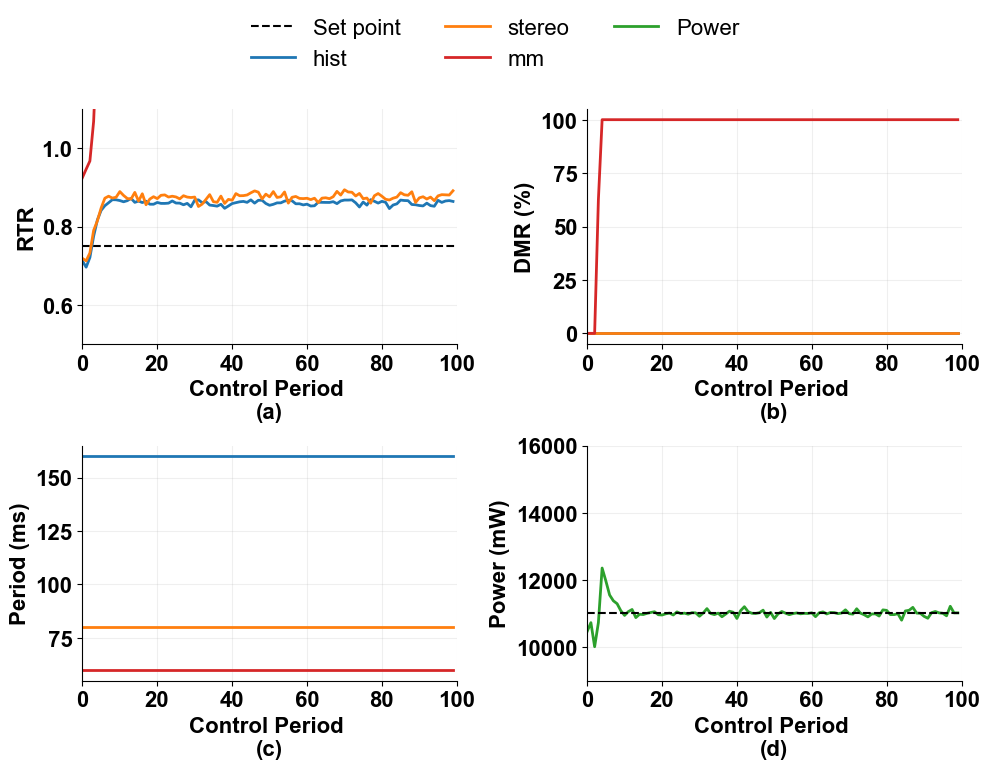

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11500_0.75_0.75_0.75
11491.832999999999


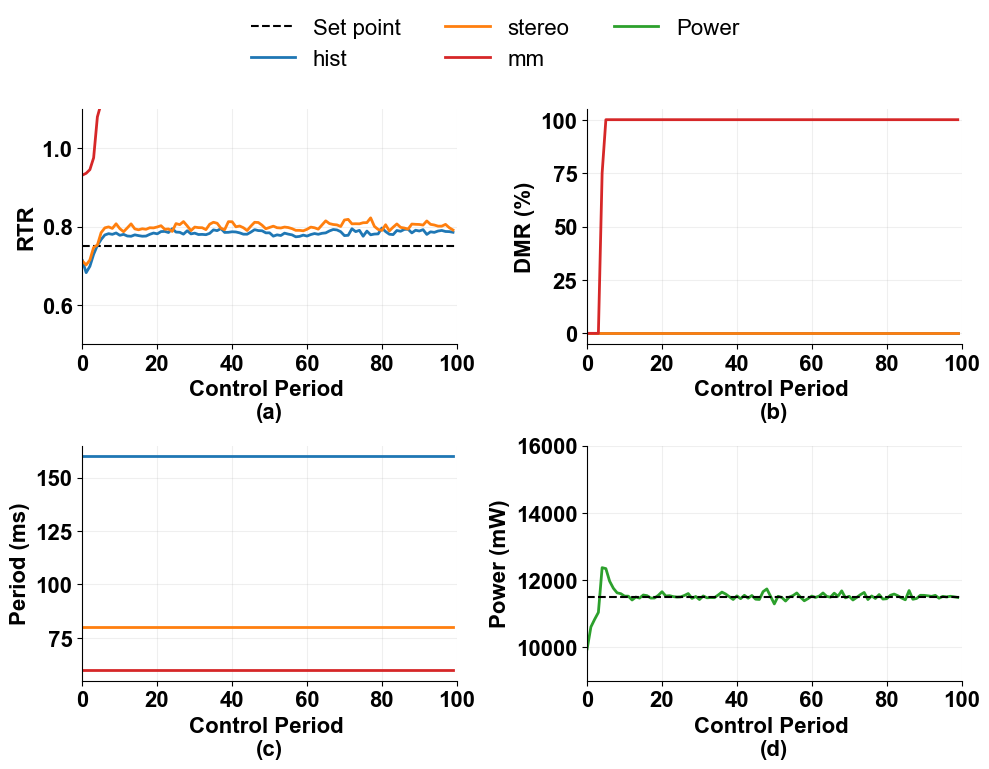

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12000_0.75_0.75_0.75
11954.086000000001


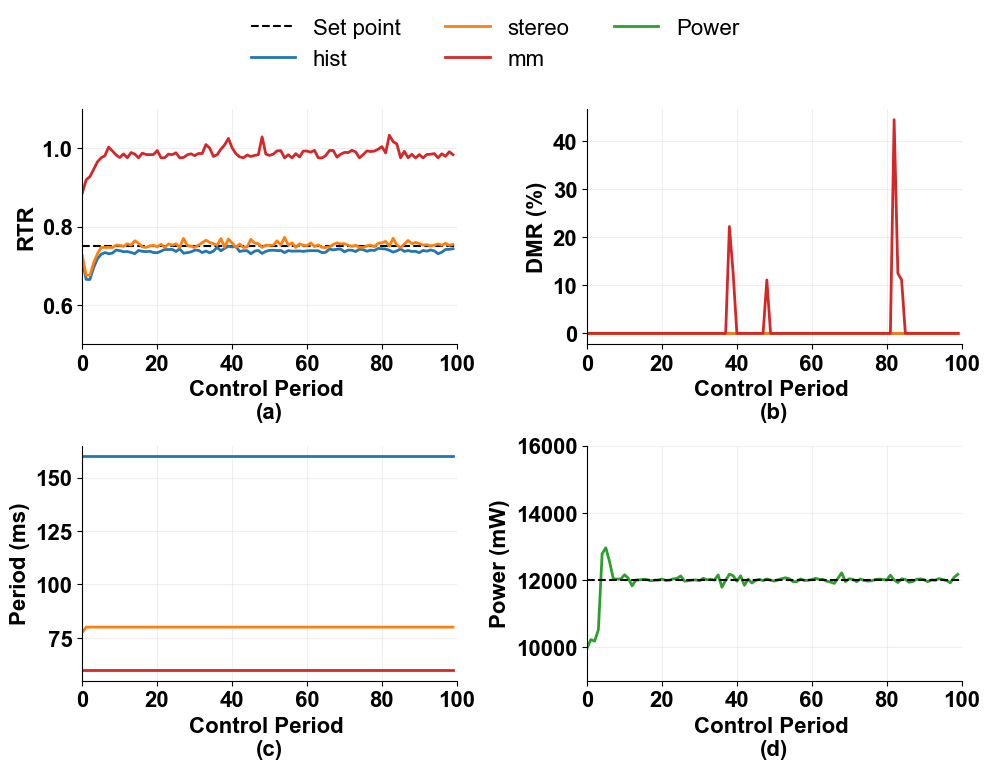

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12500_0.75_0.75_0.75
12440.534999999998


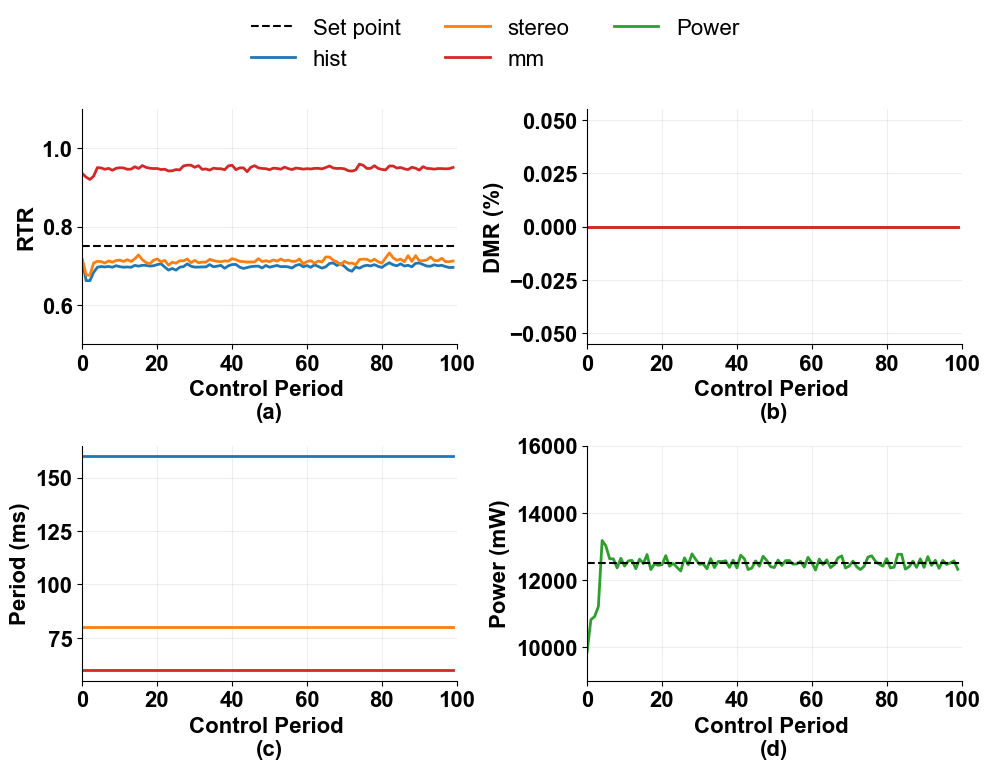

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75
12879.284


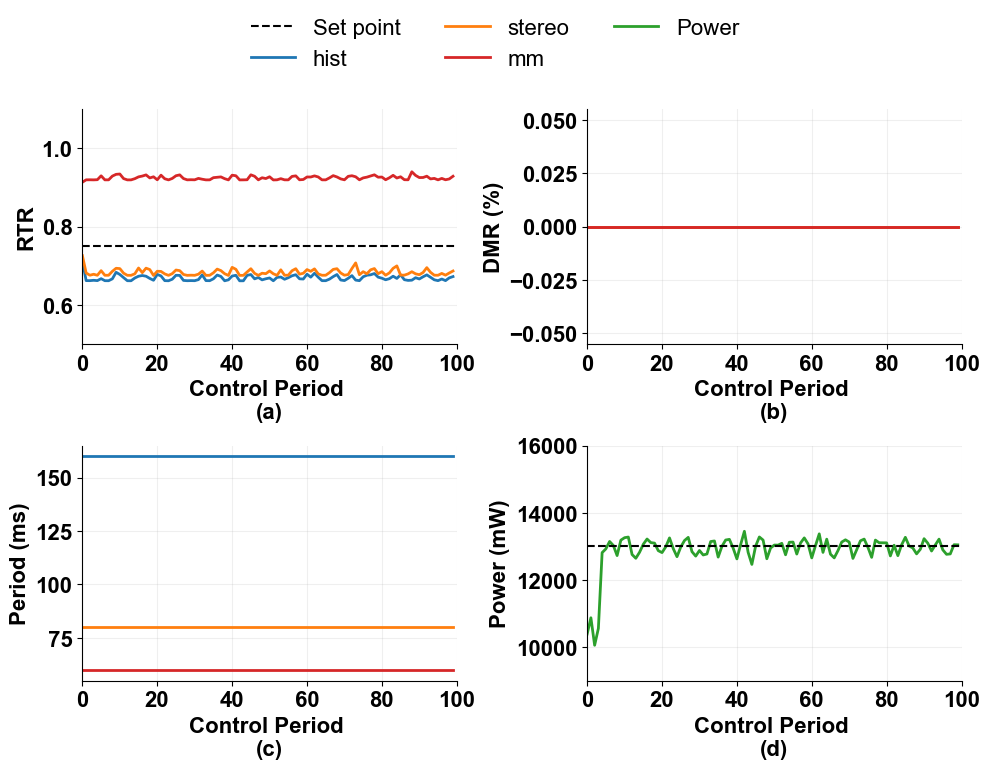

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11000_0.80_0.80_0.80
11017.966999999999


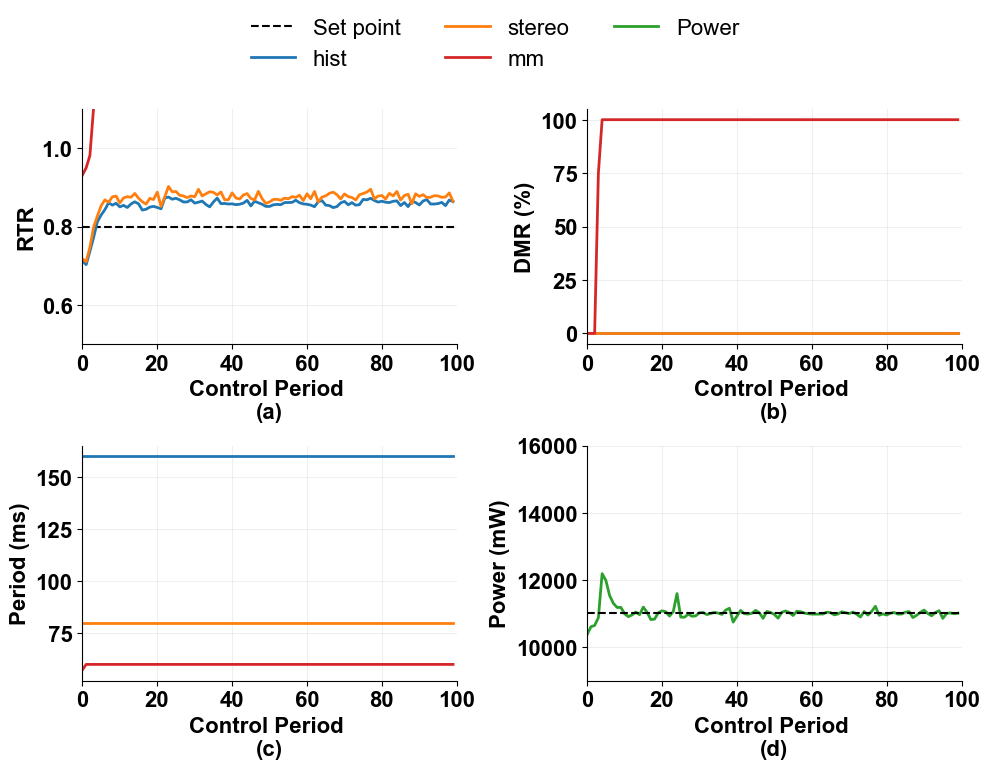

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11500_0.80_0.80_0.80
11488.072999999999


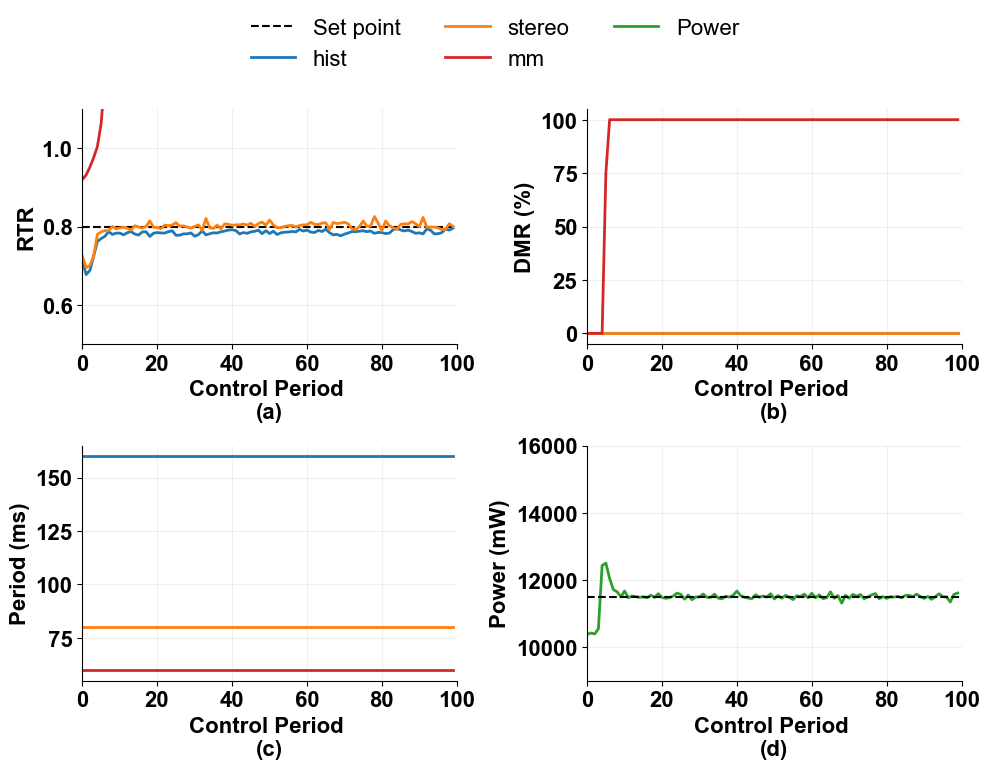

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12000_0.80_0.80_0.80
11962.4105


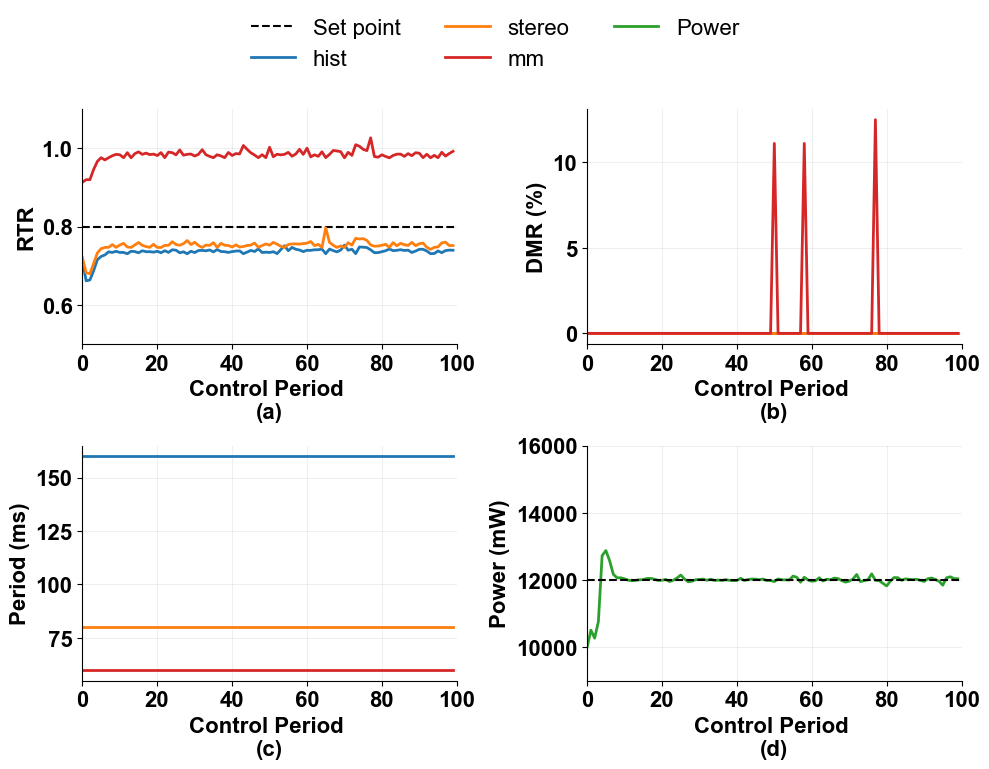

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12500_0.80_0.80_0.80
12411.115999999998


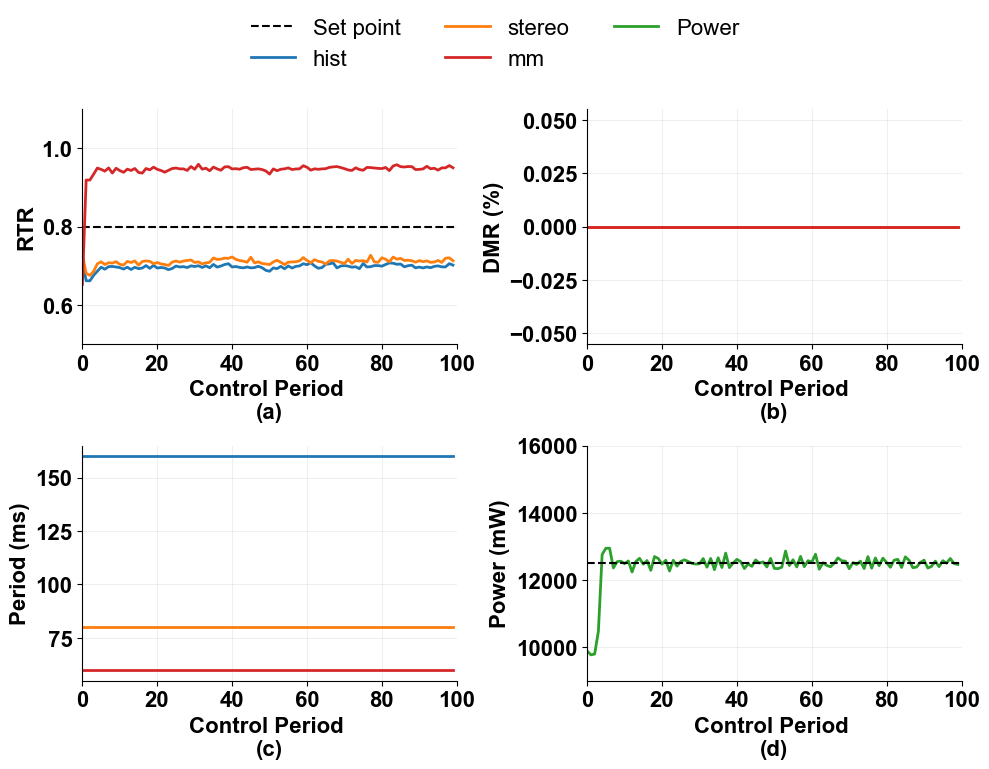

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_13000_0.80_0.80_0.80
12853.1035


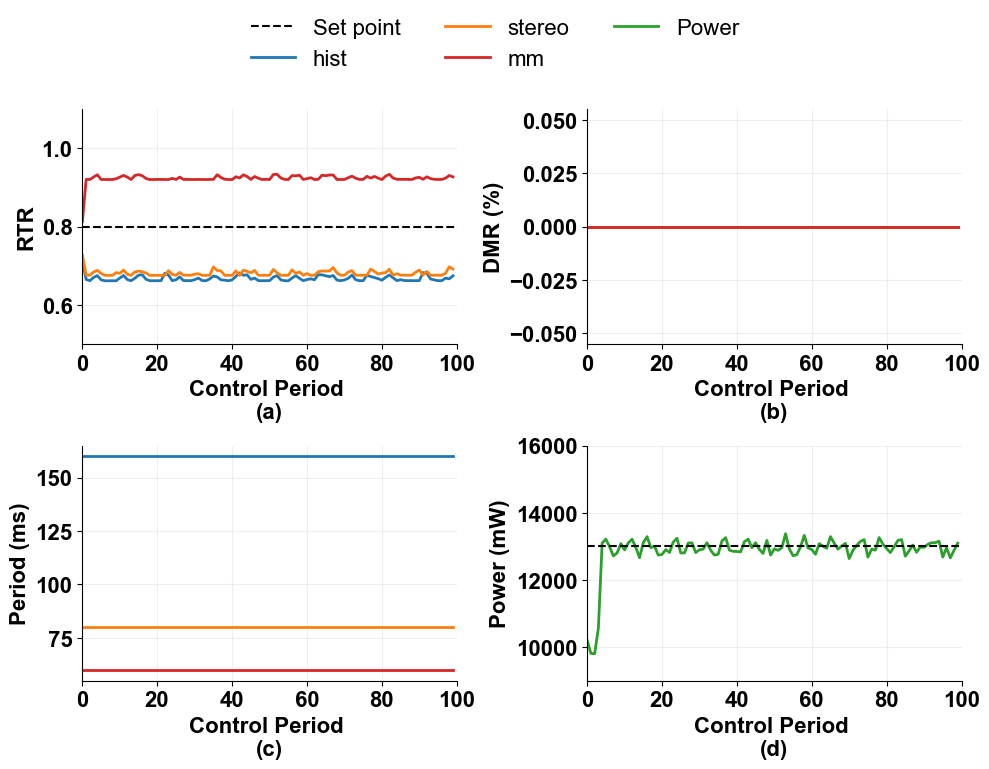

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11000_0.85_0.85_0.85
10987.7225


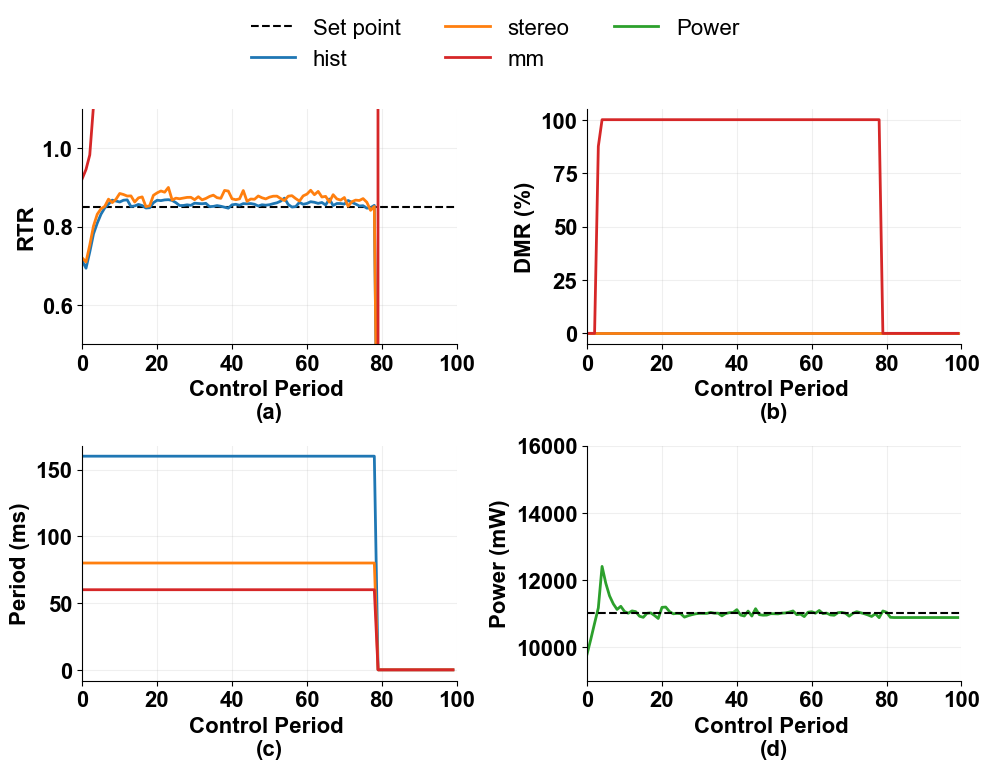

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11500_0.85_0.85_0.85
11487.572


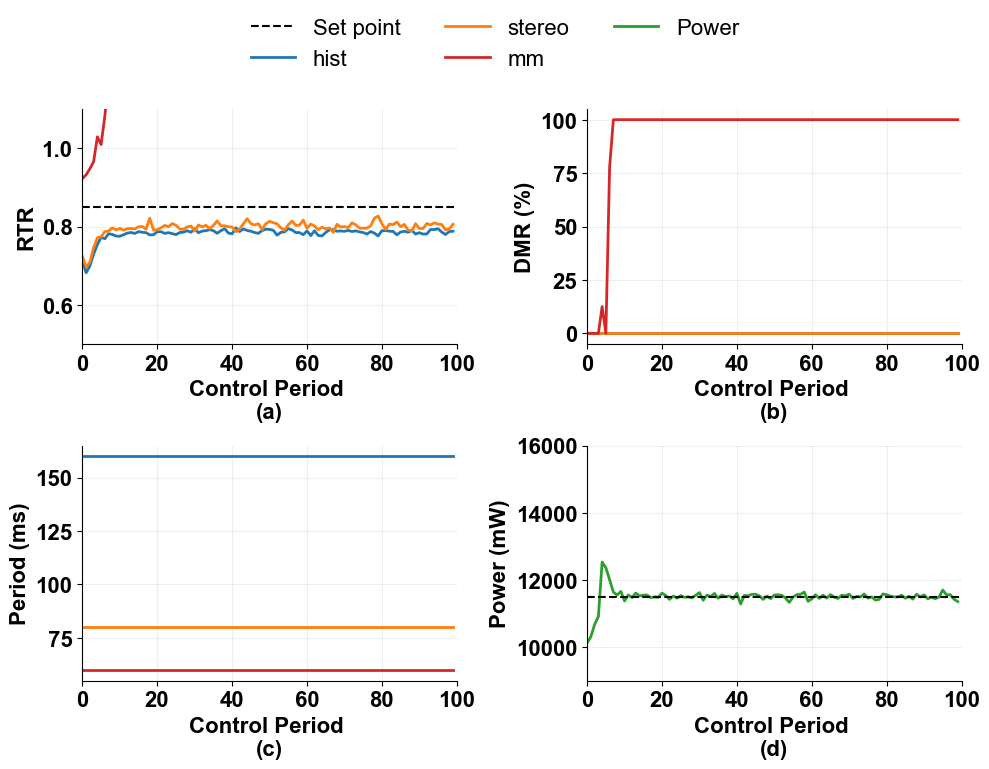

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12000_0.85_0.85_0.85
11966.260000000002


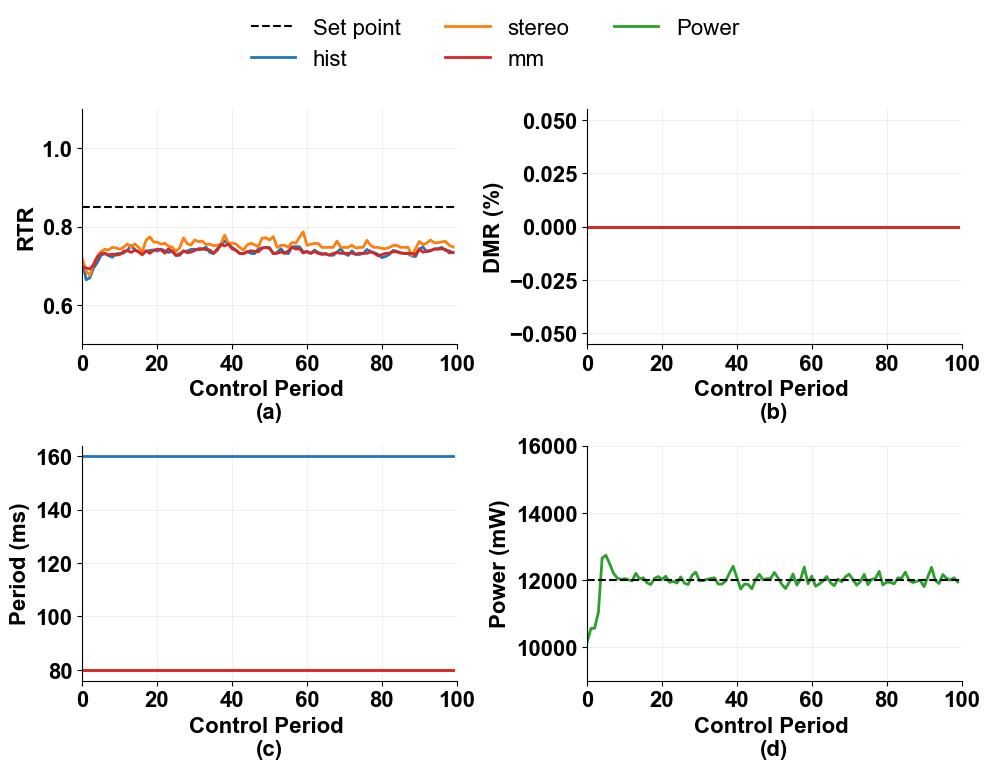

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12500_0.85_0.85_0.85
12432.715


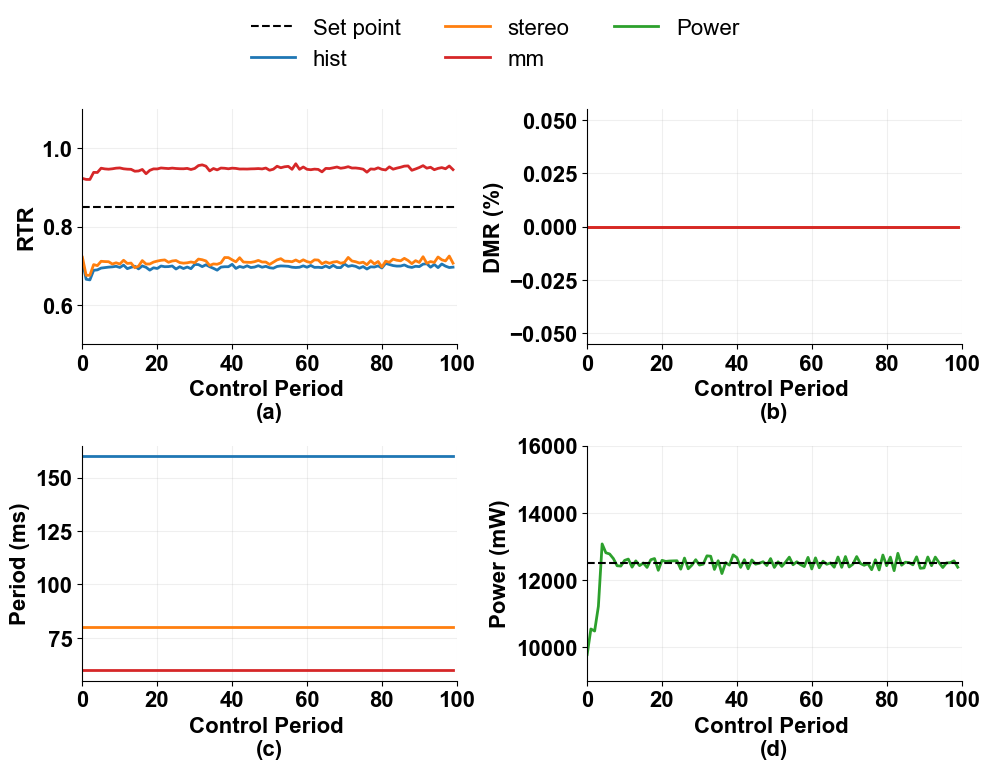

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_13000_0.85_0.85_0.85
12855.701500000001


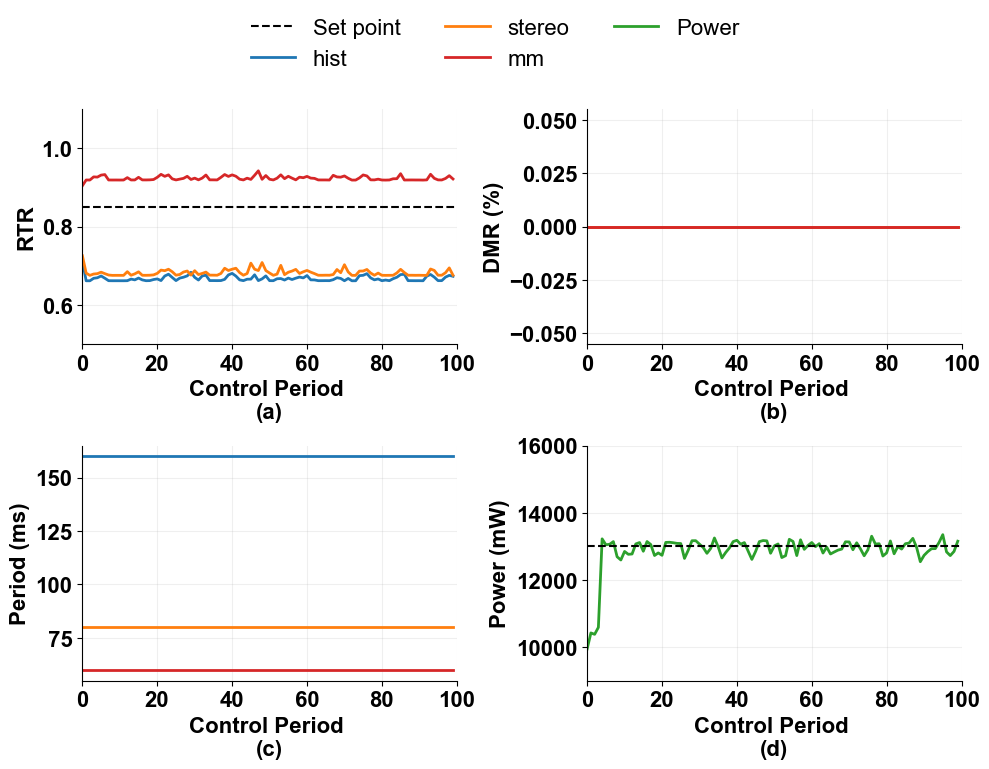

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
11000.4015


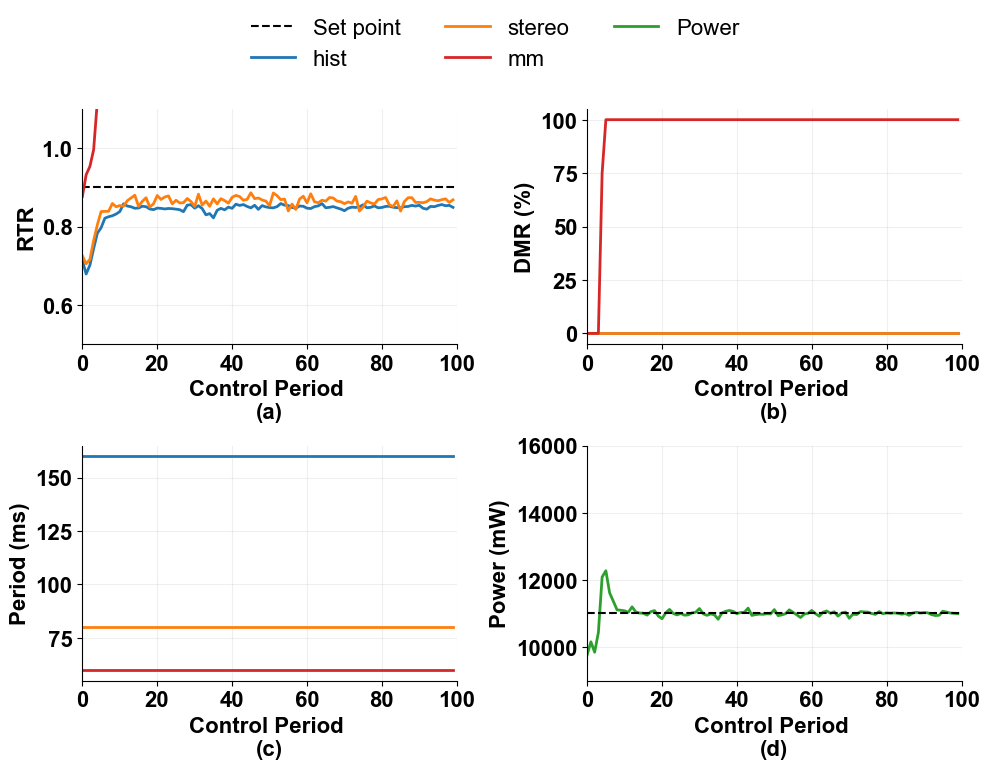

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_11500_0.90_0.90_0.90
11485.871000000001


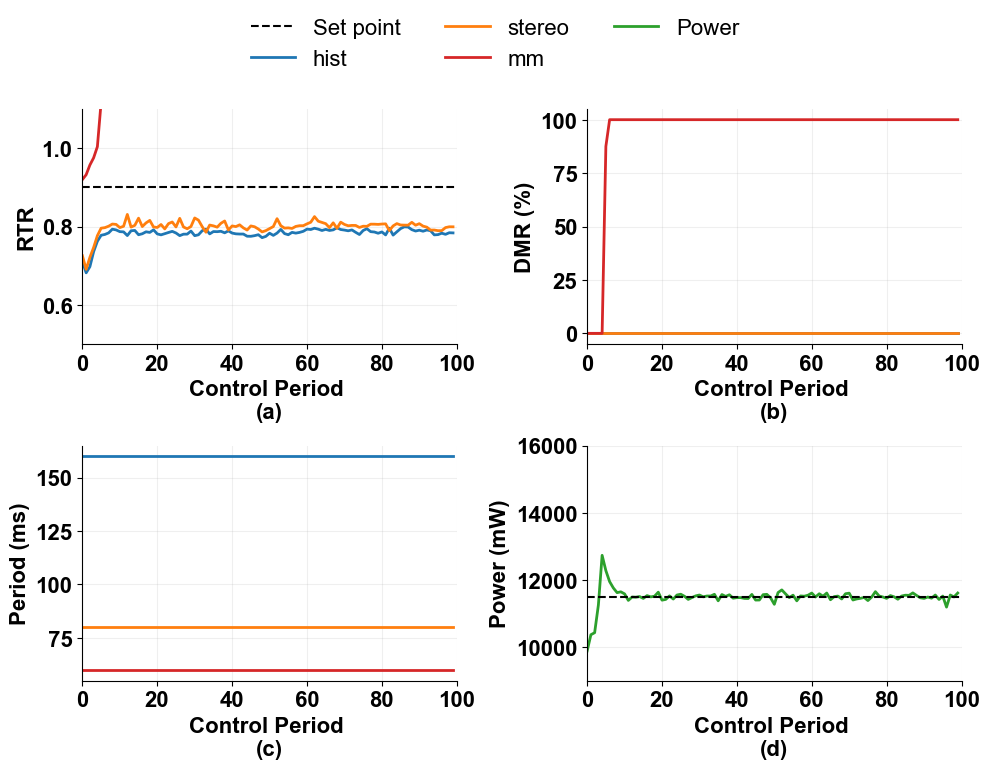

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12000_0.90_0.90_0.90
11960.4135


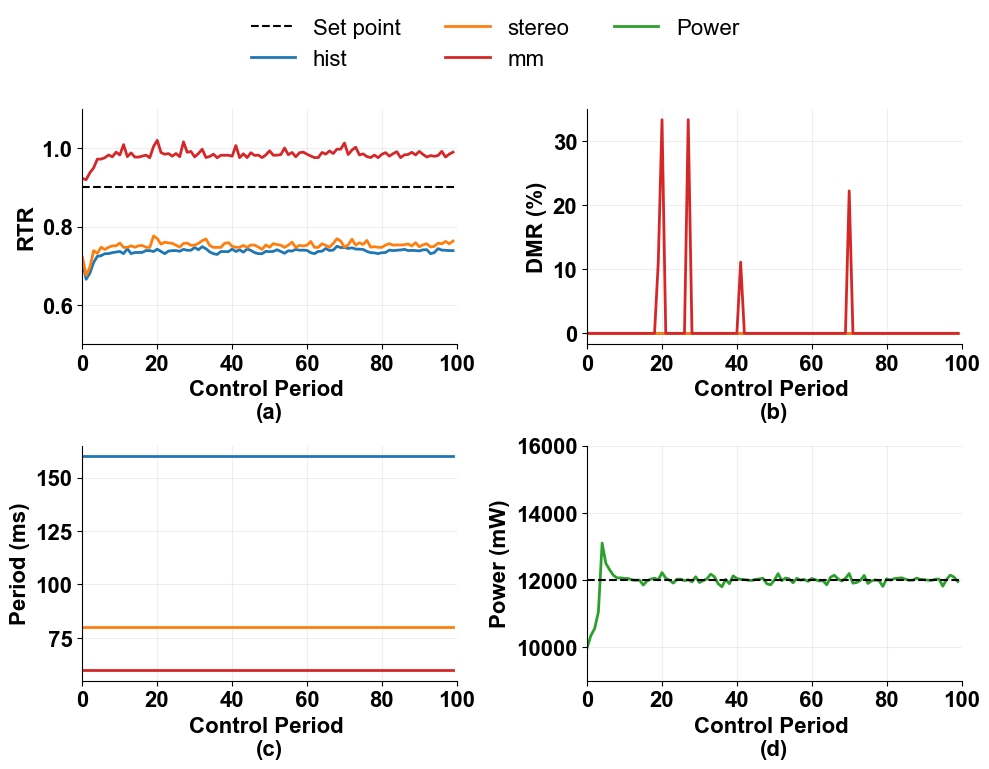

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_12500_0.90_0.90_0.90
12434.885


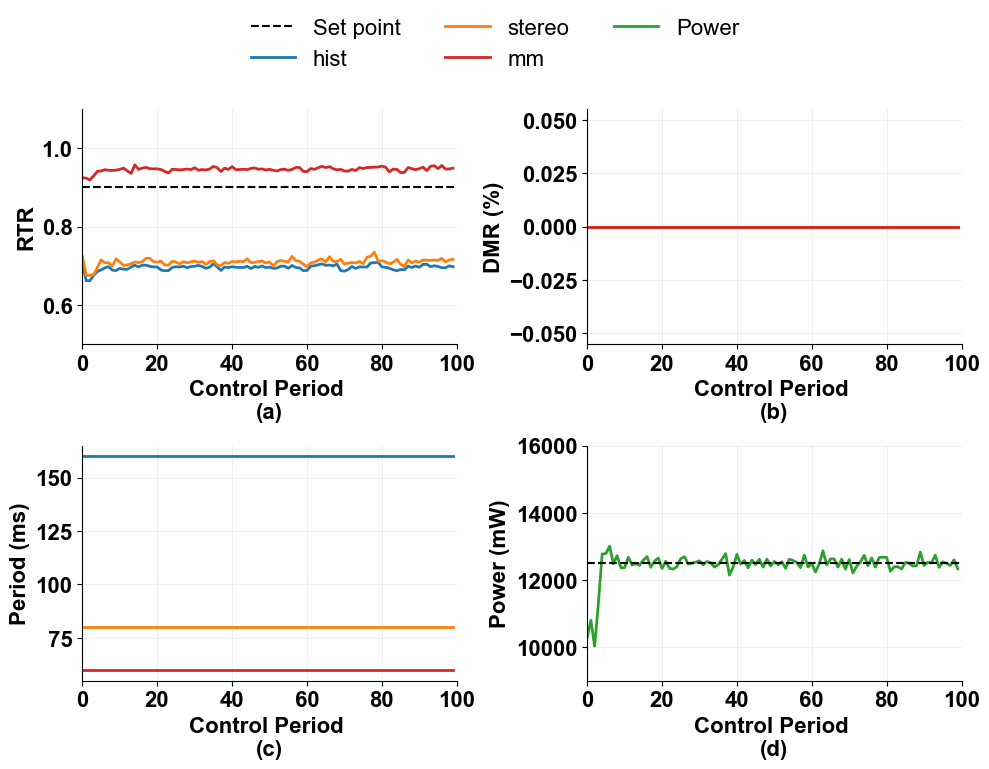

02_regular_tests\logs\Full_DFS\hist_stereo_mm\setpoint_13000_0.90_0.90_0.90
12869.010499999999


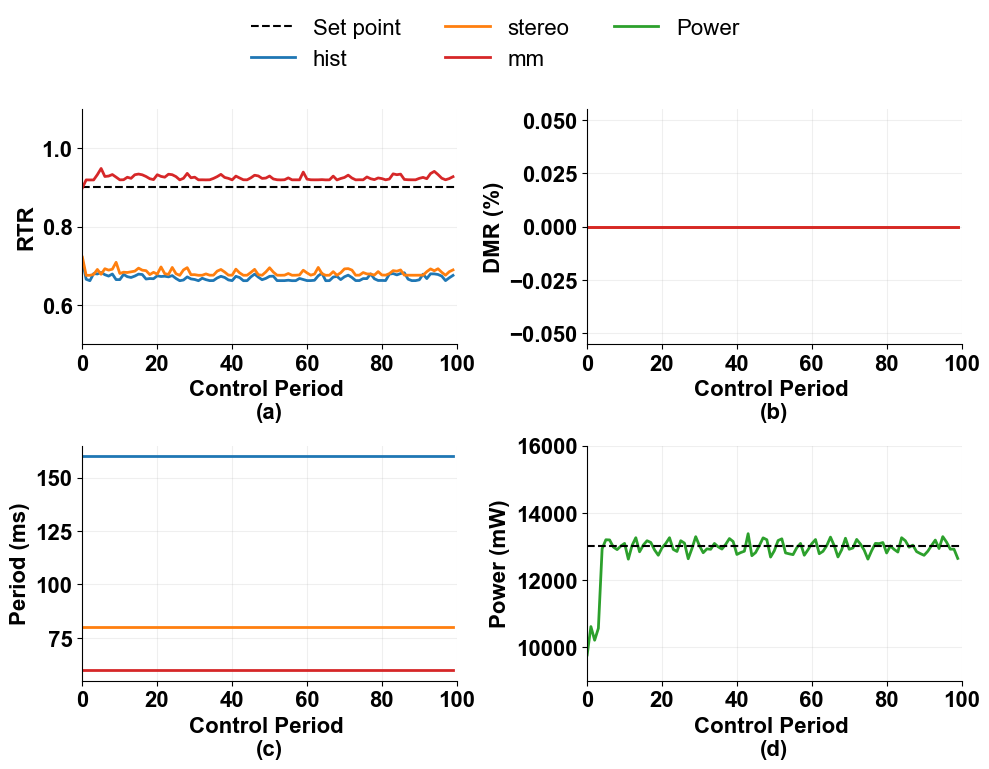

In [17]:
################FULL DFS
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"

# --------- CONFIG ----------
root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/")
setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
p_setpoint = [11000, 11500, 12000, 12500, 13000]
warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/Full_DFS")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16

LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"DFS_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"DFS_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "DFS_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()

        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")
        ax.set_ylim([9000,16000])

        # Global Styling
        for ax in axs:
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
        #bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
        #handles.append(bound_handle)
        #labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"DFS_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

In [ ]:
################ Openloop
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"

# --------- CONFIG ----------
root = Path("02_regular_tests/logs/openloop/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/")
setpoints = [0.90]
p_setpoint = [11000]
warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/openloop")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16

LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"OpenLoop_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"OpenLoop_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"OpenLoop_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"OpenLoop_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"OpenLoop_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "OpenLoop_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()

        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")
        ax.set_ylim([9000,16000])

        # Global Styling
        for ax in axs:
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
        #bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
        #handles.append(bound_handle)
        #labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"openloop_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

04_power_interrupt_tests\logs\power_interrupt_LQR\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
10622.661


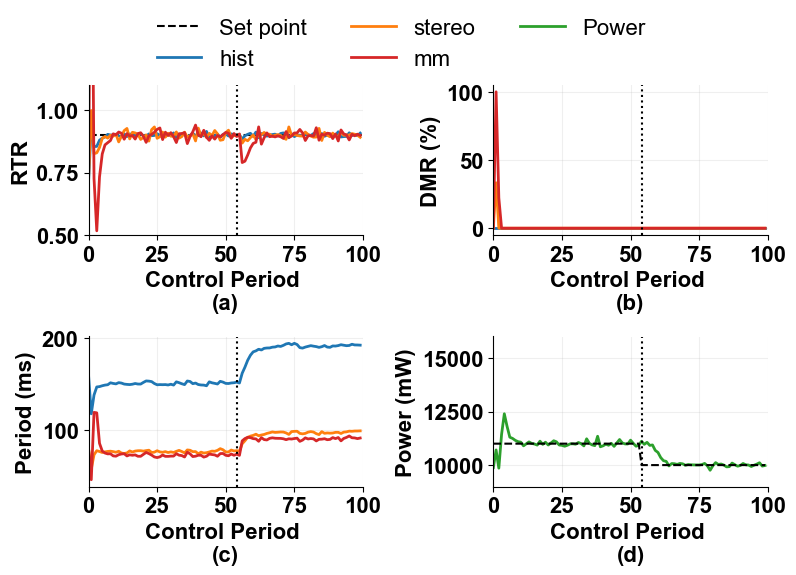

In [18]:
################Power interrupt LQR
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("04_power_interrupt_tests/logs/power_interrupt_LQR/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.90]
p_setpoint = [11000]
change_period = 54
power_after = 10000

warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/power_interrupt_LQR")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16


LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"LQR_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"LQR_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "LQR_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim([9000,16000])
        power_sp = np.full(max_periods, power, dtype=float)
        power_sp[change_period:] = power_after

        ax.plot(
            power_sp,
            color='black',
            linestyle='--',
            linewidth=1.5,
            label="Set point"
        )


        # Global Styling
        for ax in axs:
            ax.axvline(x=change_period, color='black', linestyle=':', linewidth=1.5)
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3,
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"power_interrupt_LQR_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

04_power_interrupt_tests\logs\power_interrupt_FC\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
10700.753


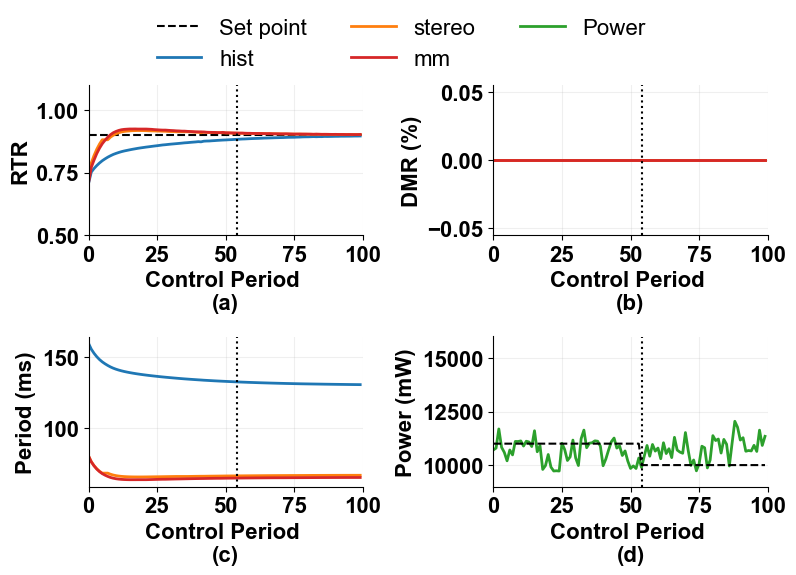

In [19]:
################Power interrupt FC
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("04_power_interrupt_tests/logs/power_interrupt_FC/hist_stereo_mm/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.90]
p_setpoint = [11000]
change_period = 54
power_after = 10000

warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/power_interrupt_FC")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16


LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "FC_GPU_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
               # ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim([9000,16000])
        power_sp = np.full(max_periods, power, dtype=float)
        power_sp[change_period:] = power_after

        ax.plot(
            power_sp,
            color='black',
            linestyle='--',
            linewidth=1.5,
            label="Set point"
        )


        # Global Styling
        for ax in axs:
            ax.axvline(x=change_period, color='black', linestyle=':', linewidth=1.5)
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"power_interrupt_FC_setpoint_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

04_power_interrupt_tests\logs\power_interrupt_DFS\hist_stereo_mm\setpoint_11000_0.90_0.90_0.90
Mean power: 10631.185


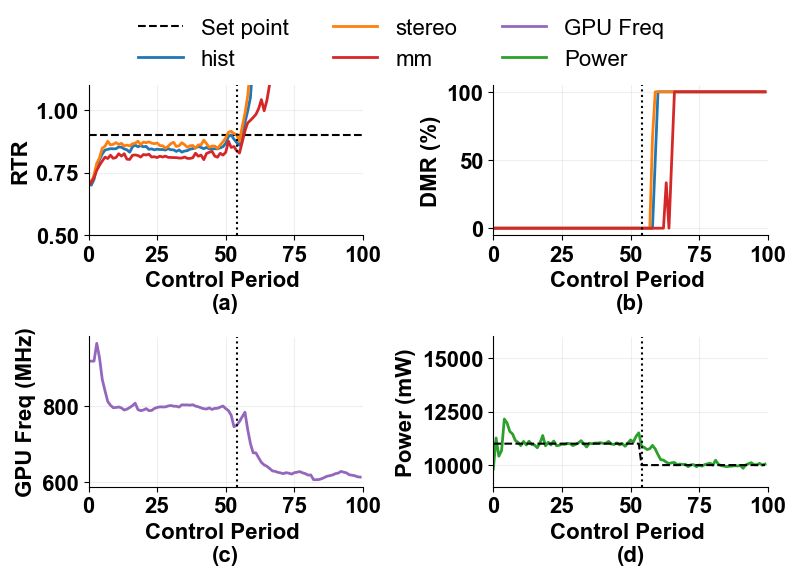

Saved: figures\power_interrupt_DFS\power_interrupt_DFS_setpoint_11000_0.90.pdf
Saved: figures\power_interrupt_DFS\power_interrupt_DFS_setpoint_11000_0.90.png


In [2]:
################ Power interrupt DFS: RTR / DMR / GPU Frequency / Power
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

# ---------- FONT ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# --------- CONFIG ----------
root = Path("04_power_interrupt_tests/logs/power_interrupt_DFS/hist_stereo_mm/")

setpoints = [0.90]
p_setpoint = [11000]

change_period = 54
power_after = 10000

warmup_skip = 0
max_periods = 100

save_path = Path("figures/power_interrupt_DFS")

task_names = ["hist", "stereo", "mm"]
task_colors = ["tab:blue", "tab:orange", "tab:red"]

FIGSIZE = (8, 6)

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0


# ---------------------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    return vals if vals else None


def slice_idx(data, start, stop):
    if data is None:
        return None

    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)

    return np.asarray(data[a:b], dtype=float)


for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"

        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f"SKIP missing/empty: {run_dir}")
            continue

        print(run_dir)

        data = {name: {} for name in task_names}

        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"

            data[name]["rtr"] = slice_idx(
                read_data(run_dir / f"DFS_{t_id}_rtr.txt"),
                warmup_skip,
                max_periods,
            )

            data[name]["dl"] = slice_idx(
                read_data(run_dir / f"DFS_{t_id}_deadline.txt"),
                warmup_skip,
                max_periods,
            )

        pwrs = slice_idx(
            read_data(run_dir / "DFS_finalpowervalues.txt"),
            warmup_skip,
            max_periods,
        )

        freq = slice_idx(
            read_data(run_dir / "DFS_finalfreqvalsvalues.txt"),
            warmup_skip,
            max_periods,
        )

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()

        # =====================================================
        # (a) RTR
        # =====================================================
        ax = axs[0]

        ax.axhline(
            y=sp,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )

        for name, color in zip(task_names, task_colors):
            if data[name]["rtr"] is not None:
                ax.plot(
                    data[name]["rtr"],
                    linewidth=LINEWIDTH,
                    label=name,
                    color=color,
                )

        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_ylim(0.5, 1.1)

        # =====================================================
        # (b) Deadline Miss Ratio
        # =====================================================
        ax = axs[1]

        for name, color in zip(task_names, task_colors):
            if data[name]["dl"] is not None:
                ax.plot(
                    data[name]["dl"],
                    linewidth=LINEWIDTH,
                    color=color,
                )

        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight="bold")

        # =====================================================
        # (c) GPU Frequency
        # =====================================================
        ax = axs[2]

        if freq is not None:
            ax.plot(
                freq,
                linewidth=LINEWIDTH,
                color="tab:purple",
                label="GPU Freq",
            )

        ax.set_ylabel("GPU Freq (MHz)", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight="bold")

        # =====================================================
        # (d) Power
        # =====================================================
        ax = axs[3]

        if pwrs is not None:
            ax.plot(
                pwrs,
                linewidth=LINEWIDTH,
                color="tab:green",
                label="Power",
            )
            print("Mean power:", np.mean(pwrs))

        power_sp = np.full(max_periods, power, dtype=float)
        power_sp[change_period:] = power_after

        ax.plot(
            power_sp,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )

        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight="bold")
        ax.set_ylim([9000, 16000])

        # =====================================================
        # Global styling
        # =====================================================
        for ax in axs:
            ax.axvline(
                x=change_period,
                color="black",
                linestyle=":",
                linewidth=1.5,
            )

            ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

            for tick in ax.get_xticklabels():
                tick.set_fontweight("bold")

            for tick in ax.get_yticklabels():
                tick.set_fontweight("bold")

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

            ax.grid(True, alpha=0.2)
            ax.set_xlim([0, max_periods])

        # =====================================================
        # Global legend
        # =====================================================
        handles, labels = axs[0].get_legend_handles_labels()

        freq_handle = Line2D(
            [0],
            [0],
            color="tab:purple",
            linewidth=LINEWIDTH,
        )
        handles.append(freq_handle)
        labels.append("GPU Freq")

        power_handle = Line2D(
            [0],
            [0],
            color="tab:green",
            linewidth=LINEWIDTH,
        )
        handles.append(power_handle)
        labels.append("Power")

        fig.legend(
            handles,
            labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.97),
            ncol=3,
            frameon=False,
            prop={"size": LEGEND_FONTSIZE},
        )

        plt.tight_layout(rect=[0, 0, 1, 0.85])

        save_path.mkdir(parents=True, exist_ok=True)

        out_pdf = save_path / f"power_interrupt_DFS_setpoint_{power}_{sp:.2f}.pdf"
        out_png = save_path / f"power_interrupt_DFS_setpoint_{power}_{sp:.2f}.png"

        plt.savefig(out_pdf, bbox_inches="tight", dpi=300)
        plt.savefig(out_png, bbox_inches="tight", dpi=300)
        plt.show()

        print("Saved:", out_pdf)
        print("Saved:", out_png)

03_interrupt_tests\logs\LQR_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90
11059.628000000002


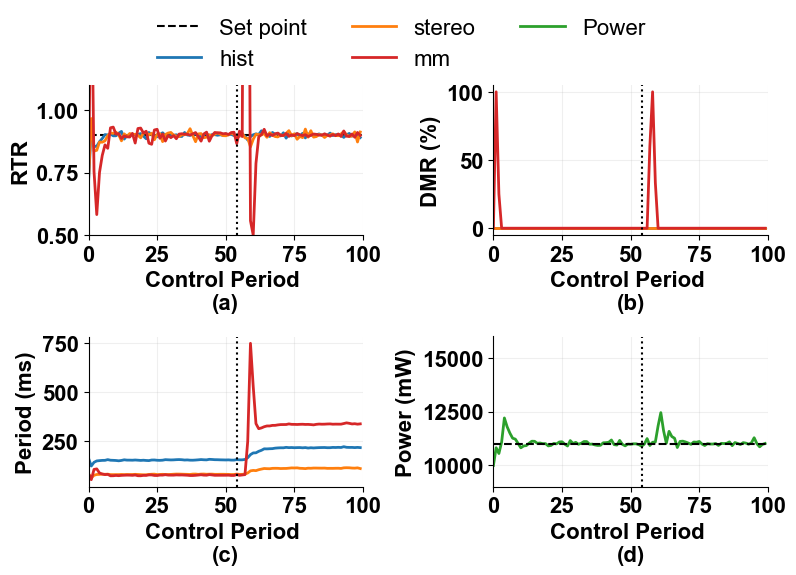

In [20]:
################ MM interrupt LQR
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("03_interrupt_tests/logs/LQR_interrupt/hist_stereo_mm_test/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.90]
p_setpoint = [11000]
change_period = 54

warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/mm_interrupt_LQR")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16


LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"LQR_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"LQR_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "LQR_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim([9000,16000])
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")



        # Global Styling
        for ax in axs:
            ax.axvline(x=change_period, color='black', linestyle=':', linewidth=1.5)
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"mm_interrupt_LQR_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

03_interrupt_tests\logs\FC_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90
11349.222999999998


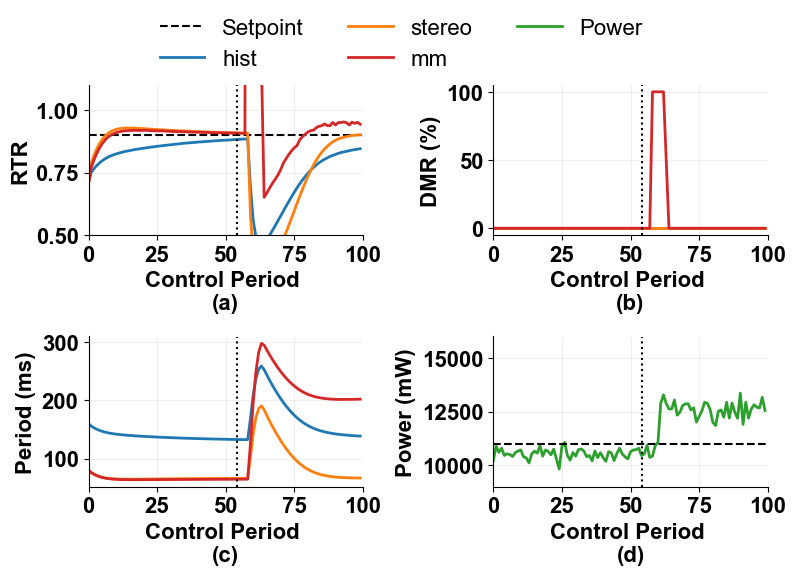

In [25]:
################ interrupt FC
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("03_interrupt_tests/logs/FC_interrupt/hist_stereo_mm_test/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.90]
p_setpoint = [11000]
change_period = 54

warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/mm_interrupt_FC")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16


LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"FC_GPU_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "FC_GPU_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
               # ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim([9000,16000])
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")


        # Global Styling
        for ax in axs:
            ax.axvline(x=change_period, color='black', linestyle=':', linewidth=1.5)
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"mm_interrupt_FC_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

03_interrupt_tests\logs\DFS_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90
11057.3275


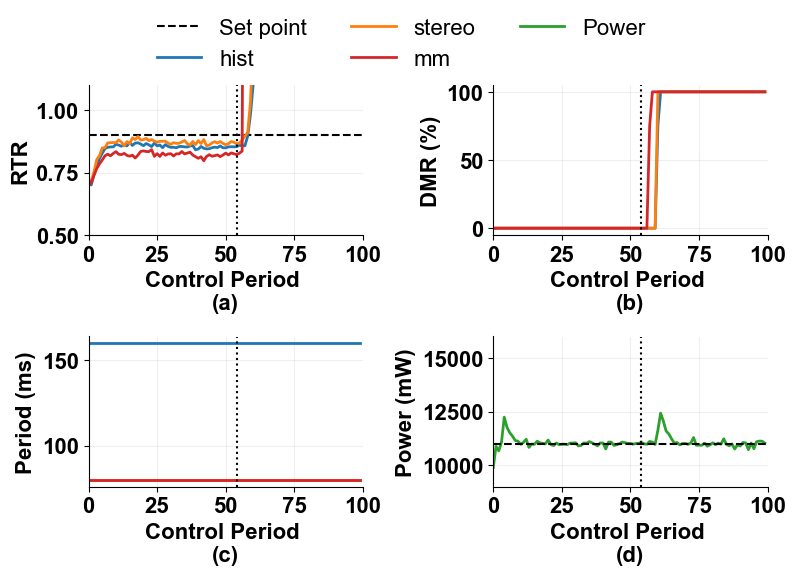

In [15]:
################ interrupt DFS
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"


# --------- CONFIG ----------
root = Path("03_interrupt_tests/logs/DFS_interrupt/hist_stereo_mm_test/")  
#root = Path("Proposed_bounds/histogram_converted_stereodisparity_converted_mm_converted/") 
#oot = Path("LQR/hist_stereo_mm/") 
setpoints = [0.90]
p_setpoint = [11000]
change_period = 54


warmup_skip = 0         
max_periods = 100  
save_path = Path("figures/mm_interrupt_DFS")
task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4) # Slightly taller/wider to prevent overlap
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16

LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists(): return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            try: vals.append(float(s))
            except ValueError: continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None: return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        run_dir = root / f"setpoint_{sp:.2f}_{sp:.2f}_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        #run_dir = root / f"setpoint_{sp:.2f}"
        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f'SKIP missing/empty: {run_dir}')
            continue
        print(run_dir)
        data = {name: {} for name in task_names}
        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"DFS_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"DFS_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"DFS_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "DFS_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()
        
        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Set point")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                #ax.plot(data[name]['low'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
            if data[name]['high'] is not None:
                #ax.plot(data[name]['high'], ':', alpha=0.6, linewidth=1.2, color=color)
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
        print(np.mean(pwrs))
        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim([9000,16000])
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Set point")
        


        # Global Styling
        for ax in axs:
            ax.axvline(x=change_period, color='black', linestyle=':', linewidth=1.5)
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels(): tick.set_fontweight("bold")
            for tick in ax.get_yticklabels(): tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0,100])


        handles, labels = axs[0].get_legend_handles_labels() # Tasks + Setpoint
        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")
#         bound_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
#         handles.append(bound_handle)
#         labels.append("Bounds")

        fig.legend(
            handles, 
            labels, 
            loc='upper center', 
            bbox_to_anchor=(0.5, 0.97),  
            #ncol=len(labels), 
            ncol=3, 
            frameon=False, 
            prop={ 'size': LEGEND_FONTSIZE} 
        )   
        plt.tight_layout(rect=[0, 0, 1, 0.85]) 

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)
        plt.savefig(save_path /f"mm_interrupt_DFS_{power}_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()


openloop
03_interrupt_tests\logs\openloop_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90


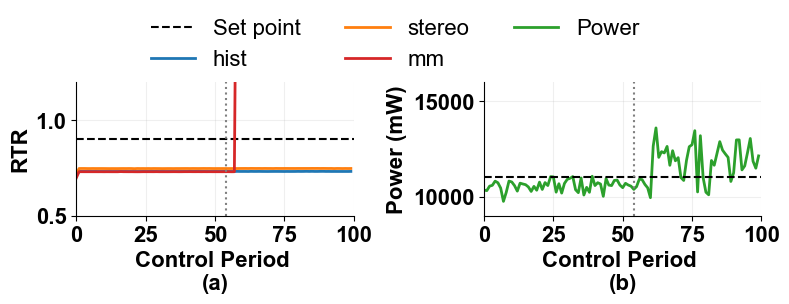

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_openloop_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_openloop_11000_0.90.png

FC_GPU
03_interrupt_tests\logs\FC_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90


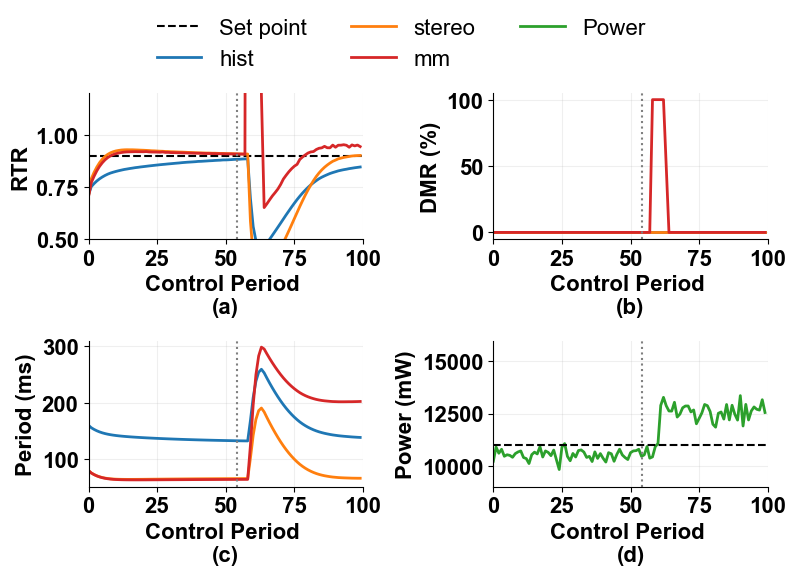

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_FC_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_FC_11000_0.90.png

DFS
03_interrupt_tests\logs\DFS_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90


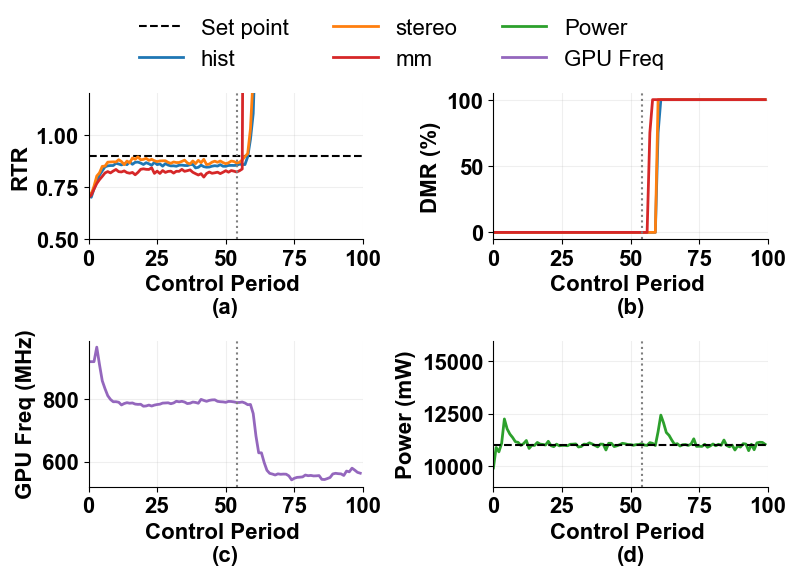

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_DFS_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_DFS_11000_0.90.png

LQR
03_interrupt_tests\logs\LQR_interrupt\hist_stereo_mm_test\setpoint_0.90_0.90_0.90


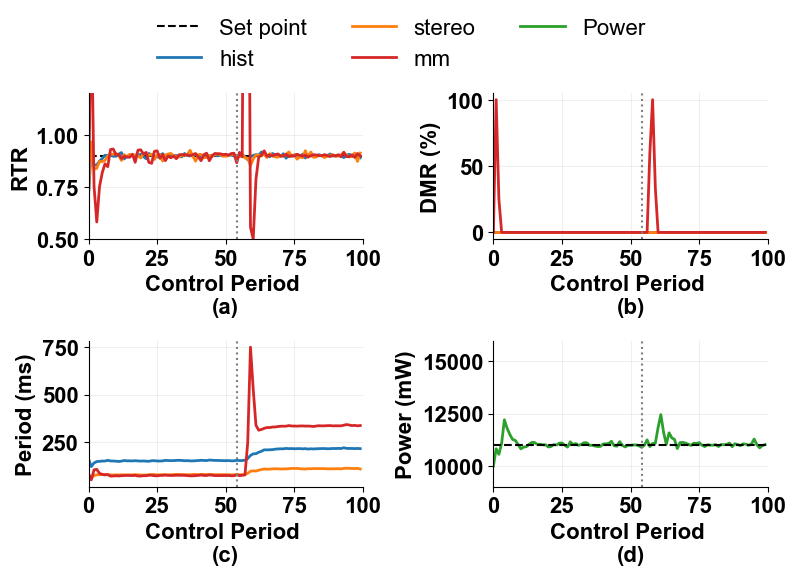

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.png

Saved all figures to:
C:\Users\tiare\Desktop\plot\figures\mm_interrupt_template_style


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D

# =========================================================
# FONT
# =========================================================
try:
    font_path = "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf"
    font_manager.fontManager.addfont(font_path)
except Exception:
    pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# CONFIG
# =========================================================
SAVE_DIR = Path("figures/mm_interrupt_template_style")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RTR_SETPOINT = 0.90
POWER_SETPOINT = 11000
CHANGE_PERIOD = 54

WARMUP_SKIP = 0
MAX_PERIODS = 100

TASK_NAMES = ["hist", "stereo", "mm"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red"]

FIGSIZE_2X2 = (8, 6)
FIGSIZE_1X2 = (8, 3.2)

DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0

RUNS = {
    "openloop": {
        "root": Path("03_interrupt_tests/logs/openloop_interrupt/hist_stereo_mm_test/setpoint_0.90_0.90_0.90"),
        "prefix": "OpenLoop",
        "save_name": "mm_interrupt_openloop_11000_0.90.pdf",
        "plot_type": "openloop",
    },
    "FC_GPU": {
        "root": Path("03_interrupt_tests/logs/FC_interrupt/hist_stereo_mm_test/setpoint_0.90_0.90_0.90"),
        "prefix": "FC_GPU",
        "save_name": "mm_interrupt_FC_11000_0.90.pdf",
        "plot_type": "period",
    },
    "DFS": {
        "root": Path("03_interrupt_tests/logs/DFS_interrupt/hist_stereo_mm_test/setpoint_0.90_0.90_0.90"),
        "prefix": "DFS",
        "save_name": "mm_interrupt_DFS_11000_0.90.pdf",
        "plot_type": "frequency",
    },
    "LQR": {
        "root": Path("03_interrupt_tests/logs/LQR_interrupt/hist_stereo_mm_test/setpoint_0.90_0.90_0.90"),
        "prefix": "LQR",
        "save_name": "mm_interrupt_LQR_11000_0.90.pdf",
        "plot_type": "period",
    },
}

# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_run(root: Path, prefix: str):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"{prefix}_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_period.txt")
        )

    power = clean_positive(
        read_data(root / f"{prefix}_finalpowervalues.txt")
    )

    freq = clean_positive(
        read_data(root / f"{prefix}_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def style_ax(ax):
    ax.axvline(
        x=CHANGE_PERIOD,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def plot_rtr(ax, data, panel):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period(ax, data, panel):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_frequency(ax, freq, panel):
    if freq is not None:
        ax.plot(
            freq,
            linewidth=LINEWIDTH,
            color="tab:purple",
            label="GPU Freq",
        )

    ax.set_ylabel("GPU Freq (MHz)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_power(ax, power, panel):
    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    ax.axhline(
        y=POWER_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim([9000, 16000])


def global_legend(fig, axs, include_power=True, include_freq=False, ncol=3):
    handles, labels = axs[0].get_legend_handles_labels()

    if include_power:
        power_handle = Line2D([0], [0], color="tab:green", linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")

    if include_freq:
        freq_handle = Line2D([0], [0], color="tab:purple", linewidth=LINEWIDTH)
        handles.append(freq_handle)
        labels.append("GPU Freq")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=ncol,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# PLOTTERS
# =========================================================
def plot_openloop(method, cfg):
    data, power, freq = load_run(cfg["root"], cfg["prefix"])

    fig, axs = plt.subplots(1, 2, figsize=FIGSIZE_1X2)
    axs = axs.flatten()

    plot_rtr(axs[0], data, "a")
    plot_power(axs[1], power, "b")

    for ax in axs:
        style_ax(ax)

    global_legend(
        fig,
        axs,
        include_power=True,
        include_freq=False,
        ncol=3,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.78])

    save_fig(fig, SAVE_DIR / cfg["save_name"])


def plot_2x2(method, cfg):
    data, power, freq = load_run(cfg["root"], cfg["prefix"])

    fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
    axs = axs.flatten()

    plot_rtr(axs[0], data, "a")
    plot_dmr(axs[1], data, "b")

    if cfg["plot_type"] == "frequency":
        plot_frequency(axs[2], freq, "c")
        include_freq = True
    else:
        plot_period(axs[2], data, "c")
        include_freq = False

    plot_power(axs[3], power, "d")

    for ax in axs:
        style_ax(ax)

    global_legend(
        fig,
        axs,
        include_power=True,
        include_freq=include_freq,
        ncol=3,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.85])

    save_fig(fig, SAVE_DIR / cfg["save_name"])


# =========================================================
# MAIN
# =========================================================
for method, cfg in RUNS.items():
    print("\n==============================")
    print(method)
    print(cfg["root"])
    print("==============================")

    if not cfg["root"].exists():
        print(f"SKIP missing root: {cfg['root']}")
        continue

    if cfg["plot_type"] == "openloop":
        plot_openloop(method, cfg)
    else:
        plot_2x2(method, cfg)

print("\nSaved all figures to:")
print(SAVE_DIR.resolve())

Root: 03_interrupt_tests\logs\task_arrival_4task_test\hist_stereo_mm_particle\setpoint_11000_0.90_0.90_0.90_0.90
Detected task arrival control period: 57


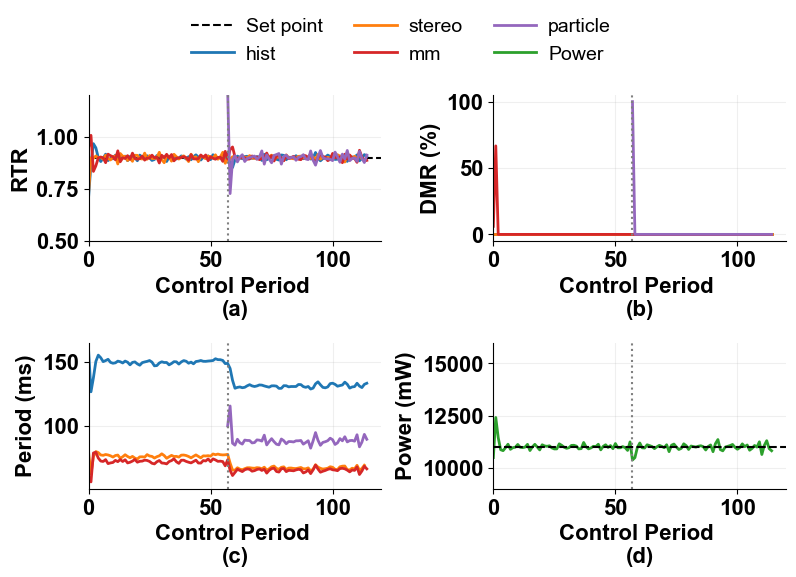

Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.pdf
Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.png


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D
import os

# =========================================================
# FONT
# =========================================================
arial_paths = [
    "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Arial_Bold.ttf",
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/arialbd.ttf",
]

for fp in arial_paths:
    if os.path.exists(fp):
        try:
            font_manager.fontManager.addfont(fp)
        except Exception:
            pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# CONFIG
# =========================================================
SAVE_DIR = Path("03_interrupt_tests/figures/task_arrival_4task_test")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RTR_SETPOINT = 0.90
POWER_SETPOINT = 11000

ROOT = Path(
    "03_interrupt_tests/logs/task_arrival_4task_test/"
    "hist_stereo_mm_particle/"
    "setpoint_11000_0.90_0.90_0.90_0.90"
)

PREFIX = "UNKNOWN"
SAVE_NAME = "task_arrival_4task_test.pdf"

WARMUP_SKIP = 0
MAX_PERIODS = 120

TASK_NAMES = ["hist", "stereo", "mm", "particle"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red", "tab:purple"]

FIGSIZE_2X2 = (8, 6)

DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 14
LINEWIDTH = 2.0

# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_run(root: Path, prefix: str):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"{prefix}_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_period.txt")
        )

        data[name]["exec"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_exec.txt")
        )

        data[name]["response"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_response.txt")
        )

    power = clean_positive(
        read_data(root / f"{prefix}__powercontrolperiod.txt")
    )

    if power is None:
        power = clean_positive(
            read_data(root / f"{prefix}_finalpowervalues.txt")
        )

    freq = clean_positive(
        read_data(root / f"{prefix}_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def detect_task_arrival(data):
    y = data["particle"]["rtr"]
    if y is None:
        return 0

    valid = np.where(np.isfinite(y) & (y > 0))[0]
    if len(valid) == 0:
        return 0

    return int(valid[0])


def style_ax(ax, change_period):
    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def plot_rtr(ax, data, panel, change_period):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel, change_period):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period(ax, data, panel, change_period):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_power(ax, power, panel):
    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    ax.axhline(
        y=POWER_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim([9000, 16000])


def global_legend(fig, axs):
    handles, labels = axs[0].get_legend_handles_labels()

    power_handle = Line2D([0], [0], color="tab:green", linewidth=LINEWIDTH)
    handles.append(power_handle)
    labels.append("Power")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=3,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
        columnspacing=1.6,
        handlelength=2.2,
        handletextpad=0.6,
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# MAIN PLOT
# =========================================================
print("Root:", ROOT)

if not ROOT.exists():
    raise FileNotFoundError(f"Missing log root: {ROOT.resolve()}")

data, power, freq = load_run(ROOT, PREFIX)
CHANGE_PERIOD = detect_task_arrival(data)

print("Detected task arrival control period:", CHANGE_PERIOD)

fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
axs = axs.flatten()

plot_rtr(axs[0], data, "a", CHANGE_PERIOD)
plot_dmr(axs[1], data, "b", CHANGE_PERIOD)
plot_period(axs[2], data, "c", CHANGE_PERIOD)
plot_power(axs[3], power, "d")

for ax in axs:
    style_ax(ax, CHANGE_PERIOD)

global_legend(fig, axs)

plt.tight_layout(rect=[0, 0, 1, 0.85])

save_fig(fig, SAVE_DIR / SAVE_NAME)

logs\PVR_margin_LQR\hist_stereo_mm\cap_11000_ctrl_10800_0.70_0.70_0.70
mean power: 10836.9485


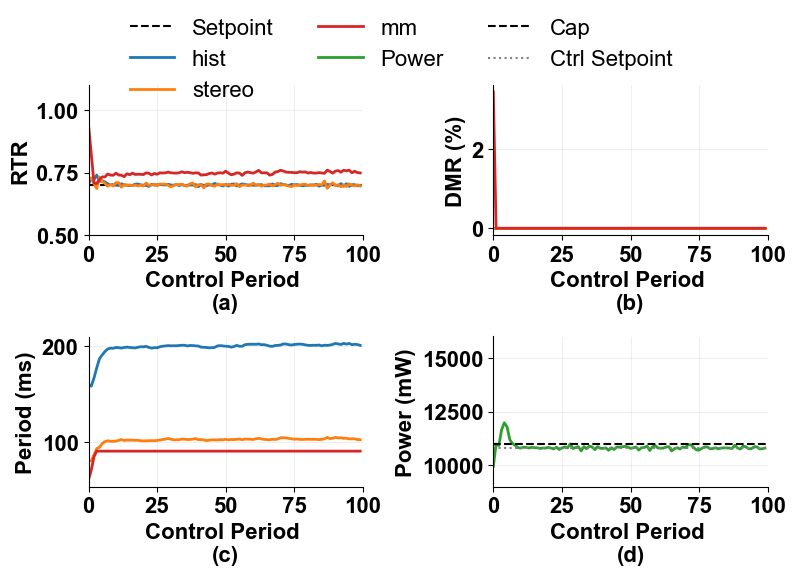

logs\PVR_margin_LQR\hist_stereo_mm\cap_11500_ctrl_11300_0.70_0.70_0.70
mean power: 11317.232499999998


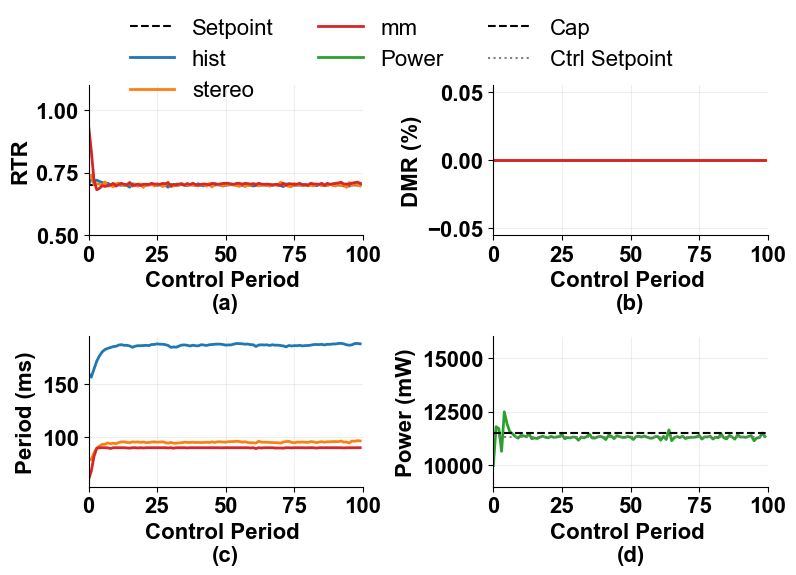

logs\PVR_margin_LQR\hist_stereo_mm\cap_12000_ctrl_11800_0.70_0.70_0.70
mean power: 11766.312500000002


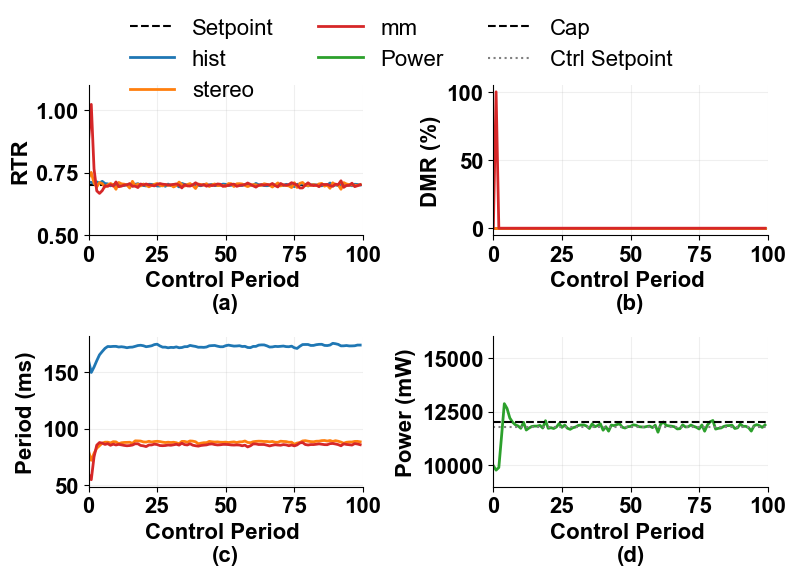

logs\PVR_margin_LQR\hist_stereo_mm\cap_12500_ctrl_12300_0.70_0.70_0.70
mean power: 12259.990000000002


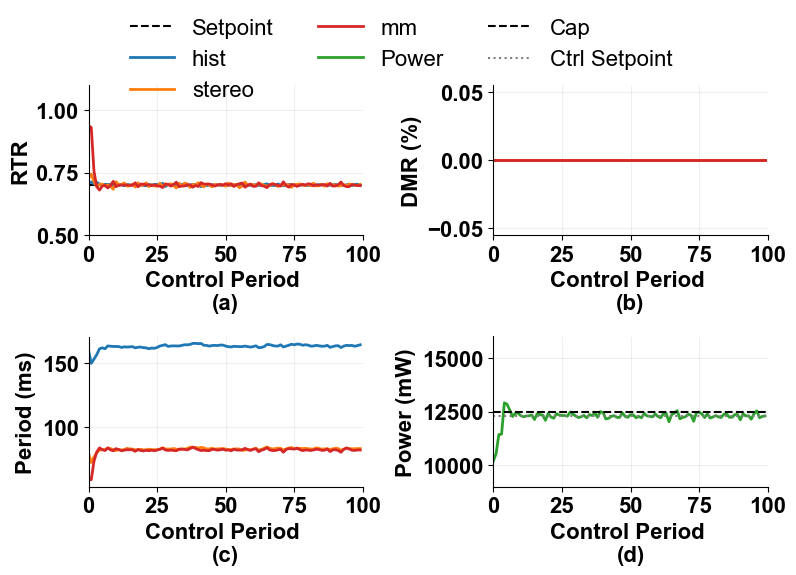

logs\PVR_margin_LQR\hist_stereo_mm\cap_13000_ctrl_12800_0.70_0.70_0.70
mean power: 12735.708999999999


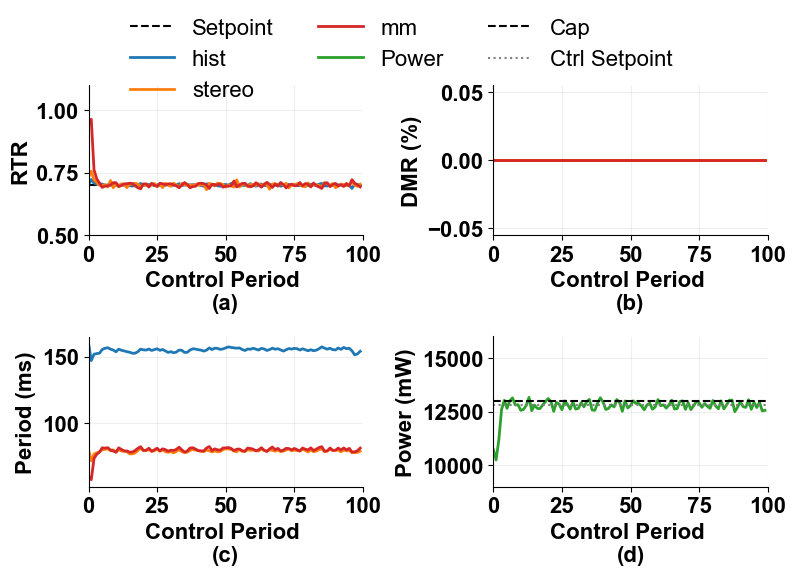

logs\PVR_margin_LQR\hist_stereo_mm\cap_11000_ctrl_10800_0.75_0.75_0.75
mean power: 10833.309000000001


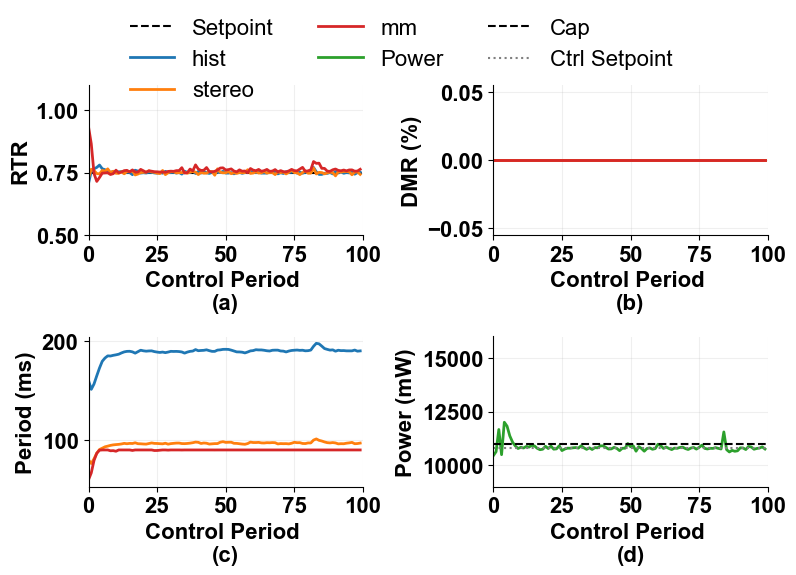

logs\PVR_margin_LQR\hist_stereo_mm\cap_11500_ctrl_11300_0.75_0.75_0.75
mean power: 11304.233


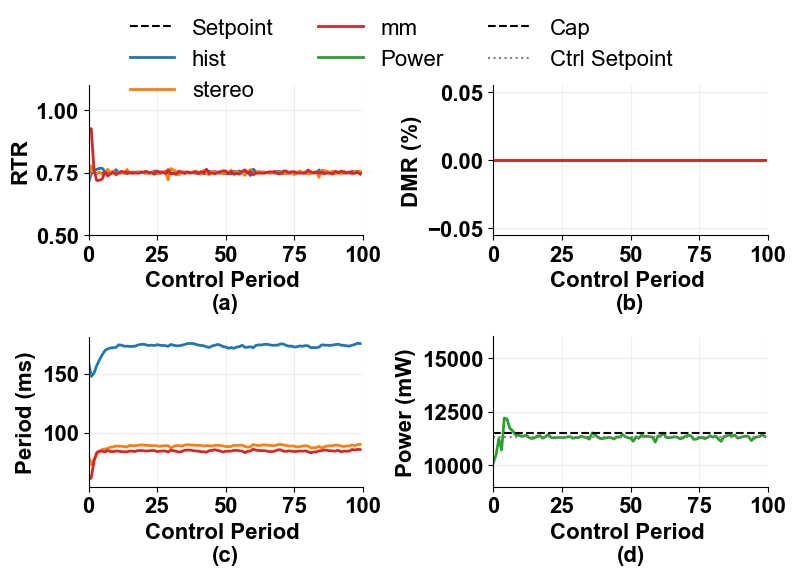

logs\PVR_margin_LQR\hist_stereo_mm\cap_12000_ctrl_11800_0.75_0.75_0.75
mean power: 11780.352000000003


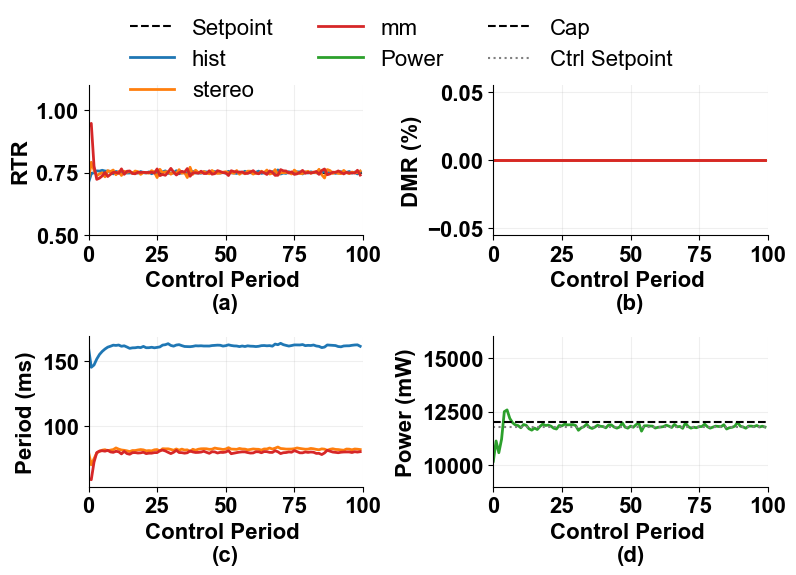

logs\PVR_margin_LQR\hist_stereo_mm\cap_12500_ctrl_12300_0.75_0.75_0.75
mean power: 12256.802999999998


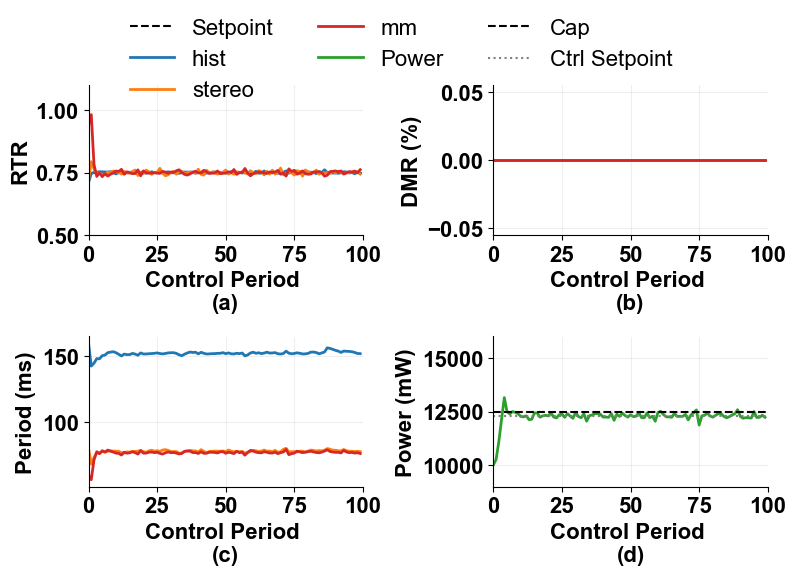

logs\PVR_margin_LQR\hist_stereo_mm\cap_13000_ctrl_12800_0.75_0.75_0.75
mean power: 12733.969000000001


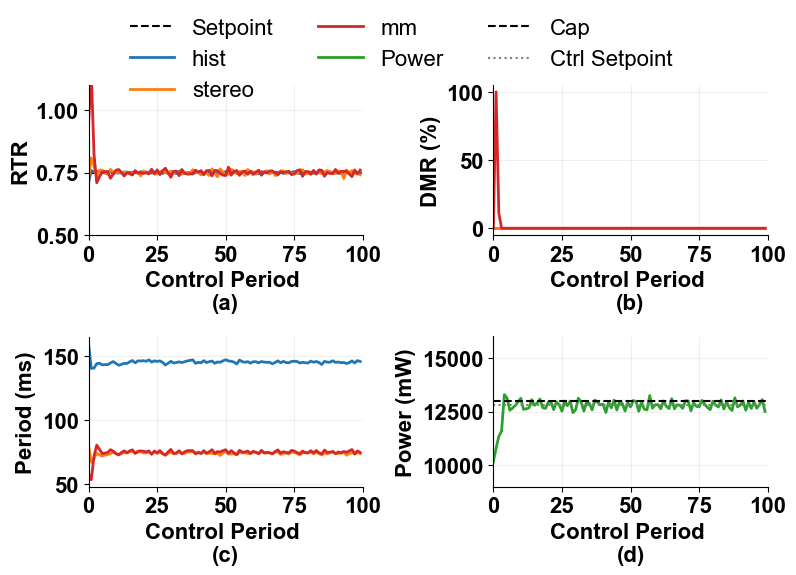

logs\PVR_margin_LQR\hist_stereo_mm\cap_11000_ctrl_10800_0.80_0.80_0.80
mean power: 10832.861499999999


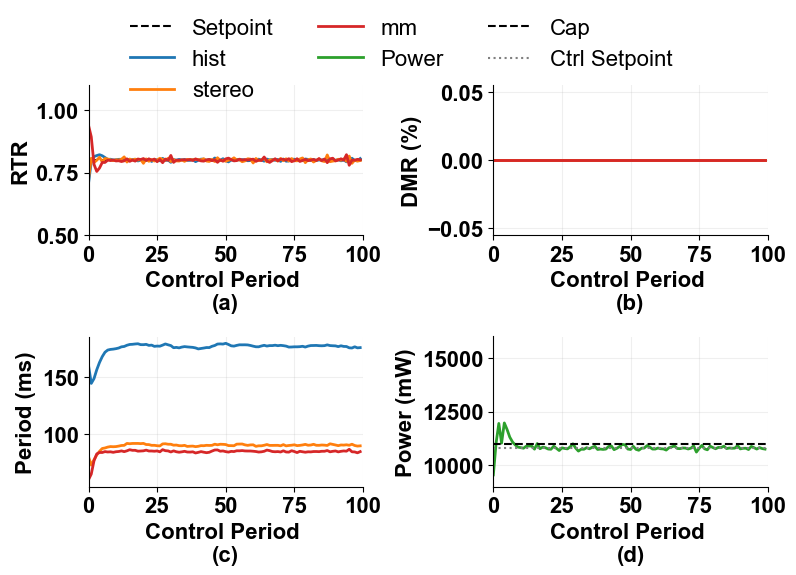

logs\PVR_margin_LQR\hist_stereo_mm\cap_11500_ctrl_11300_0.80_0.80_0.80
mean power: 11306.553


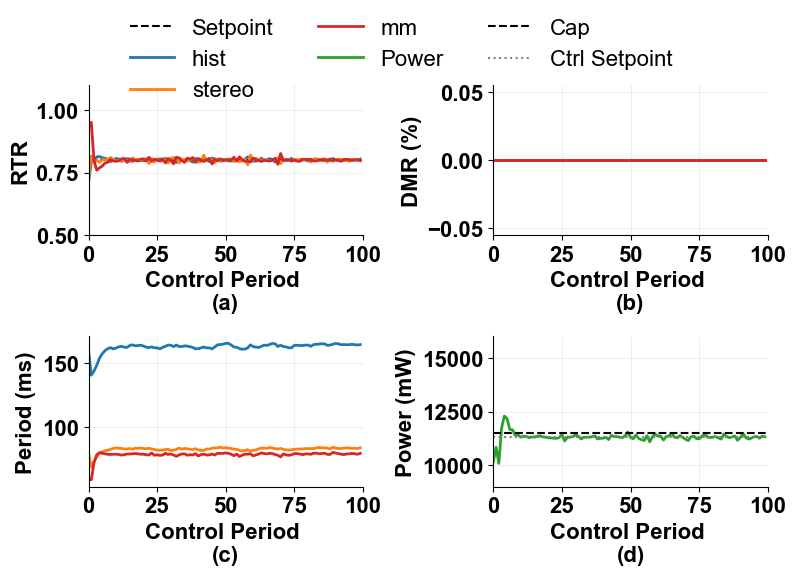

logs\PVR_margin_LQR\hist_stereo_mm\cap_12000_ctrl_11800_0.80_0.80_0.80
mean power: 11789.036499999998


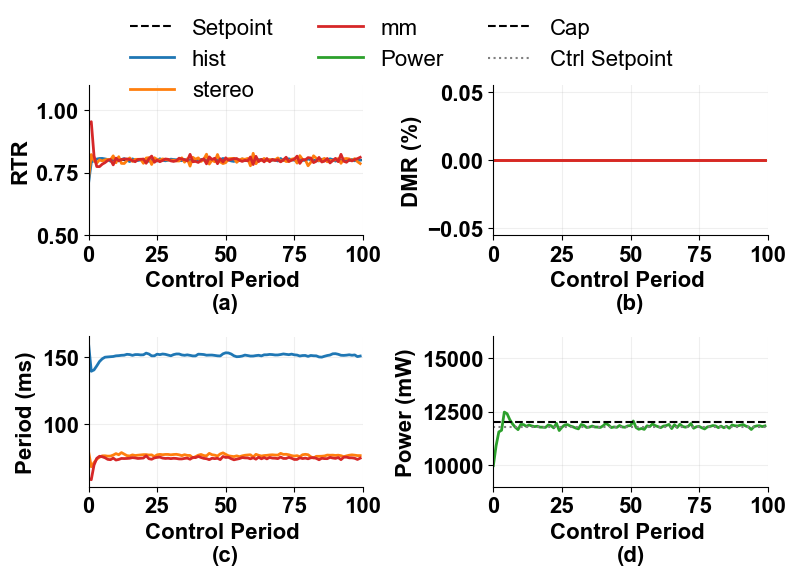

logs\PVR_margin_LQR\hist_stereo_mm\cap_12500_ctrl_12300_0.80_0.80_0.80
mean power: 12240.081


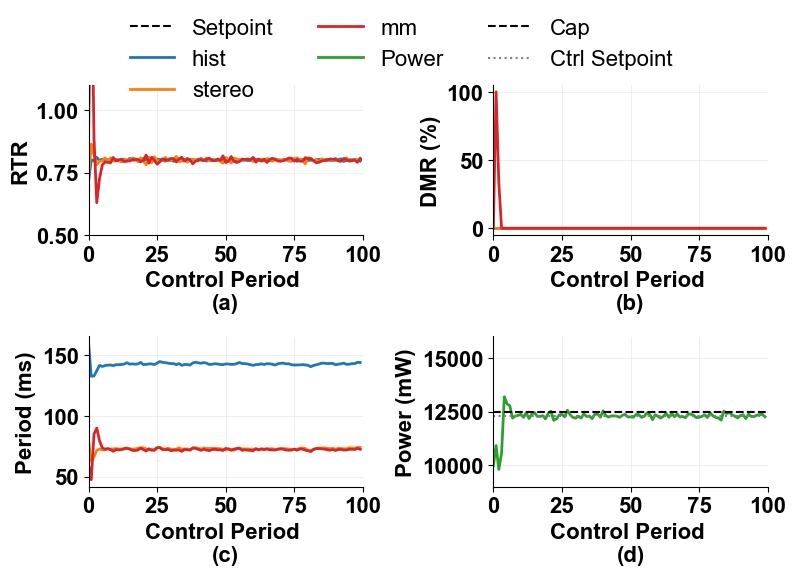

logs\PVR_margin_LQR\hist_stereo_mm\cap_13000_ctrl_12800_0.80_0.80_0.80
mean power: 12713.458999999999


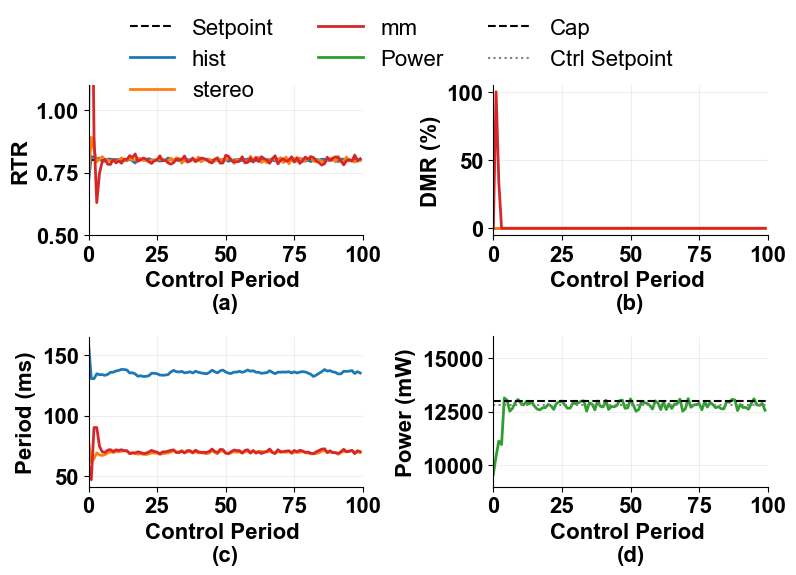

logs\PVR_margin_LQR\hist_stereo_mm\cap_11000_ctrl_10800_0.85_0.85_0.85
mean power: 10827.6245


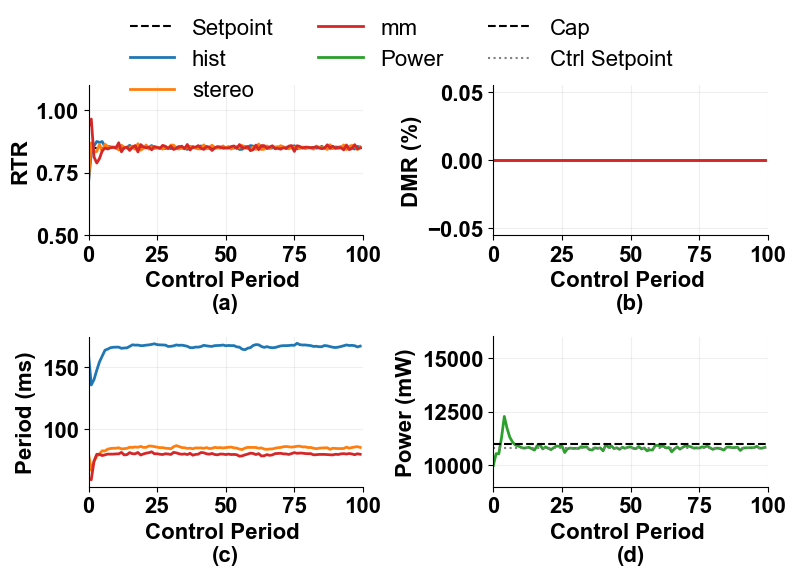

logs\PVR_margin_LQR\hist_stereo_mm\cap_11500_ctrl_11300_0.85_0.85_0.85
mean power: 11314.813999999998


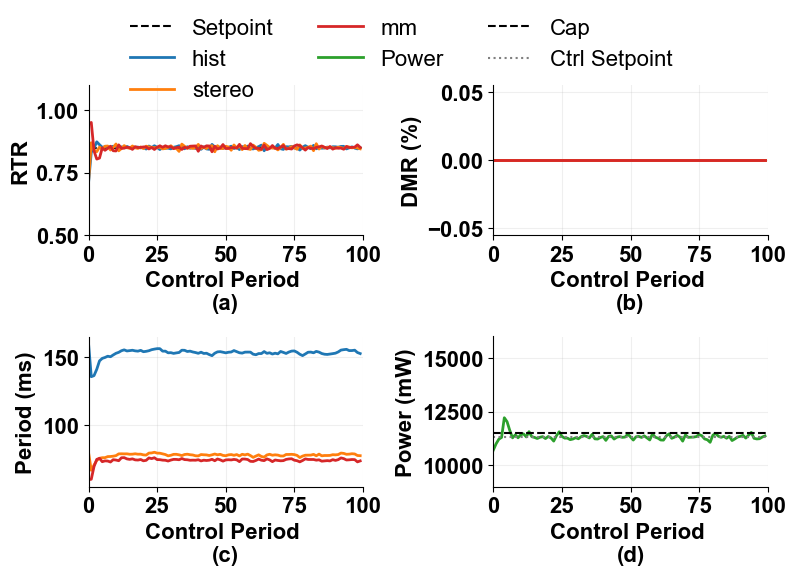

logs\PVR_margin_LQR\hist_stereo_mm\cap_12000_ctrl_11800_0.85_0.85_0.85
mean power: 11779.833


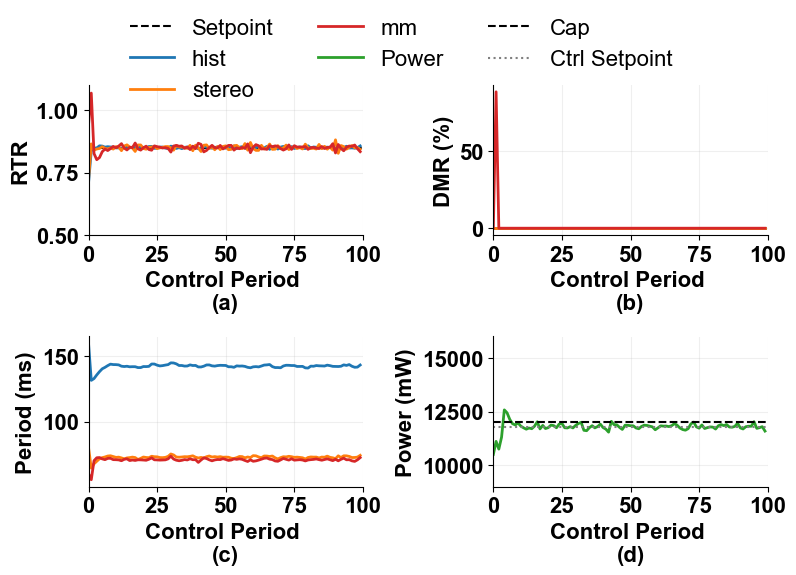

logs\PVR_margin_LQR\hist_stereo_mm\cap_12500_ctrl_12300_0.85_0.85_0.85
mean power: 12273.461000000001


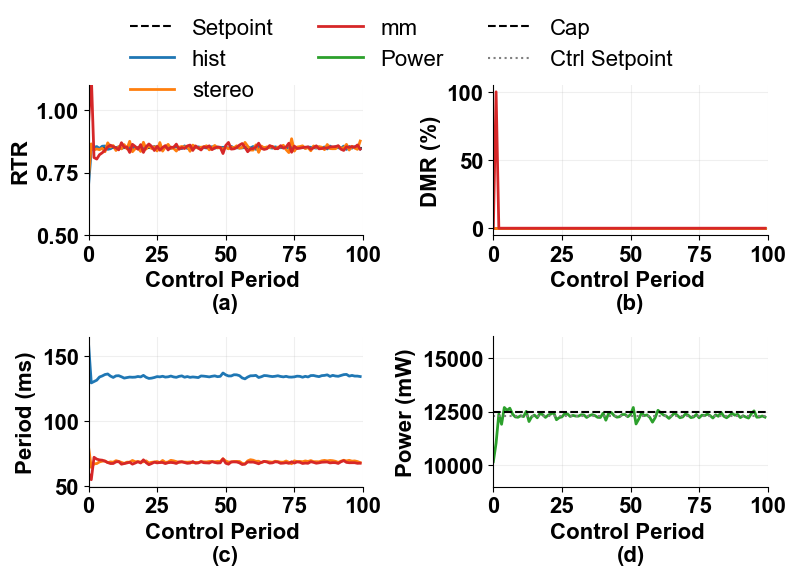

logs\PVR_margin_LQR\hist_stereo_mm\cap_13000_ctrl_12800_0.85_0.85_0.85
mean power: 12727.6105


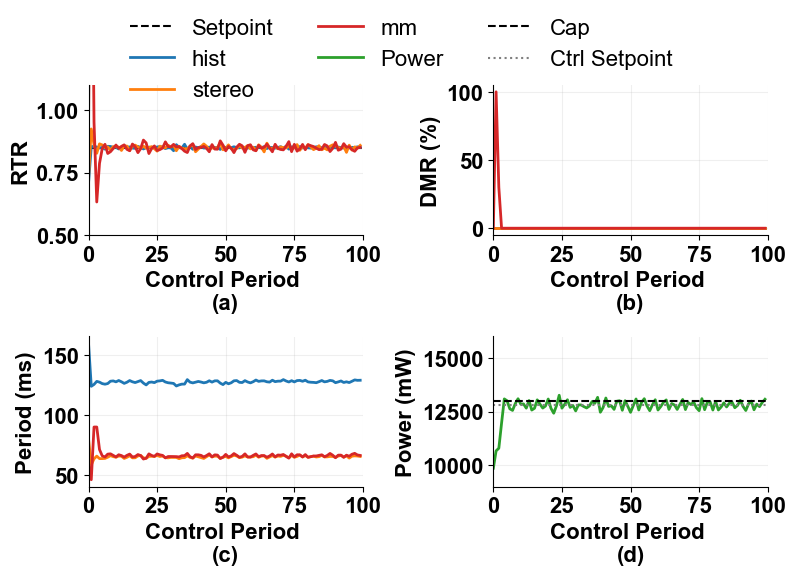

logs\PVR_margin_LQR\hist_stereo_mm\cap_11000_ctrl_10800_0.90_0.90_0.90
mean power: 10834.878


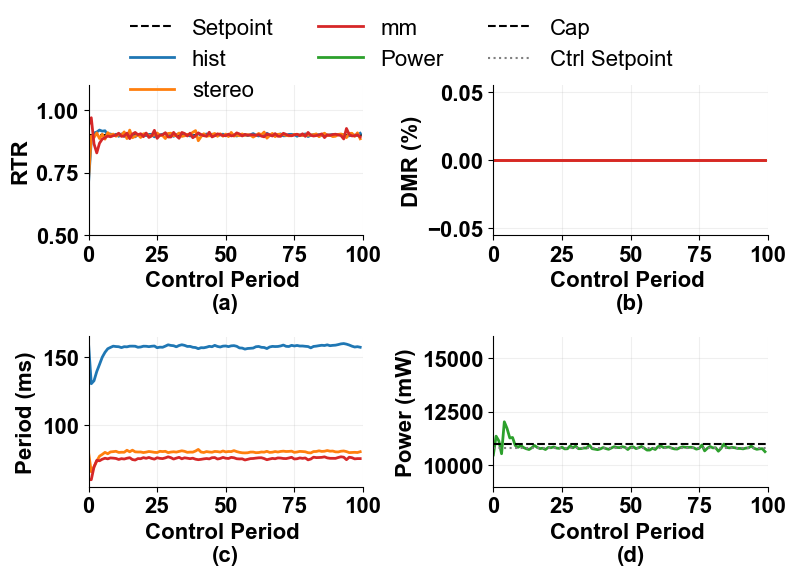

logs\PVR_margin_LQR\hist_stereo_mm\cap_11500_ctrl_11300_0.90_0.90_0.90
mean power: 11303.9795


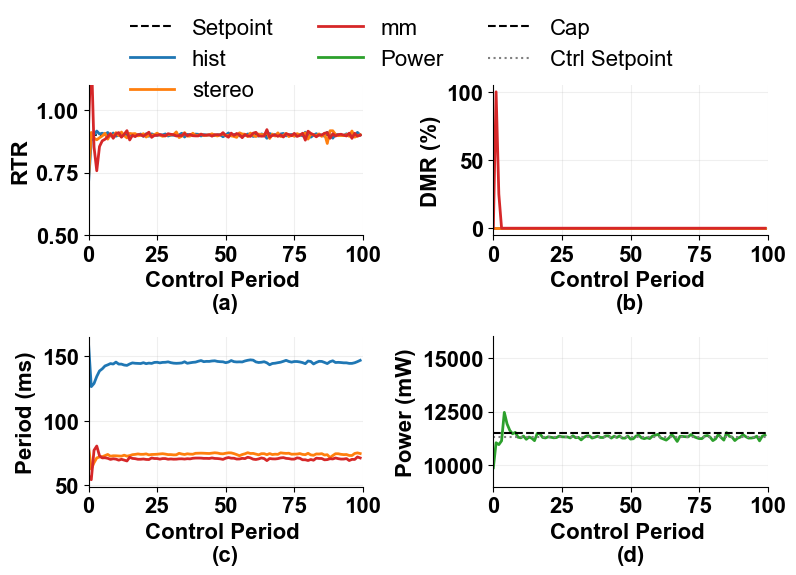

logs\PVR_margin_LQR\hist_stereo_mm\cap_12000_ctrl_11800_0.90_0.90_0.90
mean power: 11770.475999999999


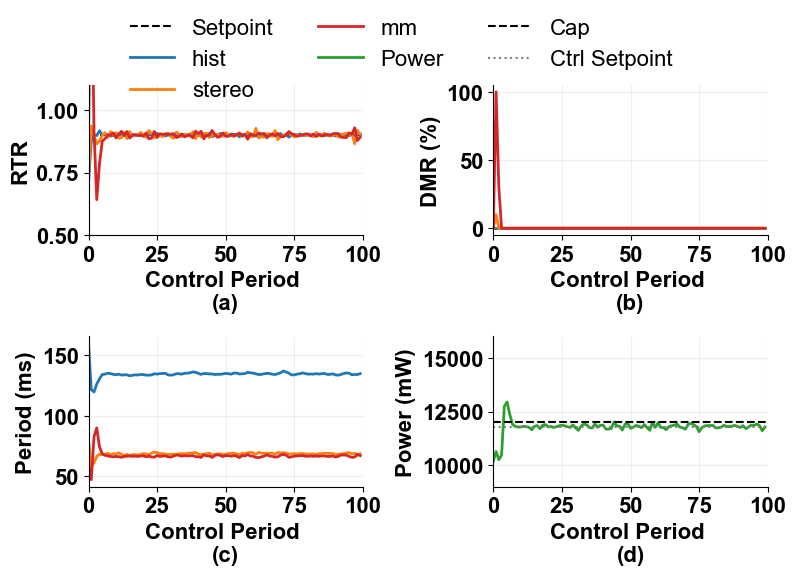

logs\PVR_margin_LQR\hist_stereo_mm\cap_12500_ctrl_12300_0.90_0.90_0.90
mean power: 12270.85


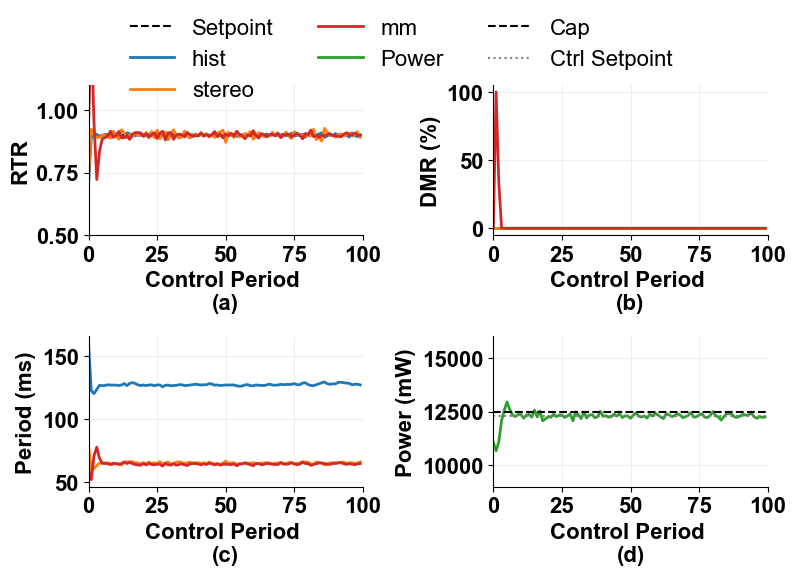

logs\PVR_margin_LQR\hist_stereo_mm\cap_13000_ctrl_12800_0.90_0.90_0.90
mean power: 12737.181


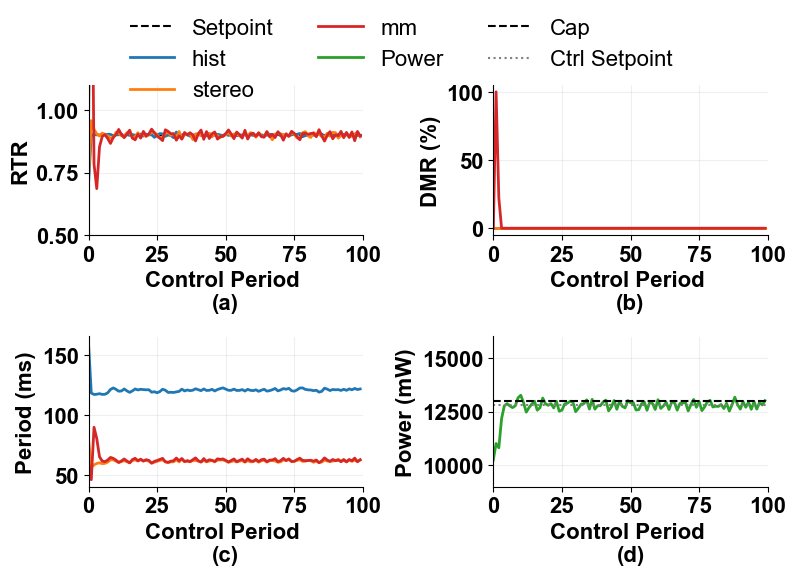

In [1]:
################ PVR MARGIN LQR
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.weight"] = "normal"

# --------- CONFIG ----------
root = Path("logs/PVR_margin_LQR/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
p_setpoint = [11000, 11500, 12000, 12500, 13000]
margin = 200

warmup_skip = 0
max_periods = 100

save_path = Path("figures/PVR_margin_LQR")

task_names = ["hist", "stereo", "mm"]
task_colors = ['tab:blue', 'tab:orange', 'tab:red']

# Styling constants
FIGSIZE = (15, 4)
FIGSIZE = (10, 8)
FIGSIZE = (8, 6)

LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0
# ---------------------------

def read_data(filepath: Path):
    if not filepath.exists():
        return None
    vals = []
    with filepath.open("r") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s))
            except ValueError:
                continue
    return vals if vals else None

def slice_idx(data, start, stop):
    if data is None:
        return None
    n = len(data)
    a = min(max(start, 0), n)
    b = min(max(stop, 0), n)
    return np.asarray(data[a:b], dtype=float)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

for sp in setpoints:
    for power in p_setpoint:
        ctrl_power = power - margin

        run_dir = root / f"cap_{power}_ctrl_{ctrl_power}_{sp:.2f}_{sp:.2f}_{sp:.2f}"

        if not run_dir.exists() or not any(run_dir.iterdir()):
            print(f"SKIP missing/empty: {run_dir}")
            continue

        print(run_dir)

        data = {name: {} for name in task_names}

        for i, name in enumerate(task_names, 1):
            t_id = f"t{i}"
            data[name]['rtr'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_rtr.txt"), warmup_skip, max_periods)
            data[name]['dl']  = slice_idx(read_data(run_dir / f"LQR_{t_id}_deadline.txt"), warmup_skip, max_periods)
            data[name]['per'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_period.txt"), warmup_skip, max_periods)
            data[name]['low'] = slice_idx(read_data(run_dir / f"LQR_{t_id}_lowerperiodbound.txt"), warmup_skip, max_periods)
            data[name]['high']= slice_idx(read_data(run_dir / f"LQR_{t_id}_higherperiodbound.txt"), warmup_skip, max_periods)

        pwrs = slice_idx(read_data(run_dir / "LQR_finalpowervalues.txt"), warmup_skip, max_periods)

        fig, axs = plt.subplots(2, 2, figsize=FIGSIZE)
        axs = axs.flatten()

        # (1) RTR
        ax = axs[0]
        ax.axhline(y=sp, color='black', linestyle='--', linewidth=1.5, label="Setpoint")
        for name, color in zip(task_names, task_colors):
            if data[name]['rtr'] is not None:
                ax.plot(data[name]['rtr'], linewidth=LINEWIDTH, label=name, color=color)
        ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(a)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_ylim(0.5, 1.1)

        # (2) Deadline
        ax = axs[1]
        for name, color in zip(task_names, task_colors):
            if data[name]['dl'] is not None:
                ax.plot(data[name]['dl'], linewidth=LINEWIDTH, color=color)
        ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(b)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (3) Period
        ax = axs[2]
        for name, color in zip(task_names, task_colors):
            if data[name]['per'] is not None:
                ax.plot(data[name]['per'], linewidth=LINEWIDTH, color=color)
            if data[name]['low'] is not None:
                pass
            if data[name]['high'] is not None:
                pass
        ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(c)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # (4) Power
        ax = axs[3]
        if pwrs is not None:
            ax.plot(pwrs, linewidth=LINEWIDTH, color='tab:green', label='Power')
            print("mean power:", np.mean(pwrs))

        ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_xlabel("Control Period \n(d)", fontsize=LABEL_FONTSIZE, fontweight='bold')

        # Original cap line
        ax.axhline(y=power, color='black', linestyle='--', linewidth=1.5, label="Cap")

        # Controller internal setpoint line
        ax.axhline(y=ctrl_power, color='gray', linestyle=':', linewidth=1.5, label="Ctrl Setpoint")

        ax.set_ylim([9000, 16000])

        # Global Styling
        for ax in axs:
            ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
            for tick in ax.get_xticklabels():
                tick.set_fontweight("bold")
            for tick in ax.get_yticklabels():
                tick.set_fontweight("bold")
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, alpha=0.2)
            ax.set_xlim([0, 100])

        handles, labels = axs[0].get_legend_handles_labels()

        power_handle = Line2D([0], [0], color='tab:green', linewidth=LINEWIDTH)
        handles.append(power_handle)
        labels.append("Power")

        cap_handle = Line2D([0], [0], color='black', linestyle='--', linewidth=1.5)
        handles.append(cap_handle)
        labels.append("Cap")

        ctrl_handle = Line2D([0], [0], color='gray', linestyle=':', linewidth=1.5)
        handles.append(ctrl_handle)
        labels.append("Ctrl Setpoint")

        fig.legend(
            handles,
            labels,
            loc='upper center',
            bbox_to_anchor=(0.5, 0.97),
            ncol=3,
            frameon=False,
            prop={'size': LEGEND_FONTSIZE}
        )

        plt.tight_layout(rect=[0, 0, 1, 0.85])

        fig_path = Path("figures")
        fig_path.mkdir(exist_ok=True)
        save_path.mkdir(exist_ok=True)

        plt.savefig(save_path / f"LQR_cap_{power}_ctrl_{ctrl_power}_rtr_{sp:.2f}.pdf", bbox_inches='tight')
        plt.show()

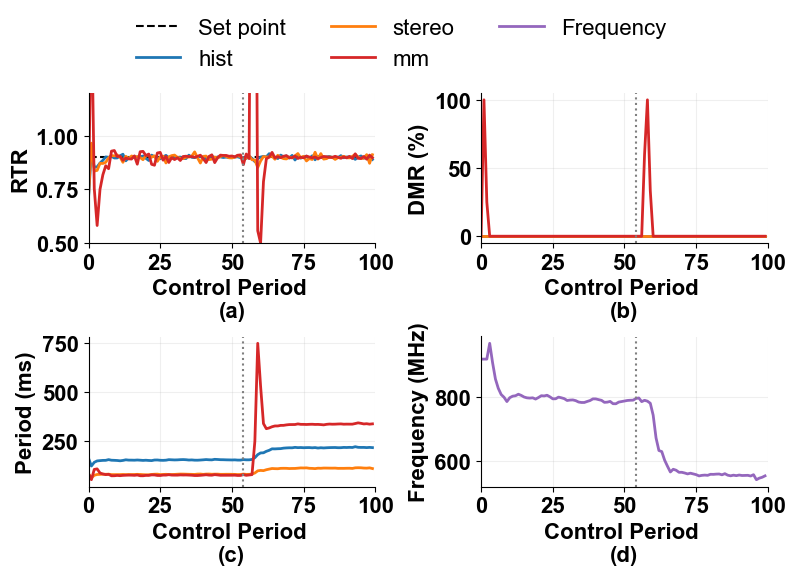

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.png


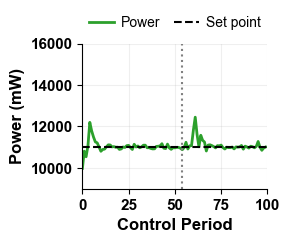

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90_power_only.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90_power_only.png


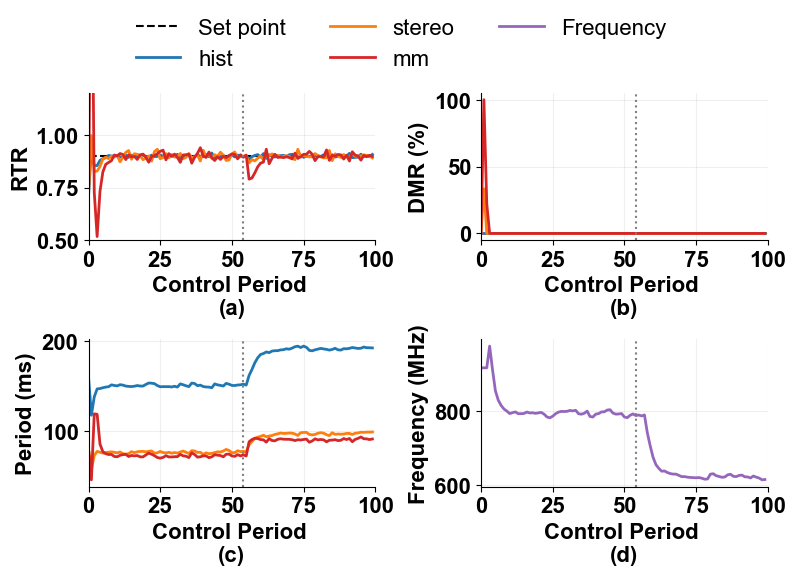

Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90.pdf
Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90.png


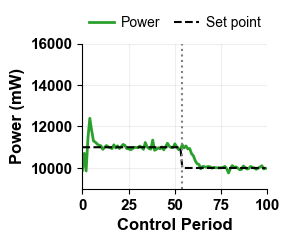

Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90_power_only.pdf
Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90_power_only.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D

# =========================================================
# FONT
# =========================================================
try:
    font_path = "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf"
    font_manager.fontManager.addfont(font_path)
except Exception:
    pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# GLOBAL STYLE
# =========================================================
DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0

FIGSIZE_2X2 = (8, 6)
FIGSIZE_POWER_ONLY = (3, 2.5)

TASK_NAMES = ["hist", "stereo", "mm"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red"]

RTR_SETPOINT = 0.90
WARMUP_SKIP = 0
MAX_PERIODS = 100

# Keep the original plotting alignment from your scripts
CHANGE_PERIOD = 54


# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_lqr_run(root: Path):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"LQR_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"LQR_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"LQR_{tid}_period.txt")
        )

    power = clean_positive(
        read_data(root / "LQR_finalpowervalues.txt")
    )

    freq = clean_positive(
        read_data(root / "LQR_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def style_ax(ax, change_period=CHANGE_PERIOD):
    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def plot_rtr(ax, data, panel):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is not None:
            ax.plot(y, linewidth=LINEWIDTH, label=name, color=color)

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is not None:
            ax.plot(y, linewidth=LINEWIDTH, color=color)

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period(ax, data, panel):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is not None:
            ax.plot(y, linewidth=LINEWIDTH, color=color)

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_frequency(ax, freq, panel):
    if freq is not None:
        ax.plot(
            freq,
            linewidth=LINEWIDTH,
            color="tab:purple",
            label="Frequency",
        )

    ax.set_ylabel("Frequency (MHz)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def global_legend_main(fig, axs):
    handles, labels = axs[0].get_legend_handles_labels()

    freq_handle = Line2D([0], [0], color="tab:purple", linewidth=LINEWIDTH)
    handles.append(freq_handle)
    labels.append("Frequency")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=3,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# MAIN 2x2 FIGURE: (a) RTR, (b) DMR, (c) Period, (d) Frequency
# =========================================================
def make_main_2x2(root, save_path):
    data, power, freq = load_lqr_run(root)

    fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
    axs = axs.flatten()

    plot_rtr(axs[0], data, "a")
    plot_dmr(axs[1], data, "b")
    plot_period(axs[2], data, "c")
    plot_frequency(axs[3], freq, "d")

    for ax in axs:
        style_ax(ax)

    global_legend_main(fig, axs)

    plt.tight_layout(rect=[0, 0, 1, 0.85])
    save_fig(fig, save_path)
    

# =========================================================
# SEPARATE POWER-ONLY FIGURE: figsize=(3, 2.5)
# =========================================================
def make_power_only(root, save_path, power_before=11000, power_after=None):
    data, power, freq = load_lqr_run(root)

    fig, ax = plt.subplots(figsize=FIGSIZE_POWER_ONLY)

    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    if power_after is None:
        ax.axhline(
            y=power_before,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )
    else:
        power_sp = np.full(MAX_PERIODS, power_before, dtype=float)
        power_sp[CHANGE_PERIOD:] = power_after
        ax.plot(
            power_sp,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )

    ax.axvline(
        x=CHANGE_PERIOD,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.set_ylabel("Power (mW)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Control Period", fontsize=12, fontweight="bold")
    ax.set_ylim([9000, 16000])
    ax.set_xlim([0, MAX_PERIODS])

    ax.tick_params(axis="both", labelsize=11)
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")
    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)

    # Same style as main figure: use fig.legend instead of ax.legend
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.60, 0.98),
        ncol=2,
        frameon=False,
        prop={"size": 10},
        columnspacing=1.0,
        handlelength=1.8,
        handletextpad=0.5,
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    save_fig(fig, save_path)


# =========================================================
# FIG. 6: JTPC typical run under workload increase
# =========================================================
fig6_root = Path(
    "03_interrupt_tests/logs/LQR_interrupt/"
    "hist_stereo_mm_test/"
    "setpoint_0.90_0.90_0.90"
)

fig6_save_dir = Path("figures/mm_interrupt_template_style")
fig6_save_dir.mkdir(parents=True, exist_ok=True)

make_main_2x2(
    root=fig6_root,
    save_path=fig6_save_dir / "mm_interrupt_LQR_11000_0.90.pdf",
)

make_power_only(
    root=fig6_root,
    save_path=fig6_save_dir / "mm_interrupt_LQR_11000_0.90_power_only.pdf",
    power_before=11000,
    power_after=None,
)


# =========================================================
# FIG. 8: JTPC runtime power set point change
# =========================================================
fig8_root = Path(
    "04_power_interrupt_tests/logs/power_interrupt_LQR/"
    "hist_stereo_mm/"
    "setpoint_11000_0.90_0.90_0.90"
)

fig8_save_dir = Path("figures/power_interrupt_LQR")
fig8_save_dir.mkdir(parents=True, exist_ok=True)

make_main_2x2(
    root=fig8_root,
    save_path=fig8_save_dir / "power_interrupt_LQR_setpoint_11000_0.90.pdf",
)

make_power_only(
    root=fig8_root,
    save_path=fig8_save_dir / "power_interrupt_LQR_setpoint_11000_0.90_power_only.pdf",
    power_before=11000,
    power_after=10000,
)

Root: 03_interrupt_tests\logs\task_arrival_4task_test\hist_stereo_mm_particle\setpoint_11000_0.90_0.90_0.90_0.90
Detected task arrival control period: 57


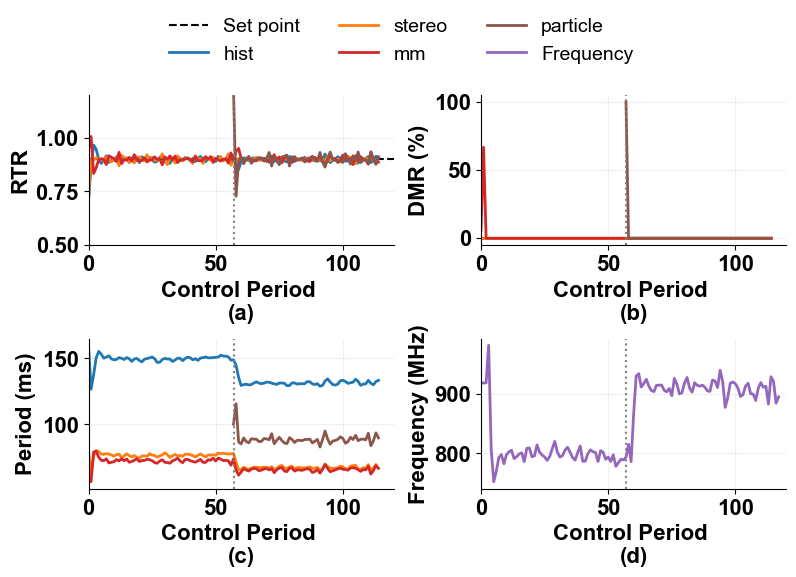

Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.pdf
Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.png


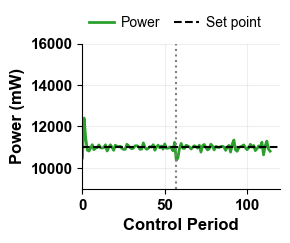

Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test_power_only.pdf
Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test_power_only.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D
import os

# =========================================================
# FONT
# =========================================================
arial_paths = [
    "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Arial_Bold.ttf",
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/arialbd.ttf",
]

for fp in arial_paths:
    if os.path.exists(fp):
        try:
            font_manager.fontManager.addfont(fp)
        except Exception:
            pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# CONFIG
# =========================================================
SAVE_DIR = Path("03_interrupt_tests/figures/task_arrival_4task_test")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RTR_SETPOINT = 0.90
POWER_SETPOINT = 11000

ROOT = Path(
    "03_interrupt_tests/logs/task_arrival_4task_test/"
    "hist_stereo_mm_particle/"
    "setpoint_11000_0.90_0.90_0.90_0.90"
)

PREFIX = "UNKNOWN"
SAVE_NAME = "task_arrival_4task_test.pdf"
POWER_ONLY_SAVE_NAME = "task_arrival_4task_test_power_only.pdf"

WARMUP_SKIP = 0
MAX_PERIODS = 120

TASK_NAMES = ["hist", "stereo", "mm", "particle"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red", "tab:brown"]  # Use a distinct color for particle.

FIGSIZE_2X2 = (8, 6)
FIGSIZE_POWER_ONLY = (3, 2.5)

DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 14
LINEWIDTH = 2.0

# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_run(root: Path, prefix: str):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"{prefix}_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_period.txt")
        )

        data[name]["exec"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_exec.txt")
        )

        data[name]["response"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_response.txt")
        )

    power = clean_positive(
        read_data(root / f"{prefix}__powercontrolperiod.txt")
    )

    if power is None:
        power = clean_positive(
            read_data(root / f"{prefix}_finalpowervalues.txt")
        )

    freq = clean_positive(
        read_data(root / f"{prefix}_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def detect_task_arrival(data):
    y = data["particle"]["rtr"]
    if y is None:
        return 0

    valid = np.where(np.isfinite(y) & (y > 0))[0]
    if len(valid) == 0:
        return 0

    return int(valid[0])


def style_ax(ax, change_period):
    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def plot_rtr(ax, data, panel, change_period):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel, change_period):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period(ax, data, panel, change_period):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_frequency(ax, freq, panel):
    if freq is not None:
        ax.plot(
            freq,
            linewidth=LINEWIDTH,
            color="tab:purple",   # Keep frequency purple.
            label="Frequency",
        )

    ax.set_ylabel("Frequency (MHz)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")


def plot_power_only(ax, power, change_period):
    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    ax.axhline(
        y=POWER_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.set_ylabel("Power (mW)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Control Period", fontsize=12, fontweight="bold")
    ax.set_ylim([9000, 16000])
    ax.set_xlim([0, MAX_PERIODS])

    ax.tick_params(axis="both", labelsize=11)
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")
    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)


def global_legend(fig, axs):
    handles, labels = axs[0].get_legend_handles_labels()

    freq_handle = Line2D([0], [0], color="tab:purple", linewidth=LINEWIDTH)  # Purple
    handles.append(freq_handle)
    labels.append("Frequency")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=3,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# MAIN 2x2 FIGURE: (a) RTR, (b) DMR, (c) Period, (d) Frequency
# =========================================================
print("Root:", ROOT)

if not ROOT.exists():
    raise FileNotFoundError(f"Missing log root: {ROOT.resolve()}")

data, power, freq = load_run(ROOT, PREFIX)
CHANGE_PERIOD = detect_task_arrival(data)

print("Detected task arrival control period:", CHANGE_PERIOD)

fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
axs = axs.flatten()

plot_rtr(axs[0], data, "a", CHANGE_PERIOD)
plot_dmr(axs[1], data, "b", CHANGE_PERIOD)
plot_period(axs[2], data, "c", CHANGE_PERIOD)
plot_frequency(axs[3], freq, "d")

for ax in axs:
    style_ax(ax, CHANGE_PERIOD)

global_legend(fig, axs)

plt.tight_layout(rect=[0, 0, 1, 0.85])
save_fig(fig, SAVE_DIR / SAVE_NAME)

# =========================================================
# SEPARATE POWER-ONLY FIGURE
# =========================================================
fig_power, ax_power = plt.subplots(figsize=FIGSIZE_POWER_ONLY)

plot_power_only(ax_power, power, CHANGE_PERIOD)

handles, labels = ax_power.get_legend_handles_labels()
fig_power.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.60, 0.98),
    ncol=2,
    frameon=False,
    prop={"size": 10},
    columnspacing=1.0,
    handlelength=1.8,
    handletextpad=0.5,
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
save_fig(fig_power, SAVE_DIR / POWER_ONLY_SAVE_NAME)

Root: 03_interrupt_tests\logs\task_arrival_4task_test\hist_stereo_mm_particle\setpoint_11000_0.90_0.90_0.90_0.90
Detected task arrival control period: 57


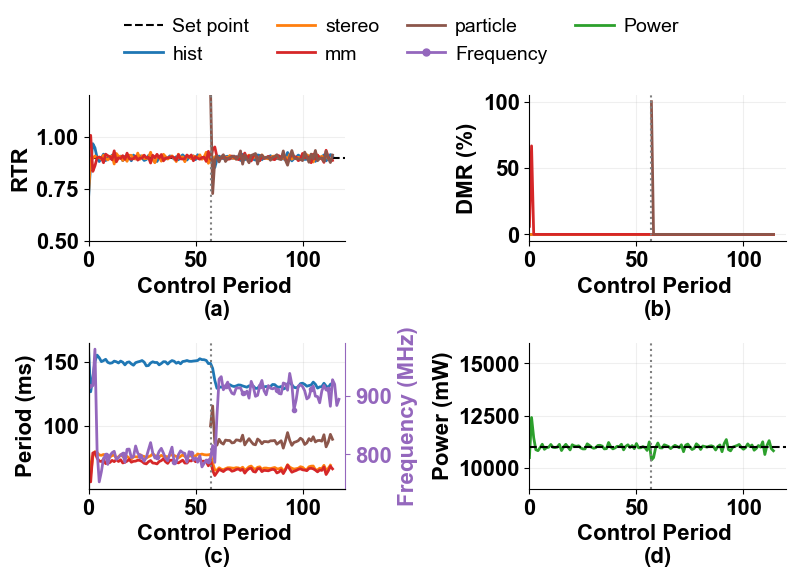

Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.pdf
Saved plot to: 03_interrupt_tests\figures\task_arrival_4task_test\task_arrival_4task_test.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D
import os

# =========================================================
# FONT
# =========================================================
arial_paths = [
    "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Arial_Bold.ttf",
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/arialbd.ttf",
]

for fp in arial_paths:
    if os.path.exists(fp):
        try:
            font_manager.fontManager.addfont(fp)
        except Exception:
            pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# CONFIG
# =========================================================
SAVE_DIR = Path("03_interrupt_tests/figures/task_arrival_4task_test")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RTR_SETPOINT = 0.90
POWER_SETPOINT = 11000

ROOT = Path(
    "03_interrupt_tests/logs/task_arrival_4task_test/"
    "hist_stereo_mm_particle/"
    "setpoint_11000_0.90_0.90_0.90_0.90"
)

PREFIX = "UNKNOWN"
SAVE_NAME = "task_arrival_4task_test.pdf"

WARMUP_SKIP = 0
MAX_PERIODS = 120

TASK_NAMES = ["hist", "stereo", "mm", "particle"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red", "tab:brown"]

FIGSIZE_2X2 = (8, 6)

DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 14
LINEWIDTH = 2.0

# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_run(root: Path, prefix: str):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"{prefix}_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_period.txt")
        )

        data[name]["exec"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_exec.txt")
        )

        data[name]["response"] = clean_positive(
            read_data(root / f"{prefix}_{tid}_response.txt")
        )

    power = clean_positive(
        read_data(root / f"{prefix}__powercontrolperiod.txt")
    )

    if power is None:
        power = clean_positive(
            read_data(root / f"{prefix}_finalpowervalues.txt")
        )

    freq = clean_positive(
        read_data(root / f"{prefix}_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def detect_task_arrival(data):
    y = data["particle"]["rtr"]
    if y is None:
        return 0

    valid = np.where(np.isfinite(y) & (y > 0))[0]
    if len(valid) == 0:
        return 0

    return int(valid[0])


def style_ax(ax, change_period):
    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def plot_rtr(ax, data, panel, change_period):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel, change_period):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period_and_frequency(ax, data, freq, panel, change_period):
    # Left y-axis: Period
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is None:
            continue

        if name == "particle":
            x = np.arange(len(y))
            mask = x >= change_period
            ax.plot(
                x[mask],
                y[mask],
                linewidth=LINEWIDTH,
                color=color,
            )
        else:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")

    # Right y-axis: Frequency
    ax2 = ax.twinx()

    if freq is not None:
        ax2.plot(
            freq,
            linewidth=LINEWIDTH,
            color="tab:purple",
            marker="o",
            markersize=3,
            markevery=8,
            label="Frequency",
        )

    ax2.set_ylabel(
        "Frequency (MHz)",
        fontsize=LABEL_FONTSIZE,
        fontweight="bold",
        color="tab:purple",
    )

    ax2.tick_params(axis="y", labelsize=TICK_FONTSIZE, colors="tab:purple")

    for tick in ax2.get_yticklabels():
        tick.set_fontweight("bold")

    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(True)
    ax2.spines["right"].set_color("tab:purple")

    return ax2


def plot_power(ax, power, panel):
    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    ax.axhline(
        y=POWER_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim([9000, 16000])


def global_legend(fig, axs):
    handles, labels = axs[0].get_legend_handles_labels()

    freq_handle = Line2D(
        [0], [0],
        color="tab:purple",
        linewidth=LINEWIDTH,
        marker="o",
        markersize=5,
    )
    handles.append(freq_handle)
    labels.append("Frequency")

    power_handle = Line2D([0], [0], color="tab:green", linewidth=LINEWIDTH)
    handles.append(power_handle)
    labels.append("Power")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=4,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
        columnspacing=1.4,
        handlelength=2.0,
        handletextpad=0.5,
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# MAIN PLOT
# =========================================================
print("Root:", ROOT)

if not ROOT.exists():
    raise FileNotFoundError(f"Missing log root: {ROOT.resolve()}")

data, power, freq = load_run(ROOT, PREFIX)
CHANGE_PERIOD = detect_task_arrival(data)

print("Detected task arrival control period:", CHANGE_PERIOD)

fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
axs = axs.flatten()

plot_rtr(axs[0], data, "a", CHANGE_PERIOD)
plot_dmr(axs[1], data, "b", CHANGE_PERIOD)
plot_period_and_frequency(axs[2], data, freq, "c", CHANGE_PERIOD)
plot_power(axs[3], power, "d")

for ax in axs:
    style_ax(ax, CHANGE_PERIOD)

global_legend(fig, axs)

plt.tight_layout(rect=[0, 0, 1, 0.85])
save_fig(fig, SAVE_DIR / SAVE_NAME)

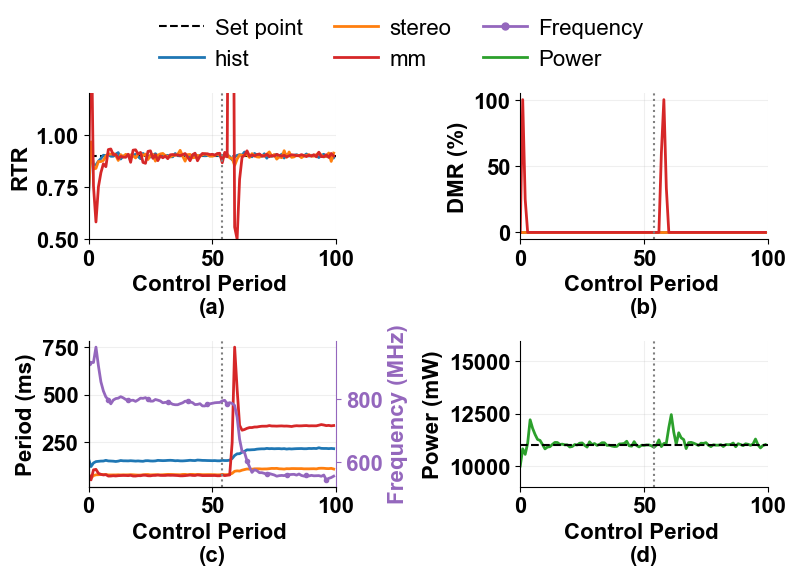

Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.pdf
Saved plot to: figures\mm_interrupt_template_style\mm_interrupt_LQR_11000_0.90.png


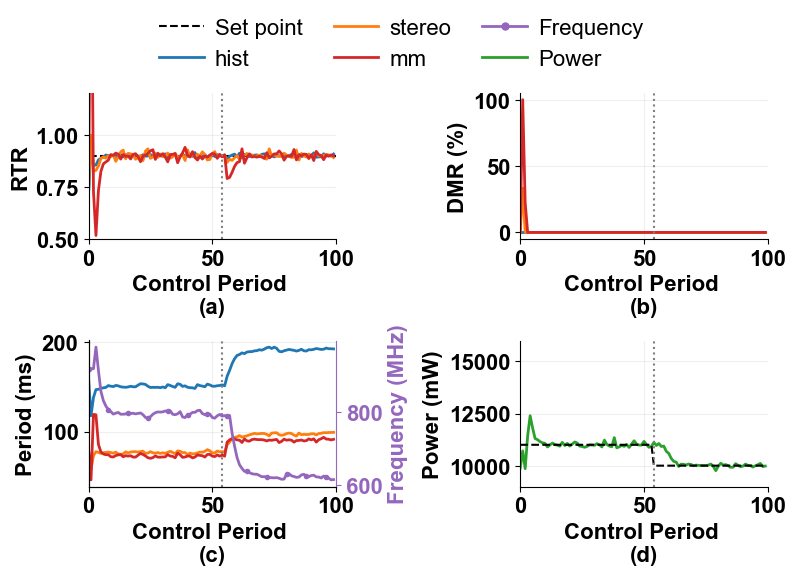

Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90.pdf
Saved plot to: figures\power_interrupt_LQR\power_interrupt_LQR_setpoint_11000_0.90.png


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D

# =========================================================
# FONT
# =========================================================
try:
    font_path = "/usr/share/fonts/truetype/msttcorefonts/Arial.ttf"
    font_manager.fontManager.addfont(font_path)
except Exception:
    pass

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# GLOBAL STYLE
# =========================================================
DPI = 300
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 16
LINEWIDTH = 2.0

FIGSIZE_2X2 = (8, 6)

TASK_NAMES = ["hist", "stereo", "mm"]
TASK_COLORS = ["tab:blue", "tab:orange", "tab:red"]

RTR_SETPOINT = 0.90
WARMUP_SKIP = 0
MAX_PERIODS = 100

# Keep the original plotting alignment from your scripts
CHANGE_PERIOD = 54


# =========================================================
# HELPERS
# =========================================================
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return None

    vals = []
    with filepath.open("r", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s:
                continue
            try:
                vals.append(float(s.split()[0]))
            except ValueError:
                continue

    if not vals:
        return None

    arr = np.asarray(vals, dtype=float)
    return arr[WARMUP_SKIP:WARMUP_SKIP + MAX_PERIODS]


def clean_positive(arr):
    if arr is None:
        return None
    arr = arr.astype(float).copy()
    arr[arr <= 0] = np.nan
    return arr


def load_lqr_run(root: Path):
    data = {name: {} for name in TASK_NAMES}

    for i, name in enumerate(TASK_NAMES, start=1):
        tid = f"t{i}"

        data[name]["rtr"] = clean_positive(
            read_data(root / f"LQR_{tid}_rtr.txt")
        )

        data[name]["dmr"] = read_data(
            root / f"LQR_{tid}_deadline.txt"
        )

        data[name]["period"] = clean_positive(
            read_data(root / f"LQR_{tid}_period.txt")
        )

    power = clean_positive(
        read_data(root / "LQR_finalpowervalues.txt")
    )

    freq = clean_positive(
        read_data(root / "LQR_finalfreqvalsvalues.txt")
    )

    return data, power, freq


def style_ax(ax, change_period=CHANGE_PERIOD):
    ax.axvline(
        x=change_period,
        color="gray",
        linestyle=":",
        linewidth=1.5,
    )

    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.2)
    ax.set_xlim([0, MAX_PERIODS])


def style_right_axis(ax2):
    ax2.tick_params(axis="y", labelsize=TICK_FONTSIZE, colors="tab:purple")

    for tick in ax2.get_yticklabels():
        tick.set_fontweight("bold")

    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(True)
    ax2.spines["right"].set_color("tab:purple")


def plot_rtr(ax, data, panel):
    ax.axhline(
        y=RTR_SETPOINT,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Set point",
    )

    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["rtr"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                label=name,
                color=color,
            )

    ax.set_ylabel("RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(0.5, 1.2)


def plot_dmr(ax, data, panel):
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["dmr"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("DMR (%)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim(-5, 105)


def plot_period_and_frequency(ax, data, freq, panel):
    # Left y-axis: Period
    for name, color in zip(TASK_NAMES, TASK_COLORS):
        y = data[name]["period"]
        if y is not None:
            ax.plot(
                y,
                linewidth=LINEWIDTH,
                color=color,
            )

    ax.set_ylabel("Period (ms)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")

    # Right y-axis: Frequency
    ax2 = ax.twinx()

    if freq is not None:
        ax2.plot(
            freq,
            linewidth=LINEWIDTH,
            color="tab:purple",
            marker="o",
            markersize=3,
            markevery=8,
            label="Frequency",
        )

    ax2.set_ylabel(
        "Frequency (MHz)",
        fontsize=LABEL_FONTSIZE,
        fontweight="bold",
        color="tab:purple",
    )

    style_right_axis(ax2)

    return ax2


def plot_power(ax, power, panel, power_before=11000, power_after=None):
    if power is not None:
        ax.plot(
            power,
            linewidth=LINEWIDTH,
            color="tab:green",
            label="Power",
        )

    if power_after is None:
        ax.axhline(
            y=power_before,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )
    else:
        power_sp = np.full(MAX_PERIODS, power_before, dtype=float)
        power_sp[CHANGE_PERIOD:] = power_after
        ax.plot(
            power_sp,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Set point",
        )

    ax.set_ylabel("Power (mW)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_xlabel(f"Control Period \n({panel})", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylim([9000, 16000])


def global_legend_main(fig, axs):
    handles, labels = axs[0].get_legend_handles_labels()

    freq_handle = Line2D(
        [0], [0],
        color="tab:purple",
        linewidth=LINEWIDTH,
        marker="o",
        markersize=5,
    )
    handles.append(freq_handle)
    labels.append("Frequency")

    power_handle = Line2D(
        [0], [0],
        color="tab:green",
        linewidth=LINEWIDTH,
    )
    handles.append(power_handle)
    labels.append("Power")

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=3,
        frameon=False,
        prop={"size": LEGEND_FONTSIZE},
        columnspacing=1.4,
        handlelength=2.0,
        handletextpad=0.5,
    )


def save_fig(fig, save_path: Path):
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=DPI, bbox_inches="tight")
    png_path = save_path.with_suffix(".png")
    fig.savefig(png_path, dpi=DPI, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Saved plot to: {save_path}")
    print(f"Saved plot to: {png_path}")


# =========================================================
# MAIN 2x2 FIGURE:
# (a) RTR, (b) DMR, (c) Period + Frequency, (d) Power
# =========================================================
def make_main_2x2(root, save_path, power_before=11000, power_after=None):
    data, power, freq = load_lqr_run(root)

    fig, axs = plt.subplots(2, 2, figsize=FIGSIZE_2X2)
    axs = axs.flatten()

    plot_rtr(axs[0], data, "a")
    plot_dmr(axs[1], data, "b")
    plot_period_and_frequency(axs[2], data, freq, "c")
    plot_power(axs[3], power, "d", power_before=power_before, power_after=power_after)

    for ax in axs:
        style_ax(ax)

    global_legend_main(fig, axs)

    plt.tight_layout(rect=[0, 0, 1, 0.85])
    save_fig(fig, save_path)


# =========================================================
# FIG. 6: JTPC typical run under workload increase
# =========================================================
fig6_root = Path(
    "03_interrupt_tests/logs/LQR_interrupt/"
    "hist_stereo_mm_test/"
    "setpoint_0.90_0.90_0.90"
)

fig6_save_dir = Path("figures/mm_interrupt_template_style")
fig6_save_dir.mkdir(parents=True, exist_ok=True)

make_main_2x2(
    root=fig6_root,
    save_path=fig6_save_dir / "mm_interrupt_LQR_11000_0.90.pdf",
    power_before=11000,
    power_after=None,
)


# =========================================================
# FIG. 8: JTPC runtime power set point change
# =========================================================
fig8_root = Path(
    "04_power_interrupt_tests/logs/power_interrupt_LQR/"
    "hist_stereo_mm/"
    "setpoint_11000_0.90_0.90_0.90"
)

fig8_save_dir = Path("figures/power_interrupt_LQR")
fig8_save_dir.mkdir(parents=True, exist_ok=True)

make_main_2x2(
    root=fig8_root,
    save_path=fig8_save_dir / "power_interrupt_LQR_setpoint_11000_0.90.pdf",
    power_before=11000,
    power_after=10000,
)